# Formula 1 Podium Prediction — Milestone 1

**Task.** For every driver who starts a Formula 1 race, predict whether he finishes on the podium (top 3), using only information that is known **after qualifying and before the race starts**.

**How to read this notebook**

* The notebook is split into numbered sections that follow the milestone brief (audit → cleaning → data-engineering questions → features → modeling → experiments → explainability → inference).
* Every choice we made is recorded in **`DECISIONS.md`** with an ID like **D7** (D1–D30). Wherever a decision is applied you will see:
  * a callout in the markdown: `🔶 Decision D7 — ...`
  * a comment in the code: `# DECISION D7 → see DECISIONS.md`
* Every markdown section ends with a short **"What this shows"** note so the conclusion is written next to its evidence.
* Wherever a difference between two numbers matters, it comes with a 95% interval from a bootstrap over races (D23), so you can see whether it is real or luck.
* The notebook runs top to bottom with a single **Run All**. It finds the Kaggle dataset automatically, and falls back to a local `data/` folder when run outside Kaggle.

**Contents**

1. Setup and loading the raw tables
2. Audit of the raw data (before cleaning)
3. Cleaning
4. EDA after cleaning (before vs after)
5. Data-engineering questions Q1–Q3
6. Feature engineering (leakage-safe)
7. Train / validation / test split
8. Preprocessing, preprocessing experiments (E1–E4), training-window check
9. Models (grid rule, logistic-regression baseline, random forest, gradient boosting, shallow neural network) and model comparison
10. Feature-group ablation (all five models)
11. Explainability (permutation importance, SHAP, LIME; all five models)
12. Inference functions (one per model)
13. Summary and limitations

## 1. Setup and loading the raw tables

We load all 14 CSV files **as plain text** (`dtype=str`, `keep_default_na=False`).
Loading everything as text means pandas does not guess types or silently turn values into NaN, so the audit below sees the files exactly as they are on disk.

🔶 **Decision D1** — the raw files are never modified. Raw data lives in `raw`, every cleaning step works on copies in `df`. We store a fingerprint (MD5 hash) of every raw file now and check at the end of Section 3 that none of them changed.

> All numbers quoted in the markdown come from the run saved with this notebook. The library versions of that run are printed below; random forest, gradient boosting and the neural network can move slightly under other versions, the cleaning, the data-engineering answers and the logistic regression cannot.

In [1]:
import os, glob, re, json, html, hashlib, warnings, sys, subprocess, importlib.util
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide TensorFlow start-up logs later in the notebook

# SHAP and LIME are needed in Section 11, statsmodels in Q2. Try to install them if missing (on Kaggle this needs Internet ON),
# and stop HERE with a clear message if that fails, instead of crashing in Section 11.
for _pkg in ["shap", "lime", "statsmodels"]:
    if importlib.util.find_spec(_pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)
        importlib.invalidate_caches()             # make a freshly installed package visible to find_spec
    if importlib.util.find_spec(_pkg) is None:
        raise ImportError(f"Package '{_pkg}' is missing and could not be installed. "
                          "On Kaggle: Settings → Internet → On, then Run All again.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, shap, lime
from importlib.metadata import version as _metadata_version

def _version(pkg):
    """Installed version of a package, or 'unknown' if it was installed without metadata."""
    try:
        return _metadata_version(pkg)
    except Exception:
        return "unknown"

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

SEED = 42                      # one seed everywhere so every run gives the same numbers
np.random.seed(SEED)

# Find the data. On Kaggle the dataset is mounted under /kaggle/input/...; prefer the folder of the
# official F1 dataset if several datasets are attached. Anywhere else we expect the 14 CSVs in "data/".
_hits = sorted(glob.glob("/kaggle/input/**/results.csv", recursive=True), key=lambda p: ("formula" not in p.lower(), p))
DATA_DIR = os.path.dirname(_hits[0]) if _hits else "data"
# On Google Colab (no /kaggle/input and no local data/ folder): download version 24 of the dataset (1950-2024) with kagglehub.
if not _hits and not os.path.exists(os.path.join(DATA_DIR, "results.csv")) and "google.colab" in sys.modules:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("rohanrao/formula-1-world-championship-1950-2020/versions/24")

OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    """Save the current figure (used for the report) and show it in the notebook."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=130, bbox_inches="tight")
    plt.show()

TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings",
          "drivers", "driver_standings", "races", "results", "qualifying",
          "lap_times", "pit_stops", "sprint_results", "seasons", "status"]

# DECISION D1 → see DECISIONS.md  (raw files are read-only; fingerprint them, keep an untouched text copy)
def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()
RAW_HASHES = {t: md5(f"{DATA_DIR}/{t}.csv") for t in TABLES}
raw = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}

# The analysis assumes the 1950–2024 release of the dataset (newer seasons would silently land in the test set).
assert raw["races"]["year"].astype(int).max() == 2024, "unexpected dataset version"

print("Data folder:", DATA_DIR)
print("Versions → python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| shap", shap.__version__, "| lime", _version("lime"),
      "| tensorflow", next((v for v in (_version("tensorflow"), _version("tensorflow-cpu")) if v != "unknown"), "unknown"))
overview = pd.DataFrame({t: {"rows": d.shape[0], "columns": d.shape[1]} for t, d in raw.items()}).T
overview.sort_values("rows", ascending=False)

Data folder: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
Versions → python 3.13.18 | pandas 2.3.3 | numpy 2.1.3 | scikit-learn 1.6.1 | shap 0.54.1 | lime 0.2.0.1 | tensorflow 2.21.0


,rows,columns
lap_times,589081,6
driver_standings,34863,7
results,26759,18
constructor_standings,13391,7
constructor_results,12625,5
pit_stops,11371,7
qualifying,10494,9
races,1125,18
drivers,861,9
sprint_results,360,16


## 2. Audit of the raw data (before cleaning)

### 2.1 Placeholder ("sentinel") missing values

In these CSVs a missing value is written as the literal text `\N` (a *sentinel*). Pandas does not know this, so it would treat `\N` as a real string. A few cells are also simply **empty** (`""`), which is a second way of writing "missing". We count both, per column.

30 columns in 6 tables contain placeholders
Empty-string cells (all tables): 68


,table,column,\N cells,empty cells,pct missing
19,qualifying,q3,6819,46,65.418334
21,qualifying,q2,4625,22,44.282447


NaN cells pandas detects in the raw text: 0


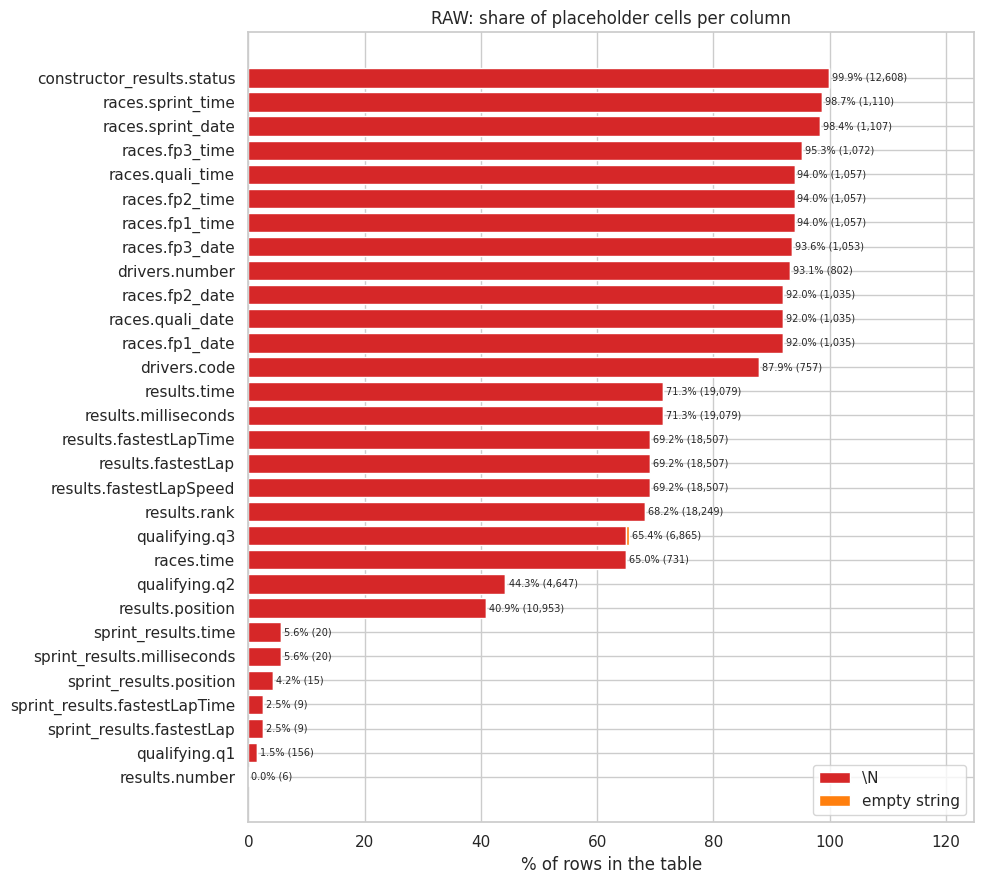

In [2]:
SENT = r"\N"   # the sentinel string used in the Ergast/Kaggle CSVs

# Count '\N' and empty-string cells per column, for every column that has at least one of them.
rows = []
for t, d in raw.items():
    for c in d.columns:
        n_sent, n_empty = int((d[c] == SENT).sum()), int((d[c].str.strip() == "").sum())
        if n_sent + n_empty > 0:
            rows.append({"table": t, "column": c, "\\N cells": n_sent, "empty cells": n_empty,
                         "pct missing": 100 * (n_sent + n_empty) / len(d)})
sent_df = pd.DataFrame(rows).sort_values("pct missing", ascending=False).reset_index(drop=True)

print(f"{len(sent_df)} columns in {sent_df['table'].nunique()} tables contain placeholders")
print("Empty-string cells (all tables):", int(sent_df["empty cells"].sum()))
display(sent_df[sent_df["empty cells"] > 0])
# Pandas itself sees no missing values at all in the raw text -> these are "hidden" missing values.
print("NaN cells pandas detects in the raw text:", sum(int(d.isna().sum().sum()) for d in raw.values()))

plot_df = sent_df.assign(label=sent_df["table"] + "." + sent_df["column"]).sort_values("pct missing")
fig, ax = plt.subplots(figsize=(10, max(4, 0.3 * len(plot_df))))
ax.barh(plot_df["label"], 100 * plot_df["\\N cells"] / plot_df["label"].map(lambda l: len(raw[l.split(".")[0]])),
        color="tab:red", label="\\N")
ax.barh(plot_df["label"], 100 * plot_df["empty cells"] / plot_df["label"].map(lambda l: len(raw[l.split(".")[0]])),
        left=100 * plot_df["\\N cells"] / plot_df["label"].map(lambda l: len(raw[l.split(".")[0]])), color="tab:orange", label="empty string")
for i, (p, n) in enumerate(zip(plot_df["pct missing"], plot_df["\\N cells"] + plot_df["empty cells"])):
    ax.text(p + 0.5, i, f"{p:.1f}% ({n:,})", va="center", fontsize=7)
ax.set_xlim(0, plot_df["pct missing"].max() * 1.25)
ax.set_title("RAW: share of placeholder cells per column")
ax.set_xlabel("% of rows in the table"); ax.legend(loc="lower right")
save_fig("01_raw_sentinels")

**What this shows.** Missing values are common but concentrated in a few places: race-session dates and times (`races.fp*`, only recorded recently), finishing times and fastest laps in `results` (empty for anyone who did not finish, and not recorded in early years), and `qualifying.q2/q3` (empty for drivers knocked out in Q1/Q2). These are *structural* missing values: each has a reason, which matters later when we decide how to fill them. The 68 empty strings all sit in `qualifying.q2/q3` of 2023–2024 races; they mean the same as `\N` and are treated the same way.

### 2.2 How the data changes over 75 seasons

Before cleaning anything we look at how the size and shape of a race changed over time. These plots explain most of the cleaning decisions in Section 3.

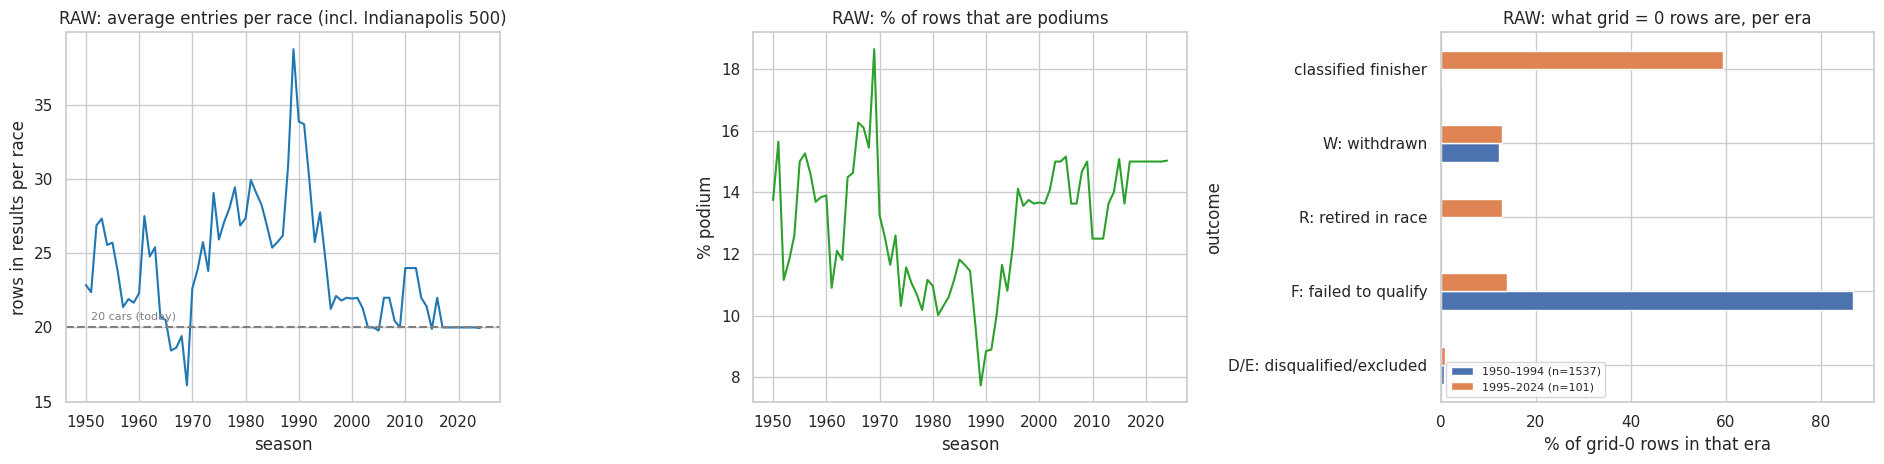

Rows with grid = 0: 1638


era,1950–1994 (n=1537),1995–2024 (n=101)
outcome,,
D/E: disqualified/excluded,12,1
F: failed to qualify,1334,14
R: retired in race,1,13
W: withdrawn,190,13
classified finisher,0,60


In [3]:
# Attach the season (year) and race name to every raw result row.
res_raw = raw["results"].merge(raw["races"][["raceId", "year", "name"]], on="raceId")
res_raw["year"] = res_raw["year"].astype(int)
res_raw = res_raw.merge(raw["status"], on="statusId", how="left")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))

# (a) Entries per race: how many rows each race has in results.csv
per_race = res_raw.groupby(["year", "raceId"]).size().groupby("year").mean()
axes[0].plot(per_race.index, per_race.values, color="tab:blue")
axes[0].axhline(20, ls="--", color="gray"); axes[0].text(1951, 20.5, "20 cars (today)", color="gray", fontsize=8)
axes[0].set_title("RAW: average entries per race (incl. Indianapolis 500)")
axes[0].set_xlabel("season"); axes[0].set_ylabel("rows in results per race")

# (b) Podium share of rows per season: the base rate of the target before cleaning
pod_share = res_raw.assign(p=res_raw["positionOrder"].astype(int) <= 3).groupby("year")["p"].mean()
axes[1].plot(pod_share.index, pod_share.values * 100, color="tab:green")
axes[1].set_title("RAW: % of rows that are podiums")
axes[1].set_xlabel("season"); axes[1].set_ylabel("% podium")

# (c) What does grid = 0 mean? Share of each outcome among grid-0 rows, separately for each era
#     (shares, not counts, so the much smaller modern era stays visible).
g0 = res_raw[res_raw["grid"] == "0"].copy()
g0["era"] = np.where(g0["year"] < 1995, f"1950–1994 (n={int((g0['year'] < 1995).sum())})", f"1995–2024 (n={int((g0['year'] >= 1995).sum())})")
g0["outcome"] = np.select(
    [g0["positionText"].eq("F"), g0["positionText"].eq("W"), g0["positionText"].isin(["D", "E"]), g0["positionText"].eq("R"),
     g0["positionText"].str.isdigit() | g0["positionText"].eq("N")],
    ["F: failed to qualify", "W: withdrawn", "D/E: disqualified/excluded", "R: retired in race", "classified finisher"], default="other")
share = pd.crosstab(g0["outcome"], g0["era"], normalize="columns") * 100
share.plot(kind="barh", ax=axes[2])
axes[2].set_title("RAW: what grid = 0 rows are, per era")
axes[2].set_xlabel("% of grid-0 rows in that era"); axes[2].legend(fontsize=8)
save_fig("02_raw_eras")

print("Rows with grid = 0:", len(g0))
display(pd.crosstab(g0["outcome"], g0["era"]))

**What this shows.**

* (a) Early races had far more entries than the 20 cars of today, peaking above 30 in the late 1980s. (The 1950s line also includes the Indianapolis 500's 33-car fields, see D5.)
* (b) Because of that, only ~8–12% of rows are podiums in the busy eras, against ~15% today.
* (c) **`grid = 0` means two different things.** Before 1995 nearly all grid-0 rows are drivers who *never got onto the grid*: failed to qualify (`F`) or withdrawn (`W`). From 1995 on, most grid-0 rows are classified finishers or retirements, i.e. drivers who **started from the pit lane**. So a grid 0 cannot simply be read as a pit-lane start: the plot shows that holds only for drivers who actually took part. → handled in **D6** and **D7**.

### 2.3 Qualifying coverage per season

The brief warns about *historical qualifying-coverage drift*. We measure it two ways: the share of **races** that have any rows in `qualifying.csv`, and the share of **result rows** (driver-race entries) that have a matching qualifying row.

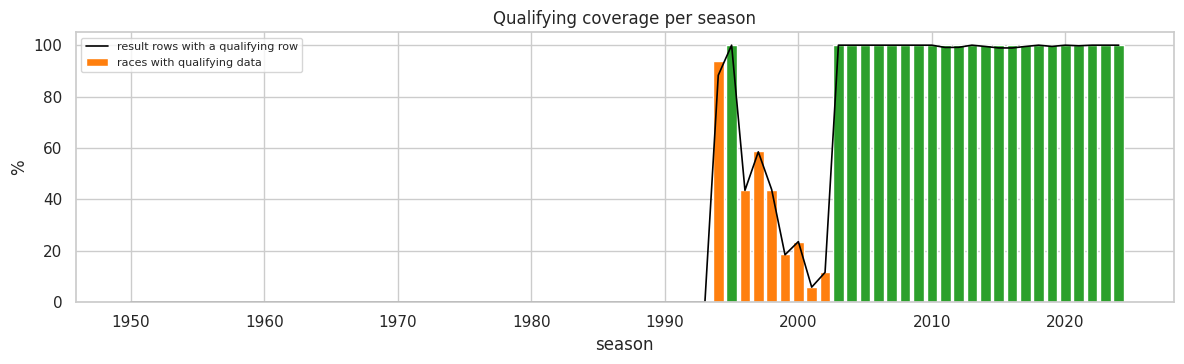

First season with qualifying data: 1994
Seasons with partial race coverage: {1994: 0.94, 1996: 0.44, 1997: 0.59, 1998: 0.44, 1999: 0.19, 2000: 0.24, 2001: 0.06, 2002: 0.12}
Row-level coverage 2003–2024 (min, mean): 0.989 0.997


In [4]:
races_y = raw["races"][["raceId", "year"]].astype({"year": int})
q_races = raw["qualifying"][["raceId"]].drop_duplicates().merge(races_y, on="raceId")
coverage = (q_races.groupby("year").size() / races_y.groupby("year").size()).reindex(races_y["year"].unique()).fillna(0).sort_index()

q_keys = set(zip(raw["qualifying"]["raceId"], raw["qualifying"]["driverId"]))
res_raw["has_quali_row"] = [k in q_keys for k in zip(res_raw["raceId"], res_raw["driverId"])]
row_cov = res_raw.groupby("year")["has_quali_row"].mean()

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(coverage.index, coverage.values * 100, color=np.where(coverage.values >= 0.99, "tab:green", "tab:orange"), label="races with qualifying data")
ax.plot(row_cov.index, row_cov.values * 100, color="black", lw=1.2, label="result rows with a qualifying row")
ax.set_title("Qualifying coverage per season")
ax.set_ylabel("%"); ax.set_xlabel("season"); ax.legend(loc="upper left", fontsize=8)
save_fig("03_qualifying_coverage")

print("First season with qualifying data:", int(coverage[coverage > 0].index.min()))
print("Seasons with partial race coverage:", coverage[(coverage > 0) & (coverage < 0.99)].round(2).to_dict())
print("Row-level coverage 2003–2024 (min, mean):", round(row_cov.loc[2003:].min(), 3), round(row_cov.loc[2003:].mean(), 3))

**What this shows.** `qualifying.csv` is empty before 1994, covers 94% of races in 1994 and all of 1995, only 6–59% of races in 1996–2002, and every race from 2003 onwards (at row level a handful of starters per season still lack a qualifying row, mostly late entries or replacement drivers). So qualifying features will be missing for most rows before 2003, and for those seasons the `grid` column in `results.csv` is the only record of the starting order. We use this when choosing the training window (**D17**) and when handling missing qualifying values (**D15**).

### 2.4 Inconsistent text values

Text columns that are used to group or join rows (driver nationality, circuit country) must spell each value one way only. We check this in code rather than by eye: values that differ only by spaces or upper/lower case are flagged, and the full list of country names is printed so near-duplicates are visible. We also scan **every** text column of every table for HTML codes such as `&amp;`, which appear when a file was copied from a web page.

In [5]:
def spelling_variants(series):
    """Groups of distinct raw values that become identical after stripping spaces and lower-casing."""
    s = pd.Series(series.unique())
    key = s.str.strip().str.casefold()
    groups = s.groupby(key).apply(list)
    return groups[groups.map(len) > 1]

def shared_stem(series, n=6):
    """Groups of distinct values whose first n letters are equal (catches 'Argentine' vs 'Argentinian')."""
    s = pd.Series(sorted(series.str.strip().unique()))
    g = s.groupby(s.str[:n].str.casefold()).apply(list)
    return g[g.map(len) > 1].to_dict()

def acronym_pairs(series):
    """Pairs where a short value starts with the initials of a multi-word value (catches 'United States' vs 'USA')."""
    vals = sorted(series.str.strip().unique())
    return [(v, w) for v in vals if " " in v for w in vals
            if len(w) <= 4 and w.isupper() and w.startswith("".join(x[0] for x in v.split()).upper())]

nat = raw["drivers"]["nationality"]; ctry = raw["circuits"]["country"]
print("Nationality values with leading/trailing spaces:", sorted(v for v in nat.unique() if v != v.strip()))
print("Nationality values differing only by case/spaces:", spelling_variants(nat).to_dict())
print("Nationalities sharing a 6-letter stem:", shared_stem(nat))
print("Country names vs abbreviations:", acronym_pairs(ctry))
print(f"Distinct values before cleaning → nationalities: {nat.nunique()}, countries: {ctry.nunique()}")

HTML_CODE = r"&(?:#\d+|[a-z]+);"          # e.g. "&amp;" where the text should just say "&"
html_hits = {f"{t}.{c}": sorted(d.loc[d[c].str.contains(HTML_CODE), c].unique())
             for t, d in raw.items() for c in d.columns if d[c].str.contains(HTML_CODE).any()}
print("Values with HTML codes, in all tables:", html_hits)

Nationality values with leading/trailing spaces: ['Argentinian ']
Nationality values differing only by case/spaces: {}
Nationalities sharing a 6-letter stem: {'americ': ['American', 'American-Italian'], 'argent': ['Argentine', 'Argentine-Italian', 'Argentinian']}
Country names vs abbreviations: [('United States', 'USA')]
Distinct values before cleaning → nationalities: 43, countries: 35
Values with HTML codes, in all tables: {'constructors.name': ['Lotus-Pratt &amp; Whitney']}


**What this shows.** The code checks flag one nationality with a trailing space (`"Argentinian "`), a stem group in which `"Argentinian"` and `"Argentine"` are the same nationality (the other members, such as `"Argentine-Italian"` or `"American-Italian"`, are real dual nationalities), and a country written both as `"United States"` and as its abbreviation `"USA"`. Left as they are, they would split one country into two groups in the home-race question (Q2). The scan of all text columns also finds one constructor name written with an HTML code, `"Lotus-Pratt &amp; Whitney"`; it would print badly in tables and plots. Fixed in **D2**. Dual or historical nationalities (`"American-Italian"`, `"Argentine-Italian"`, `"East German"`, `"Rhodesian"`) are real values, not spelling errors; how they map to a home country is decided in Q2 (**D10**).

### 2.5 Columns that hold dates and durations as text

The brief asks for *semantic typing*: dates must become dates and durations must become numbers. First we list which columns hold time-like text and what their formats look like.

In [6]:
time_like = []
for t, d in raw.items():
    for c in d.columns:
        vals = d.loc[~d[c].isin([SENT, ""]), c]
        if len(vals) and (vals.str.contains(r"^\+?\d*:?\d+:\d+(?:\.\d+)?$|^\d{4}-\d{2}-\d{2}$|^\+\d+\.\d+$").mean() > 0.5):
            examples = vals.drop_duplicates().head(3).tolist()
            time_like.append({"table": t, "column": c, "non-missing": len(vals), "examples": examples})
display(pd.DataFrame(time_like))

,table,column,non-missing,examples
0,drivers,dob,861,"[1985-01-07, 1977-05-10, 1985-06-27]"
1,races,date,1125,"[2009-03-29, 2009-04-05, 2009-04-19]"
2,races,time,394,"[06:00:00, 09:00:00, 07:00:00]"
3,races,fp1_date,90,"[2021-04-16, 2022-03-18, 2021-03-26]"
4,races,fp1_time,68,"[12:00:00, 14:00:00, 03:00:00]"
5,races,fp2_date,90,"[2021-04-16, 2022-03-18, 2021-03-26]"
6,races,fp2_time,68,"[15:00:00, 17:00:00, 06:00:00]"
7,races,fp3_date,72,"[2021-04-17, 2022-03-19, 2021-03-27]"
8,races,fp3_time,53,"[12:00:00, 14:00:00, 03:00:00]"
9,races,quali_date,90,"[2021-04-17, 2022-03-19, 2021-03-27]"


**What this shows.** Dates (`races.date`, session dates, `drivers.dob`) and four kinds of durations are stored as text: lap times like `1:27.452` (qualifying, fastest laps, lap times), race times like `1:34:50.616` for the winner but **gaps** like `+5.478` for everyone else in the same column, pit-stop durations like `22.4` or `1:02.3`, and time-of-day values (`races.time`, `pit_stops.time`). Section 3.2 converts every one of them.

## 3. Cleaning

### 3.1 Sentinels → real missing values

We re-read every file and tell pandas that `\N` and empty strings mean "missing". `keep_default_na=False` stops pandas from also treating legitimate text such as `"NA"` as missing.

The check below is **cell by cell**: for every column, the set of cells that are NaN after cleaning must be exactly the set of cells that held `\N` or `""` in the raw text — no more, no fewer.

In [7]:
# Clean working copies: '\N' and '' become NaN. The raw dict stays untouched (D1).
df = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv", na_values=[SENT, ""], keep_default_na=False) for t in TABLES}

# Cell-wise check: NaN in the clean copy <=> placeholder in the raw text, in every column of every table.
mismatch = {t: int(((raw[t].isin([SENT, ""])).values != df[t][raw[t].columns].isna().values).sum()) for t in TABLES}
check = pd.DataFrame({"placeholder cells in raw": {t: int(raw[t].isin([SENT, ""]).sum().sum()) for t in TABLES},
                      "NaN cells after cleaning": {t: int(df[t].isna().sum().sum()) for t in TABLES},
                      "cells that disagree": mismatch})
assert sum(mismatch.values()) == 0, "a placeholder was not converted, or a real value became NaN"
check

,placeholder cells in raw,NaN cells after cleaning,cells that disagree
circuits,0,0,0
constructors,0,0,0
constructor_results,12608,12608,0
constructor_standings,0,0,0
drivers,1559,1559,0
driver_standings,0,0,0
races,11349,11349,0
results,122887,122887,0
qualifying,11668,11668,0
lap_times,0,0,0


### 3.2 Semantic typing and text normalisation

Every column listed in 2.5 gets a proper type:

| raw text | becomes | columns |
|---|---|---|
| `2023-07-30` | `datetime` | `races.date`, session dates, `drivers.dob` |
| date + `15:00:00` | one `datetime` (UTC) | `race_start`, `quali_start`, `sprint_start` |
| `1:27.452`, `27.452` | seconds (float) | qualifying `q1–q3`, `fastestLapTime` (results and sprint), `lap_times.time` |
| `1:34:50.616` / `+5.478` | seconds from `milliseconds` | `race_time_sec` (results and sprint) |
| `22.4`, `1:02.3` | seconds (float) | `pit_stops.duration` |
| `17:05:23` | `timedelta` (time of day) | `pit_stops.time` |

The `results.time` column itself stays as text: it mixes the winner's total time with gaps to the winner (`+5.478`), so it is a display string, not one quantity. The same information as a single number is `milliseconds`, which we convert to `race_time_sec`.

A hidden placeholder that is a **number** is also turned into NaN: `results.rank = 0` means no fastest-lap rank was recorded (2011–2024). And one real data error is caught by a plausibility rule: in the 2024 Belgian GP the `milliseconds` column holds the gaps to the winner instead of race times, so those race times are set to missing.

🔶 **Decision D2** — we normalise text values that mean the same thing but are written differently, as found in 2.4: `"Argentinian "` → `"Argentine"`, `"United States"` → `"USA"`, and HTML codes are turned back into characters (`"&amp;"` → `"&"`).

In [8]:
def to_seconds(s):
    """Convert a time string to seconds: '1:27.452' -> 87.452, '27.452' -> 27.452, '1:34:50.616' -> 5690.616, NaN -> NaN."""
    if pd.isna(s):
        return np.nan
    s = str(s).strip()
    try:
        parts = s.split(":")
        if len(parts) == 1:
            return float(parts[0])                                              # ss.xxx
        if len(parts) == 2:
            return int(parts[0]) * 60 + float(parts[1])                         # m:ss.xxx
        if len(parts) == 3:
            return int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2])  # h:mm:ss.xxx
    except ValueError:
        pass
    return np.nan

converted = []   # (table, raw column, new column) -> checked for parse failures below

# --- Dates and start times ------------------------------------------------------
df["races"]["date"] = pd.to_datetime(df["races"]["date"], errors="coerce")
for c in ["fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]:
    df["races"][c] = pd.to_datetime(df["races"][c], errors="coerce")
df["races"]["race_start"] = df["races"]["date"] + pd.to_timedelta(df["races"]["time"])          # NaT where time unknown
df["races"]["quali_start"] = df["races"]["quali_date"] + pd.to_timedelta(df["races"]["quali_time"])
df["races"]["sprint_start"] = df["races"]["sprint_date"] + pd.to_timedelta(df["races"]["sprint_time"])
df["drivers"]["dob"] = pd.to_datetime(df["drivers"]["dob"], errors="coerce")

# --- Lap-time strings -> seconds ------------------------------------------------
for c in ["q1", "q2", "q3"]:
    df["qualifying"][c + "_sec"] = df["qualifying"][c].map(to_seconds); converted.append(("qualifying", c, c + "_sec"))
for t in ["results", "sprint_results"]:
    df[t]["fastestLapTime_sec"] = df[t]["fastestLapTime"].map(to_seconds); converted.append((t, "fastestLapTime", "fastestLapTime_sec"))
df["lap_times"]["time_sec"] = df["lap_times"]["time"].map(to_seconds); converted.append(("lap_times", "time", "time_sec"))
df["pit_stops"]["duration_sec"] = df["pit_stops"]["duration"].map(to_seconds); converted.append(("pit_stops", "duration", "duration_sec"))
df["pit_stops"]["time_of_day"] = pd.to_timedelta(df["pit_stops"]["time"], errors="coerce"); converted.append(("pit_stops", "time", "time_of_day"))

# --- Numeric columns that arrived as text, race time in seconds -----------------
for t in ["results", "sprint_results"]:
    for c in ["number", "position", "fastestLap", "rank", "fastestLapSpeed", "milliseconds"]:
        if c in df[t]:
            df[t][c] = pd.to_numeric(df[t][c], errors="coerce")
    df[t]["race_time_sec"] = df[t]["milliseconds"] / 1000
df["results"]["rank"] = df["results"]["rank"].replace(0, np.nan)        # 0 = no fastest-lap rank recorded
# Impossible race times: no F1 lap takes under 30 s, so a race time below laps × 30 s is a data error
# (2024 Belgian GP: the column holds gaps to the winner in ms). Mark those as missing instead of keeping a wrong number.
bad_time = df["results"]["race_time_sec"] < df["results"]["laps"] * 30
print("Impossible race times set to NaN:", int(bad_time.sum()), "rows in raceIds", sorted(int(x) for x in df["results"].loc[bad_time, "raceId"].unique()))
df["results"].loc[bad_time, "race_time_sec"] = np.nan

# DECISION D2 → see DECISIONS.md  (one spelling per nationality / country)
df["drivers"]["nationality"] = df["drivers"]["nationality"].str.strip().replace({"Argentinian": "Argentine"})
df["circuits"]["country"] = df["circuits"]["country"].str.strip().replace({"United States": "USA"})
df["constructors"]["name"] = df["constructors"]["name"].map(html.unescape)
assert not any(df[t][c].astype(str).str.contains(HTML_CODE).any() for t, c in (k.split(".") for k in html_hits)), "an HTML code is left"
print("HTML codes fixed:", {k: [html.unescape(v) for v in vals] for k, vals in html_hits.items()})

# Check EVERY conversion: a non-missing text value that became NaN would be a parse failure.
fails = pd.DataFrame([{"table": t, "column": c, "non-missing values": int(df[t][c].notna().sum()),
                       "failed to convert": int((df[t][c].notna() & df[t][new].isna()).sum())} for t, c, new in converted])
display(fails)
assert fails["failed to convert"].sum() == 0
# Cross-check: lap times parsed from text agree with the milliseconds column.
assert np.allclose(df["lap_times"]["time_sec"], df["lap_times"]["milliseconds"] / 1000, atol=0.0015)
print(f"Distinct values after D2 → nationalities: {df['drivers']['nationality'].nunique()} (was {raw['drivers']['nationality'].nunique()}), "
      f"countries: {df['circuits']['country'].nunique()} (was {raw['circuits']['country'].nunique()})")

Impossible race times set to NaN: 18 rows in raceIds [1134]
HTML codes fixed: {'constructors.name': ['Lotus-Pratt & Whitney']}


,table,column,non-missing values,failed to convert
0,qualifying,q1,10338,0
1,qualifying,q2,5847,0
2,qualifying,q3,3629,0
3,results,fastestLapTime,8252,0
4,sprint_results,fastestLapTime,351,0
5,lap_times,time,589081,0
6,pit_stops,duration,11371,0
7,pit_stops,time,11371,0


Distinct values after D2 → nationalities: 42 (was 43), countries: 34 (was 35)


**Effect of typing on the values.** Now that durations are numbers, their ranges can be inspected. The plot shows the three duration types as distributions; the table lists their range.

,count,mean,std,min,1%,50%,99%,max
qualifying lap q1 (s),10338.0,88.53,15.39,53.90,65.18,87.14,123.96,1002.64
race lap (s),589081.0,95.80,76.40,55.40,69.85,90.61,158.18,7507.55
pit-stop duration (s),11371.0,85.23,310.43,12.90,16.53,23.61,1848.22,3069.02
"race time, finishers (min)",7662.0,103.34,27.41,3.45,73.75,96.49,233.23,251.51


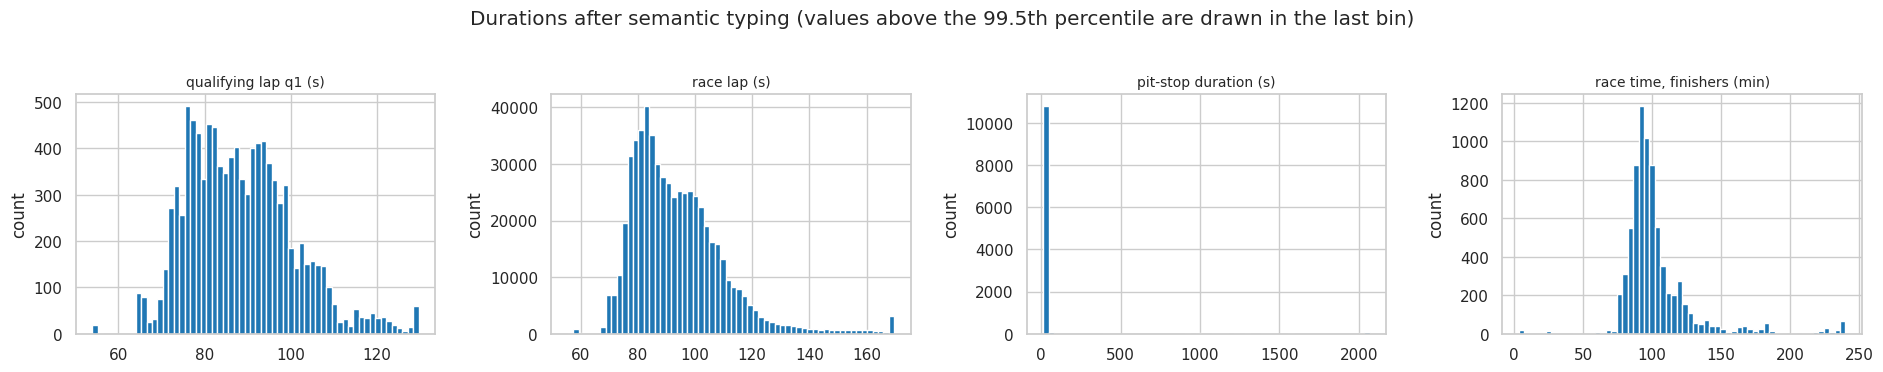

Laps longer than 5 minutes (red-flag / safety-car periods): 708
Pit 'stops' longer than 60 s (red-flag stoppages, repairs): 517


In [9]:
dur = {"qualifying lap q1 (s)": df["qualifying"]["q1_sec"], "race lap (s)": df["lap_times"]["time_sec"],
       "pit-stop duration (s)": df["pit_stops"]["duration_sec"], "race time, finishers (min)": df["results"]["race_time_sec"] / 60}
display(pd.DataFrame({k: v.describe(percentiles=[0.01, 0.5, 0.99]) for k, v in dur.items()}).T.round(2))
fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, (k, v) in zip(axes, dur.items()):
    v = v.dropna()
    ax.hist(v.clip(upper=v.quantile(0.995)), bins=60, color="tab:blue")
    ax.set_title(k, fontsize=10); ax.set_ylabel("count")
fig.suptitle("Durations after semantic typing (values above the 99.5th percentile are drawn in the last bin)", y=1.03)
save_fig("04_durations_typed")
print("Laps longer than 5 minutes (red-flag / safety-car periods):", int((df["lap_times"]["time_sec"] > 300).sum()))
print("Pit 'stops' longer than 60 s (red-flag stoppages, repairs):", int((df["pit_stops"]["duration_sec"] > 60).sum()))

**What this shows.** Every text value converted without failures. The typed values have sensible ranges: qualifying and race laps cluster between ~60 and ~120 s, normal pit stops take 20–30 s. The long tails are real events, not errors: laps over 5 minutes are red-flag or safety-car periods, and "pit stops" over a minute are red-flag stoppages or repairs. We keep them as they are, because none of these columns is used as a model feature (they are all post-race information, see Section 6).

### 3.3 Primary and foreign keys

A **primary key** must be unique and never empty. A **foreign key** must point to a row that exists in its parent table. If a foreign key points nowhere, a join would silently drop or duplicate rows. Because the surrogate IDs (`resultId`, `qualifyId`, …) are unique by construction, we also check the **natural keys** that the joins actually use, and a few **reverse** links.

In [10]:
PK = {
    "circuits": ["circuitId"], "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"], "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"], "driver_standings": ["driverStandingsId"],
    "races": ["raceId"], "results": ["resultId"], "qualifying": ["qualifyId"],
    "sprint_results": [c for c in ["sprintResultId", "resultId"] if c in df["sprint_results"].columns][:1],
    "seasons": ["year"], "status": ["statusId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
NATURAL = {   # keys our joins rely on (results is NOT here: its (raceId, driverId) duplicates are handled in 3.5)
    "qualifying": ["raceId", "driverId"], "races": ["year", "round"], "driver_standings": ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"], "sprint_results": ["raceId", "driverId"],
}
pk_report = pd.DataFrame([{"table": t, "key": "+".join(cols), "kind": kind,
                           "rows_with_null_key": int(df[t][cols].isna().any(axis=1).sum()),
                           "duplicate_key_rows": int(df[t].duplicated(cols, keep=False).sum())}
                          for kind, keys in [("primary", PK), ("natural", NATURAL)] for t, cols in keys.items()])
pk_report["valid"] = (pk_report["rows_with_null_key"] == 0) & (pk_report["duplicate_key_rows"] == 0)
display(pk_report)

# (child table, foreign key column(s), parent table, parent key column(s))
FK = [("races", "year", "seasons", "year"), ("races", "circuitId", "circuits", "circuitId"),
      ("results", "raceId", "races", "raceId"), ("results", "driverId", "drivers", "driverId"),
      ("results", "constructorId", "constructors", "constructorId"), ("results", "statusId", "status", "statusId"),
      ("qualifying", "raceId", "races", "raceId"), ("qualifying", "driverId", "drivers", "driverId"),
      ("qualifying", "constructorId", "constructors", "constructorId"),
      ("sprint_results", "raceId", "races", "raceId"), ("sprint_results", "driverId", "drivers", "driverId"),
      ("sprint_results", "constructorId", "constructors", "constructorId"), ("sprint_results", "statusId", "status", "statusId"),
      ("lap_times", "raceId", "races", "raceId"), ("lap_times", "driverId", "drivers", "driverId"),
      ("pit_stops", "raceId", "races", "raceId"), ("pit_stops", "driverId", "drivers", "driverId"),
      ("driver_standings", "raceId", "races", "raceId"), ("driver_standings", "driverId", "drivers", "driverId"),
      ("constructor_standings", "raceId", "races", "raceId"), ("constructor_standings", "constructorId", "constructors", "constructorId"),
      ("constructor_results", "raceId", "races", "raceId"), ("constructor_results", "constructorId", "constructors", "constructorId"),
      # composite links: every lap / pit stop / qualifying row belongs to a driver who has a result in that race
      ("lap_times", ["raceId", "driverId"], "results", ["raceId", "driverId"]),
      ("pit_stops", ["raceId", "driverId"], "results", ["raceId", "driverId"]),
      ("qualifying", ["raceId", "driverId"], "results", ["raceId", "driverId"])]

def orphans(child, col, parent, pcol):
    if isinstance(col, list):
        parent_keys = set(map(tuple, df[parent][pcol].values))
        return int(sum(tuple(k) not in parent_keys for k in df[child][col].values))
    return int((~df[child][col].dropna().isin(df[parent][pcol])).sum())

fk_report = pd.DataFrame([{"child": c, "foreign_key": "+".join(col) if isinstance(col, list) else col, "parent": p,
                           "rows_checked": len(df[c]), "orphans": orphans(c, col, p, pcol)} for c, col, p, pcol in FK])
fk_report["valid"] = fk_report["orphans"] == 0
display(fk_report)
print("Races with no result rows:", int((~df["races"]["raceId"].isin(df["results"]["raceId"])).sum()))
print("All keys valid:", bool(pk_report["valid"].all()), "| all foreign keys reconcile:", bool(fk_report["valid"].all()))

,table,key,kind,rows_with_null_key,duplicate_key_rows,valid
0,circuits,circuitId,primary,0,0,True
1,constructors,constructorId,primary,0,0,True
2,constructor_results,constructorResultsId,primary,0,0,True
3,constructor_standings,constructorStandingsId,primary,0,0,True
4,drivers,driverId,primary,0,0,True
5,driver_standings,driverStandingsId,primary,0,0,True
6,races,raceId,primary,0,0,True
7,results,resultId,primary,0,0,True
8,qualifying,qualifyId,primary,0,0,True
9,sprint_results,resultId,primary,0,0,True


,child,foreign_key,parent,rows_checked,orphans,valid
0,races,year,seasons,1125,0,True
1,races,circuitId,circuits,1125,0,True
2,results,raceId,races,26759,0,True
3,results,driverId,drivers,26759,0,True
4,results,constructorId,constructors,26759,0,True
5,results,statusId,status,26759,0,True
6,qualifying,raceId,races,10494,0,True
7,qualifying,driverId,drivers,10494,0,True
8,qualifying,constructorId,constructors,10494,0,True
9,sprint_results,raceId,races,360,0,True


Races with no result rows: 0
All keys valid: True | all foreign keys reconcile: True


**What this shows.** Every primary and natural key is unique and non-null, every foreign key resolves to an existing parent row (0 orphans in all 26 relationships), every lap, pit stop and qualifying row belongs to a driver with a result in that race, and every race has results. Joins between these tables are therefore safe: they cannot create orphan rows or duplicate rows.

`results` passes its primary-key check (`resultId` is unique) even though the same *driver* can appear twice in one race. That is a different kind of duplicate, handled in 3.5.

### 3.4 Grouping the status values

`status` says why a driver's race ended (139 labels in the Kaggle version of the dataset). We need it to define who was on the grid (3.6) and to answer Q3 on mechanical retirements. Every label is assigned to exactly **one** category by an explicit list (no "everything else" default), and an assertion checks that no label is left out or listed twice.

🔶 **Decision D3** — status categories. The guiding rule comes from the brief: *mechanical = a component of the car failed; not a crash, not the driver, not a regulation decision.* A label is only `mechanical` if the label itself names a failed component. Labels that describe **damage that is usually caused by contact or by the pit crew** (wheels, tyres, wings, bodywork, debris) go to `ambiguous`, so tyre, wheel and wing labels are treated the same way.

| category | meaning | examples |
|---|---|---|
| `finished` | reached the chequered flag (incl. *Not classified*: running at the end but too far behind to be classified) | Finished, +1 Lap, +2 Laps, Not classified |
| `did_not_qualify` | eliminated in qualifying | Did not qualify, Did not prequalify, 107% Rule |
| `withdrawn` | withdrew; whether he started is decided per row (3.6) | Withdrew |
| `mechanical` | the label names a failed car component | Engine, Gearbox, Hydraulics, Brakes, Power Unit, Electrical, Fuel pump, Seat, Safety belt… |
| `accident_driver` | crash, driver error or driver's health | Accident, Collision, Spun off, Collision damage, Injury, Illness |
| `regulation` | a regulation decision | Disqualified, Excluded, Underweight |
| `team_operational` | a pit-stop or refuelling error by the team | Wheel nut, Fuel rig, Refuelling |
| `ambiguous` | cause cannot be told from the label | Retired, Puncture, Tyre, Wheel, Front/Rear wing, Undertray, Damage, Debris, Out of fuel, Stalled |

In Q3 we report the strict rate (`mechanical` only) and check with the broad rate (adding `ambiguous`) whether the answer depends on this choice.

In [11]:
# DECISION D3 → see DECISIONS.md  (explicit status -> category mapping, every label exactly once)
FINISHED_RE = re.compile(r"^(Finished|Lapped|\+\d+ Laps?)$")
STATUS_GROUPS = {
    "finished": {"Not classified"},                 # + every "+N Laps" / Finished / Lapped via the regex
    "did_not_qualify": {"Did not qualify", "Did not prequalify", "107% Rule"},
    "withdrawn": {"Withdrew", "Did not start"},
    "regulation": {"Disqualified", "Excluded", "Underweight"},
    "accident_driver": {"Accident", "Collision", "Spun off", "Collision damage", "Fatal accident", "Injury", "Injured",
                        "Eye injury", "Illness", "Driver unwell", "Physical"},
    "team_operational": {"Wheel nut", "Fuel rig", "Refuelling"},
    "ambiguous": {"Retired", "Puncture", "Tyre puncture", "Tyre", "Wheel", "Wheel rim", "Front wing", "Rear wing",
                  "Broken wing", "Undertray", "Damage", "Debris", "Out of fuel", "Stalled", "Handling",
                  "Not restarted", "Safety", "Safety concerns"},
    "mechanical": {"Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension",
                   "Brakes", "Differential", "Overheating", "Mechanical", "Driver Seat", "Driveshaft", "Fuel pressure",
                   "Water pressure", "Throttle", "Steering", "Technical", "Electronics", "Heat shield fire", "Exhaust",
                   "Oil leak", "Water leak", "Fuel pump", "Track rod", "Oil pressure", "Engine fire", "Pneumatics",
                   "Fire", "Wheel bearing", "Fuel system", "Oil line", "Launch control", "Fuel", "Power loss",
                   "Vibrations", "Drivetrain", "Ignition", "Chassis", "Battery", "Halfshaft", "Crankshaft",
                   "Alternator", "Safety belt", "Oil pump", "Fuel leak", "Injection", "Distributor", "Turbo",
                   "CV joint", "Water pump", "Spark plugs", "Fuel pipe", "Oil pipe", "Axle", "Water pipe", "Magneto",
                   "Supercharger", "Engine misfire", "Power Unit", "ERS", "Brake duct", "Seat", "Cooling system"},
}
label_to_cat = {lab: cat for cat, labs in STATUS_GROUPS.items() for lab in labs}
assert sum(len(v) for v in STATUS_GROUPS.values()) == len(label_to_cat), "a label is listed in two categories"

def status_category(s):
    return "finished" if FINISHED_RE.match(s) else label_to_cat.get(s)

df["status"]["category"] = df["status"]["status"].map(status_category)
unmapped = df["status"].loc[df["status"]["category"].isna(), "status"].tolist()
assert not unmapped, f"status labels without a category: {unmapped}"

# Full mapping, with how often each category occurs in results (so it can be checked and quoted).
use = df["results"]["statusId"].map(df["status"].set_index("statusId")["category"]).value_counts()
for cat in STATUS_GROUPS:
    labels = sorted(df["status"].loc[df["status"]["category"] == cat, "status"], key=lambda x: (x[0] != "+", x))
    shown = labels if len(labels) < 20 else labels[:6] + ["…"] + labels[-3:]
    print(f"[{cat}] {len(labels)} labels, {int(use.get(cat, 0)):,} result rows\n   {', '.join(shown)}\n")

[finished] 35 labels, 15,333 result rows
   +1 Lap, +10 Laps, +11 Laps, +12 Laps, +13 Laps, +14 Laps, …, +9 Laps, Finished, Not classified

[did_not_qualify] 3 labels, 1,365 result rows
   107% Rule, Did not prequalify, Did not qualify

[withdrawn] 1 labels, 248 result rows
   Withdrew

[regulation] 3 labels, 156 result rows
   Disqualified, Excluded, Underweight

[accident_driver] 11 labels, 2,839 result rows
   Accident, Collision, Collision damage, Driver unwell, Eye injury, Fatal accident, Illness, Injured, Injury, Physical, Spun off

[team_operational] 3 labels, 12 result rows
   Fuel rig, Refuelling, Wheel nut

[ambiguous] 18 labels, 489 result rows
   Broken wing, Damage, Debris, Front wing, Handling, Not restarted, Out of fuel, Puncture, Rear wing, Retired, Safety, Safety concerns, Stalled, Tyre, Tyre puncture, Undertray, Wheel, Wheel rim

[mechanical] 65 labels, 6,317 result rows
   Alternator, Axle, Battery, Brake duct, Brakes, CV joint, …, Water pressure, Water pump, Wheel b

### 3.5 Duplicate drivers in one race (shared drives)

The modeling table needs exactly **one row per (raceId, driverId)**: each row is one prediction. In the 1950s and early 1960s a driver could hand his car to a teammate mid-race or take over a teammate's car, and the dataset then gives him **two rows** in the same race, one per car.

In [12]:
res = df["results"].merge(df["races"][["raceId", "year", "round", "name"]], on="raceId", how="left")
res = res.merge(df["status"][["statusId", "status", "category"]], on="statusId", how="left")
res = res.merge(df["drivers"][["driverId", "surname"]], on="driverId", how="left")

dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = res[dup_mask].sort_values(["raceId", "driverId", "resultId"])
print(f"Rows involved: {len(dups)} | duplicated (raceId, driverId) pairs: {len(dups[['raceId', 'driverId']].drop_duplicates())}")
print("Seasons affected:", dups["year"].min(), "to", dups["year"].max())
print("Of these pairs, at the Indianapolis 500:", dups[dups["name"] == "Indianapolis 500"][["raceId", "driverId"]].drop_duplicates().shape[0])
print("Pairs by decade:", dups.drop_duplicates(["raceId", "driverId"]).groupby(dups["year"] // 10 * 10).size().to_dict())

# A real example: the 1957 British Grand Prix (Moss and Brooks swapped cars; Vanwall #18 and #20).
example = res[(res["year"] == 1957) & (res["name"] == "British Grand Prix") & res["surname"].isin(["Moss", "Brooks"])]
display(example[["resultId", "surname", "number", "grid", "positionOrder", "points", "laps", "status"]])

# How are the two rows of a pair stored? Compare each row's resultId with the race's block of single-entry rows.
pos = []
for (rid, did), g in dups[dups["name"] != "Indianapolis 500"].groupby(["raceId", "driverId"]):
    single = res[(res["raceId"] == rid) & ~res["driverId"].isin(dups.loc[dups["raceId"] == rid, "driverId"])]["resultId"]
    lo_id, hi_id = sorted(g["resultId"])[:2]
    pos.append({"lower id inside the race's block": lo_id <= single.max() + 5, "higher id appended after the block": hi_id > single.max() + 5})
pos = pd.DataFrame(pos)
print("Non-Indy pairs:", len(pos), "|", pos.sum().to_dict())

Rows involved: 176 | duplicated (raceId, driverId) pairs: 85
Seasons affected: 1950 to 1978
Of these pairs, at the Indianapolis 500: 21
Pairs by decade: {1950: 79, 1960: 5, 1970: 1}


,resultId,surname,number,grid,positionOrder,points,laps,status
18805,18806,Brooks,20.0,3,1,4.0,90,Finished
18816,18817,Moss,18.0,1,12,0.0,51,Engine
20288,20291,Moss,20.0,3,1,5.0,90,Finished
20290,20293,Brooks,18.0,1,12,0.0,51,Engine


Non-Indy pairs: 64 | {"lower id inside the race's block": 64, 'higher id appended after the block': 33}


In the example, Moss started car #18 from pole, then took over Brooks' car #20 and won it, while Brooks drove #18 until its engine failed. So **both** drivers appear twice, and **both** have a row with `positionOrder = 1`. The last print shows how the data is stored: for every pair, the row with the lower `resultId` sits inside the race's normal block of entries (the driver's own entry), while in about half of the pairs the second row was appended later with a much higher `resultId` (the co-driver credit).

A few later duplicates (1960s–1978) are a driver entered in two cars, e.g. failing to qualify in both; most of those rows are removed anyway in 3.6.

Two candidate rules, measured on the data:

* **A — keep the best `positionOrder`**. Each driver keeps his best result, so a car's finish can be credited to two drivers.
* **B — keep the driver's own entry (lowest `resultId`).** This is usually the row of the car the driver was entered in, which is the car his pre-race information (grid slot, qualifying) describes.
* **C — keep the car only he is recorded in; otherwise B.** When a driver takes over a team-mate's car, that car also lists its original driver, while the car he started in lists only him. So if **exactly one** of a driver's cars has only him recorded, that is his starting car and we keep it. When both or neither of his cars are like that (e.g. two team-mates who swapped cars, so both cars list two drivers), the data cannot tell, and the rule falls back to B.

We compare them with two integrity checks that must hold in a clean table: *at most 3 podium rows per race* and *one driver per car per race*.

,rule,races with more than 3 podium rows,drivers sharing one car (affected races)
0,A: best positionOrder,15,121
1,B: own entry (lowest resultId),2,36
2,"C: car only he is in, else B",1,30


Rows removed: 67 under every rule | podium labels that differ between A and B: 15, between B and C: 1
Pairs where rule C keeps a different car than rule B:


,year,name,surname,kept by,number,grid,laps,positionOrder,status
19918,1951,French Grand Prix,Ascari,rule B,14.0,6,77,2,Finished
19934,1951,French Grand Prix,Ascari,rule C,12.0,3,10,18,Gearbox
19267,1954,Belgian Grand Prix,González,rule B,10.0,5,35,4,+1 Lap
19275,1954,Belgian Grand Prix,González,rule C,6.0,2,1,12,Engine
17961,1961,British Grand Prix,Moss,rule B,26.0,20,56,19,Disqualified
17963,1961,British Grand Prix,Moss,rule C,28.0,5,44,21,Brakes
17740,1962,British Grand Prix,Greene,rule B,48.0,0,0,22,Withdrew
17743,1962,British Grand Prix,Greene,rule C,50.0,0,0,25,Withdrew


Rows sharing a positionOrder with another row in the same race (shared cars, 1950s–60s): 155


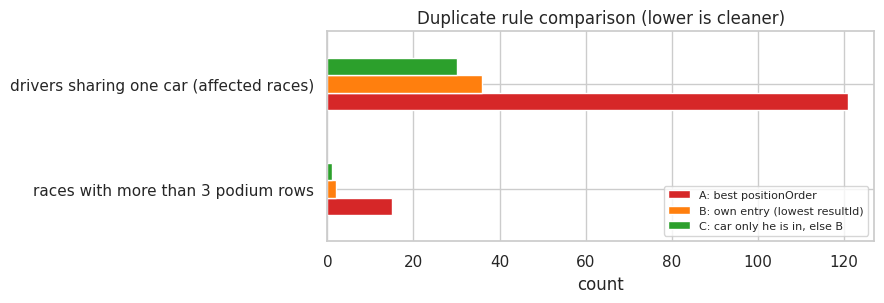

In [13]:
non_indy = res[res["name"] != "Indianapolis 500"]          # Indy is removed anyway (D5), keep the comparison clean
rule_a = non_indy.sort_values(["positionOrder", "resultId"]).drop_duplicates(["raceId", "driverId"])
rule_b = non_indy.sort_values("resultId").drop_duplicates(["raceId", "driverId"])

def own_car_rule(t):
    """Rule C: keep the car only this driver is recorded in (his starting car) if exactly one of his cars is like that;
    otherwise the lowest resultId (rule B). A car = (race, constructor, car number)."""
    number = t["number"].fillna(-t["resultId"])                      # an unknown car number counts as its own car
    solo = t.groupby([t["raceId"], t["constructorId"], number])["driverId"].transform("nunique").eq(1)
    n_solo = solo.groupby([t["raceId"], t["driverId"]]).transform("sum")
    first = (solo & n_solo.eq(1)).map({True: 0, False: 1})
    return t.assign(_first=first).sort_values(["_first", "resultId"]).drop_duplicates(["raceId", "driverId"]).drop(columns="_first")

rule_c = own_car_rule(non_indy)

def integrity(t, name):
    raced = t[~t["category"].isin(["did_not_qualify", "withdrawn"])]   # non-starters share car numbers legitimately
    podiums_per_race = t.groupby("raceId")["positionOrder"].apply(lambda s: (s <= 3).sum())
    return {"rule": name,
            "races with more than 3 podium rows": int((podiums_per_race > 3).sum()),
            "drivers sharing one car (affected races)": int(raced[raced["raceId"].isin(dups["raceId"])]
                                                            .duplicated(["raceId", "number"], keep=False).sum())}

cmp = pd.DataFrame([integrity(rule_a, "A: best positionOrder"), integrity(rule_b, "B: own entry (lowest resultId)"),
                    integrity(rule_c, "C: car only he is in, else B")])
display(cmp)

lab_a = rule_a.set_index(["raceId", "driverId"])["positionOrder"].le(3)
lab_b = rule_b.set_index(["raceId", "driverId"])["positionOrder"].le(3)
lab_c = rule_c.set_index(["raceId", "driverId"])["positionOrder"].le(3)
print(f"Rows removed: {len(non_indy) - len(rule_c)} under every rule | podium labels that differ between A and B: "
      f"{int((lab_a != lab_b.reindex(lab_a.index)).sum())}, between B and C: {int((lab_b != lab_c.reindex(lab_b.index)).sum())}")

# The pairs where C keeps a different car than B: the dropped row is a car the driver took over during the race.
kept_b, kept_c = set(rule_b["resultId"]), set(rule_c["resultId"])
changed = non_indy[non_indy["resultId"].isin(kept_b ^ kept_c)].copy()
changed["kept by"] = np.where(changed["resultId"].isin(kept_c), "rule C", "rule B")
print("Pairs where rule C keeps a different car than rule B:")
display(changed.sort_values(["year", "surname", "kept by"])[["year", "name", "surname", "kept by", "number", "grid", "laps", "positionOrder", "status"]])
ties = non_indy.duplicated(["raceId", "positionOrder"], keep=False)
print("Rows sharing a positionOrder with another row in the same race (shared cars, 1950s–60s):", int(ties.sum()))

fig, ax = plt.subplots(figsize=(9, 3.2))
cmp.set_index("rule").T.plot(kind="barh", ax=ax, color=["tab:red", "tab:orange", "tab:green"])
ax.set_title("Duplicate rule comparison (lower is cleaner)"); ax.set_xlabel("count")
ax.legend(loc="lower right", fontsize=8)
save_fig("05_duplicate_rule")

**What this shows.** All three rules remove the same 67 rows; they differ in *which* row survives. Rule A leaves 15 races with more than three "podium" drivers and lets two drivers keep the same car, because a shared car's result is credited twice. Rule B leaves 2 such races, rule C leaves 1, with the fewest shared cars (30, against 36 for B). C keeps a different car than B in four pairs (last table above):

* **Ascari (1951 French GP), González (1954 Belgian GP) and Moss (1961 British GP)** each took over a team-mate's car after their own car failed. B kept the taken-over car, with the team-mate's grid slot and result (Ascari "started 6th and finished 2nd"); C keeps the car they started in (Ascari started 3rd and retired with a gearbox failure).
* **Greene (1962 British GP)** has grid 0 and 0 laps in both cars: he started in neither, and both rows are removed in 3.6 whichever is kept.

Only one podium label changes between B and C (Ascari's).

🔶 **Decision D4** — we keep the car **only the driver is recorded in** (his starting car) when exactly one of his cars is like that, and otherwise his **own entry (lowest `resultId`)**. Limitations we accept: where the rule falls back to the lowest `resultId` (mostly team-mates who swapped cars, so both cars list two drivers), the data does not say who started which car; one 1950s race (1955 Argentine GP, where Farina and Maglioli are both credited with the 3rd-placed car) still has four podium rows; and official records credit a shared result to both drivers (Ascari's shared 2nd place in 1951), while we count the car the driver started in. All affected rows are from before 1965, inside the training window (D17): rules A and B differ in 15 podium labels, B and C in one (Ascari, 1951), so the rule matters for the model as well as for the data-engineering questions.

In [14]:
# DECISION D4 → see DECISIONS.md  (keep the car only he is recorded in = his starting car; otherwise the lowest resultId)
res_dedup = own_car_rule(res)
assert not res_dedup.duplicated(["raceId", "driverId"]).any()
print(f"results rows: {len(res)} -> {len(res_dedup)}  (removed {len(res) - len(res_dedup)})")

results rows: 26759 -> 26668  (removed 91)


### 3.6 The Indianapolis 500, and who was on the grid at the cutoff

🔶 **Decision D5 — exclude the Indianapolis 500 (1950–1960).** It counted for the championship, but it was an American oval race run to different rules with 33-car grids, and F1 regulars almost never entered it. The cell below measures how separate the two groups of drivers were. We match the exact name "Indianapolis 500"; the unrelated "Indian Grand Prix" (2011–2013) is kept.

In [15]:
indy = res_dedup["name"].eq("Indianapolis 500")
indy_drivers = set(res_dedup.loc[indy, "driverId"])
gp_starters = set(res_dedup.loc[~indy & res_dedup["laps"].gt(0), "driverId"])
indy_pod = set(res_dedup.loc[indy & res_dedup["positionOrder"].le(3), "driverId"])
print(f"Indy 500 rows: {int(indy.sum())} in {res_dedup.loc[indy, 'raceId'].nunique()} races "
      f"(avg {indy.sum() / res_dedup.loc[indy, 'raceId'].nunique():.0f} entries per race)")
print(f"Indy drivers: {len(indy_drivers)}, of whom ever started another championship race: {len(indy_drivers & gp_starters)}")
print(f"Indy podium finishers: {len(indy_pod)}, of whom ever started another championship race: {len(indy_pod & gp_starters)}")

# How it distorts field sizes and the home-race question (Q2)
indy_size = res[res["name"].eq("Indianapolis 500")].groupby("year").size()
gp_size = res[~res["name"].eq("Indianapolis 500") & res["year"].between(1950, 1960)].groupby("raceId").size()
print(f"Largest Indy entry list: {indy_size.max()} rows in {indy_size.idxmax()} | "
      f"other championship races 1950–1960: {gp_size.mean():.0f} entries on average (largest {gp_size.max()})")
nat_of = res_dedup["driverId"].map(df["drivers"].set_index("driverId")["nationality"])
country_of = res_dedup["raceId"].map(df["races"].set_index("raceId")["circuitId"]).map(df["circuits"].set_index("circuitId")["country"])
us_home = nat_of.isin(["American", "American-Italian"]) & country_of.eq("USA")
print(f"Rows of American drivers racing in the USA: {int((us_home & indy).sum())} at the Indy 500 "
      f"vs {int((us_home & ~indy).sum())} at every other race in 75 seasons")

Indy 500 rows: 381 in 11 races (avg 35 entries per race)
Indy drivers: 107, of whom ever started another championship race: 4
Indy podium finishers: 24, of whom ever started another championship race: 2
Largest Indy entry list: 55 rows in 1954 | other championship races 1950–1960: 22 entries on average (largest 36)
Rows of American drivers racing in the USA: 380 at the Indy 500 vs 120 at every other race in 75 seasons


**What this shows.** Of over a hundred Indianapolis 500 drivers only a handful ever started another championship race. It was effectively a separate competition inside the championship table, so its rows say nothing about Grand Prix podiums. It also inflates field sizes (55 entries in 1954, against about 22 at a normal race of that decade), which would lower every 1950s podium rate, and it would distort the home-race question (Q2): almost all of its rows are American drivers racing in the USA, more than all other American home starts in the whole dataset together. Since the model trains from 1950 (D17), the 1950–1960 editions lie inside the training seasons, so the exclusion also keeps 381 oval-race rows out of training.

🔶 **Decision D6 — keep exactly the drivers who were on the starting grid at the prediction cutoff.** The unit of analysis is "one driver entering one race", and our prediction is made **after qualifying**. At that moment two kinds of entries are already out:

* **Failed to qualify** (status *Did not qualify / Did not prequalify / 107% Rule* or `positionText` `F`, with 0 laps): eliminated *by* qualifying, so they are not on the grid at the cutoff.
* **Never on the grid**: no grid slot, no qualifying row and 0 laps (typically withdrawn or excluded before qualifying).

Everyone else is **kept**, including drivers who qualified but then did not start (e.g. Leclerc on pole at Monaco 2021, driveshaft failure on the way to the grid; the 14 cars that withdrew after the formation lap at the 2005 US Grand Prix) and drivers labelled "Withdrew" who actually raced. Those drivers were on the grid when the prediction is made, so dropping them would use information from after the cutoff and would remove exactly the "pole-sitter does not podium" cases that a model must get right. They keep `podium = 0`.

In [16]:
# DECISION D5 → see DECISIONS.md  (drop the Indianapolis 500)
# DECISION D6 → see DECISIONS.md  (keep everyone on the grid at the prediction cutoff)
q_keys_clean = set(zip(df["qualifying"]["raceId"], df["qualifying"]["driverId"]))
res_dedup["has_quali_row"] = [k in q_keys_clean for k in zip(res_dedup["raceId"], res_dedup["driverId"])]

failed_to_qualify = (res_dedup["category"].eq("did_not_qualify") | res_dedup["positionText"].eq("F")) & res_dedup["laps"].eq(0)
never_on_grid = res_dedup["grid"].eq(0) & res_dedup["laps"].eq(0) & ~res_dedup["has_quali_row"]
removed = indy | failed_to_qualify | never_on_grid

on_grid = res_dedup[~removed].copy()
print(f"Indianapolis 500 rows removed:           {int(indy.sum())}")
print(f"Failed-to-qualify rows removed:          {int((failed_to_qualify & ~indy).sum())}")
print(f"Never-on-the-grid rows removed:          {int((never_on_grid & ~indy & ~failed_to_qualify).sum())}")
print(f"Kept: {len(on_grid)} driver-race rows in {on_grid['raceId'].nunique()} races")

# Who is kept although they did not take the start? (they keep podium = 0)
on_grid["started_race"] = on_grid["laps"].gt(0) | ~on_grid["positionText"].isin(["W", "F"])
kept_dns = on_grid[~on_grid["started_race"]]
print(f"Kept drivers who were on the grid but did not take the start: {len(kept_dns)} "
      f"({int((kept_dns['year'] >= 1994).sum())} of them from 1994 on)")
display(kept_dns[kept_dns["year"] >= 2016][["year", "name", "surname", "grid", "laps", "positionText", "status"]])
withdrew_raced = on_grid[on_grid["status"].eq("Withdrew") & on_grid["laps"].gt(0)]
print(f"Rows labelled 'Withdrew' that completed laps (kept, they raced): {len(withdrew_raced)}")

Indianapolis 500 rows removed:           381
Failed-to-qualify rows removed:          1365
Never-on-the-grid rows removed:          207
Kept: 24715 driver-race rows in 1114 races
Kept drivers who were on the grid but did not take the start: 137 (76 of them from 1994 on)


,year,name,surname,grid,laps,positionText,status
22933,2016,Australian Grand Prix,Kvyat,18,0,W,Retired
22954,2016,Bahrain Grand Prix,Vettel,3,0,W,Engine
22955,2016,Bahrain Grand Prix,Palmer,19,0,W,Hydraulics
23241,2016,Singapore Grand Prix,Grosjean,20,0,W,Withdrew
23351,2016,Brazilian Grand Prix,Grosjean,7,0,W,Withdrew
23453,2017,Russian Grand Prix,Alonso,15,0,W,Power Unit
24699,2020,British Grand Prix,Hülkenberg,13,0,W,Power Unit
24759,2020,Belgian Grand Prix,Sainz,7,0,W,Exhaust
25059,2021,Monaco Grand Prix,Leclerc,1,0,W,Driveshaft
25239,2021,Italian Grand Prix,Tsunoda,0,0,W,Brakes


Rows labelled 'Withdrew' that completed laps (kept, they raced): 23


**What this shows.** The removed rows are the ones decided *before* the prediction moment. The kept "did not start" rows (shown from 2016 on) are real pre-race failures of cars that were already on the grid, and the "Withdrew" rows with laps are drivers who retired during the race. Both stay in the table: at the cutoff we would have had to make a prediction for them.

### 3.7 Grid position, field size and the target

🔶 **Decision D7 — starting position.** Two problems with the raw `grid` column:

1. `grid = 0` for a driver who raced means a **pit-lane start**, i.e. *behind* the last grid slot. Left as 0, every model would read it as "better than pole".
2. In old seasons the raw grid numbers have **holes and ties**. At the 1981 German GP, for example, there is no slot 19, 20, 24, 25 or 27, two cars share slot 17, and the last of the 24 starters has grid 28. In a few races the holes are also slots of cars removed in 3.6. Either way, the raw number is not the car's place in the queue.

We therefore **re-rank** the grid among the drivers kept in each race: `grid_clean = 1` for the front, up to the number of cars, and every pit-lane starter is set to the last slot (= the number of cars). A flag `pit_lane_start = 1` keeps the information that it happened. A driver who qualified but has no grid slot because he did not start is placed at his qualifying position. `field_size` = number of cars on the grid, known before the start. One caveat: for the few rows with raw grid 0, telling a pit-lane starter from a car that never left the garage uses the laps column, which is only known after the race; this affects a handful of rows per season at most.

🔶 **Decision D8 — target.** `podium = 1` when `positionOrder ≤ 3`, as the brief specifies. `positionOrder` is filled for every row (unlike `position`, which is empty for unclassified drivers). It is used **only** to build the target and is then removed from the feature side. Known limitation: in a few old races a disqualified driver's position was left vacant (e.g. 1983 Brazil, 2nd place), so the 4th-placed finisher has `positionOrder = 3`. We follow the brief's definition.

In [17]:
qpos = df["qualifying"].set_index(["raceId", "driverId"])["position"]
on_grid["quali_pos_tmp"] = [qpos.get(k, np.nan) for k in zip(on_grid["raceId"], on_grid["driverId"])]

# DECISION D7 → see DECISIONS.md  (re-rank the grid among cars on the grid; pit lane = behind the last slot)
on_grid["pit_lane_start"] = (on_grid["grid"].eq(0) & on_grid["started_race"]).astype(int)
slot = on_grid["grid"].where(on_grid["grid"] > 0)                                # real grid slots
slot = slot.fillna(on_grid["quali_pos_tmp"].where(~on_grid["started_race"]))      # did not start: his qualifying slot
slot = slot.fillna(1000)                                                          # pit lane: behind everyone
on_grid["grid_clean"] = slot.groupby(on_grid["raceId"]).rank(method="min").astype(int)
on_grid["field_size"] = on_grid.groupby("raceId")["driverId"].transform("size")
# Every pit-lane starter goes to the very last slot (= field_size), the same encoding the inference function uses.
on_grid.loc[on_grid["pit_lane_start"] == 1, "grid_clean"] = on_grid.loc[on_grid["pit_lane_start"] == 1, "field_size"]

# Finishing position re-ranked the same way (only used later, shifted, for past-form features)
on_grid["finish_rank"] = on_grid.groupby("raceId")["positionOrder"].rank(method="min").astype(int)

# Row-level outcome category: a "Withdrew" row that took the start is an unknown in-race retirement.
on_grid["category"] = np.where(on_grid["category"].eq("withdrawn") & on_grid["started_race"], "ambiguous",
                               np.where(~on_grid["started_race"], "did_not_start", on_grid["category"]))

# DECISION D8 → see DECISIONS.md  (target)
on_grid["podium"] = (on_grid["positionOrder"] <= 3).astype(int)

results_clean = on_grid.drop(columns=["quali_pos_tmp"]).sort_values(["year", "round", "grid_clean"]).reset_index(drop=True)

# Final integrity checks on the cleaned driver-race table
assert not results_clean.duplicated(["raceId", "driverId"]).any(), "grain broken: duplicate (raceId, driverId)"
assert results_clean["podium"].isin([0, 1]).all()
assert results_clean["grid_clean"].between(1, results_clean["field_size"]).all(), "grid slot outside the field"
pods = results_clean.groupby("raceId")["podium"].sum()
print(results_clean.shape, "| podium rate:", round(results_clean["podium"].mean(), 4))
print("Races by number of podium rows:", pods.value_counts().sort_index().to_dict())
print("Pit-lane starters:", int(results_clean["pit_lane_start"].sum()))

(24715, 33) | podium rate: 0.1353
Races by number of podium rows: {3: 1113, 4: 1}
Pit-lane starters: 73


### 3.8 Raw files unchanged

In [18]:
# DECISION D1 → see DECISIONS.md  (prove the raw CSVs were not modified by any cleaning step)
assert all(md5(f"{DATA_DIR}/{t}.csv") == RAW_HASHES[t] for t in TABLES), "a raw file was modified"
print("✔ all 14 raw CSV files are byte-for-byte unchanged")

✔ all 14 raw CSV files are byte-for-byte unchanged


## 4. EDA after cleaning (before vs after)

The brief asks for EDA both before and after cleaning, so we can see what the cleaning changed. We compare the raw `results` rows with the cleaned driver-race table.

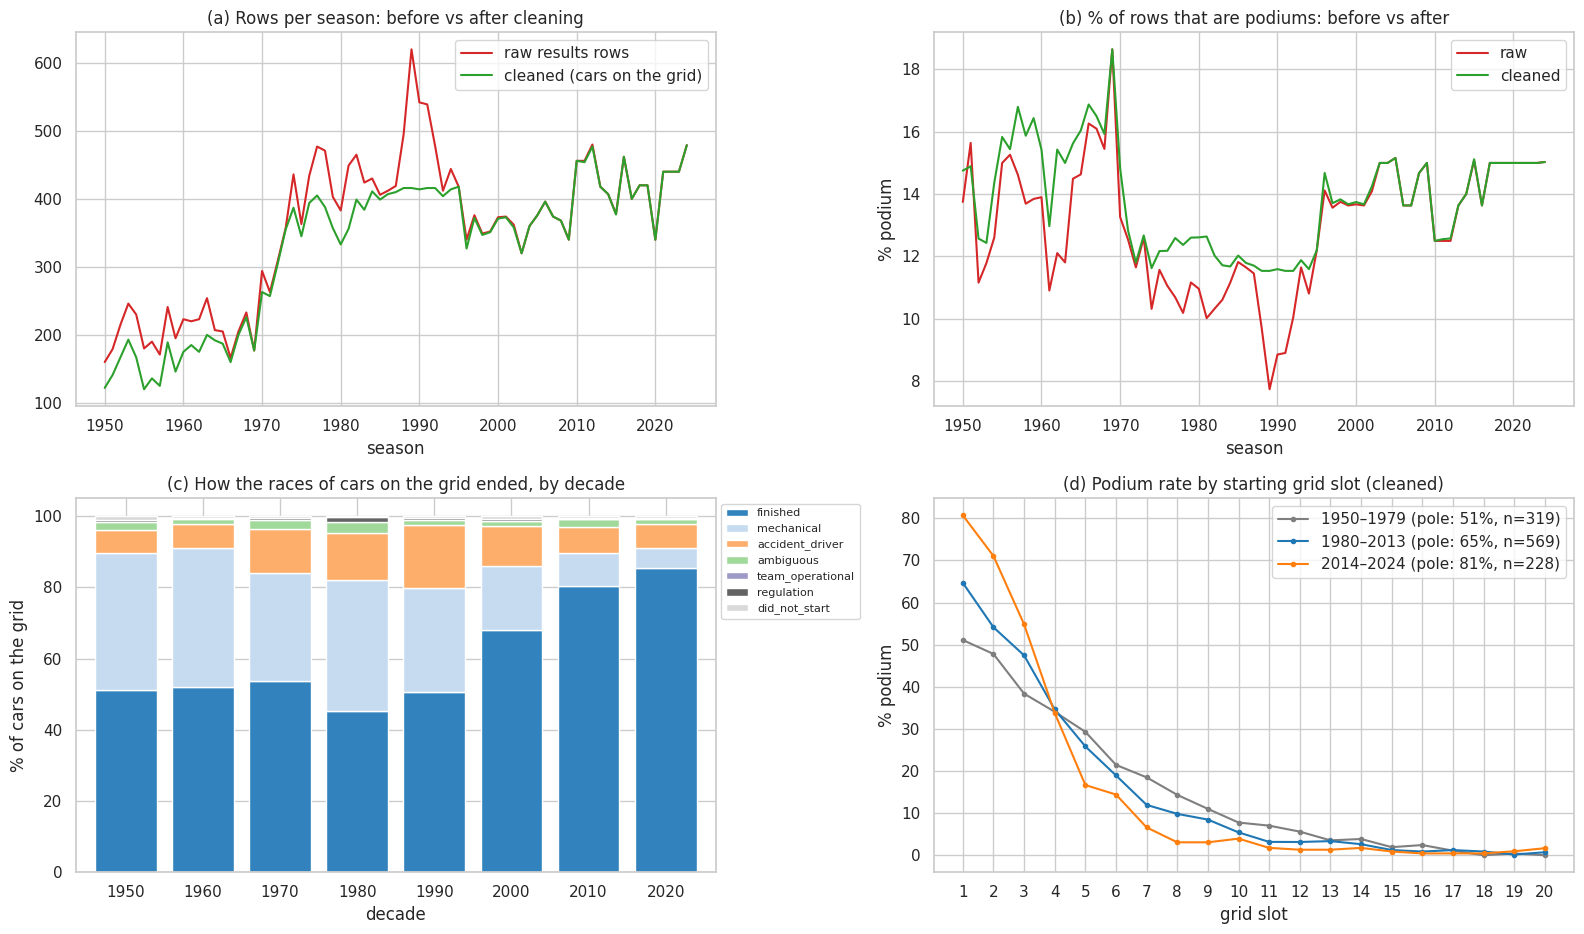

,rows,"duplicate (raceId, driverId) rows",rows with grid = 0,grid slot > number of cars,podium rate,races
raw,26759,91,1638,13,0.1269,1125
cleaned,24715,0,0,0,0.1353,1114


In [19]:
raw_rows = res_raw.assign(podium=res_raw["positionOrder"].astype(int) <= 3)

fig, axes = plt.subplots(2, 2, figsize=(16, 9.5))

# (a) rows per season
raw_rows.groupby("year").size().plot(ax=axes[0, 0], label="raw results rows", color="tab:red")
results_clean.groupby("year").size().plot(ax=axes[0, 0], label="cleaned (cars on the grid)", color="tab:green")
axes[0, 0].set_title("(a) Rows per season: before vs after cleaning"); axes[0, 0].legend(); axes[0, 0].set_xlabel("season")

# (b) target base rate per season
(raw_rows.groupby("year")["podium"].mean() * 100).plot(ax=axes[0, 1], label="raw", color="tab:red")
(results_clean.groupby("year")["podium"].mean() * 100).plot(ax=axes[0, 1], label="cleaned", color="tab:green")
axes[0, 1].set_title("(b) % of rows that are podiums: before vs after"); axes[0, 1].set_ylabel("% podium")
axes[0, 1].legend(); axes[0, 1].set_xlabel("season")

# (c) how a race ends, by decade (cleaned table): reliability changed enormously
cat_order = ["finished", "mechanical", "accident_driver", "ambiguous", "team_operational", "regulation", "did_not_start"]
cat_dec = (results_clean.assign(decade=results_clean["year"] // 10 * 10)
           .groupby("decade")["category"].value_counts(normalize=True).unstack().reindex(columns=cat_order).fillna(0) * 100)
cat_dec.plot(kind="bar", stacked=True, ax=axes[1, 0], colormap="tab20c", width=0.8)
axes[1, 0].set_title("(c) How the races of cars on the grid ended, by decade"); axes[1, 0].set_ylabel("% of cars on the grid")
axes[1, 0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0)); axes[1, 0].tick_params(axis="x", rotation=0)

# (d) podium rate by starting slot (cleaned), split into eras, with sample sizes
for (lo, hi), col in zip([(1950, 1979), (1980, 2013), (2014, 2024)], ["tab:gray", "tab:blue", "tab:orange"]):
    sub = results_clean[results_clean["year"].between(lo, hi) & (results_clean["grid_clean"] <= 20)]
    rate = sub.groupby("grid_clean")["podium"].mean() * 100
    n_pole = int((sub["grid_clean"] == 1).sum())
    axes[1, 1].plot(rate.index, rate.values, marker="o", ms=3, color=col, label=f"{lo}–{hi} (pole: {rate.loc[1]:.0f}%, n={n_pole})")
axes[1, 1].set_xticks(range(1, 21)); axes[1, 1].set_title("(d) Podium rate by starting grid slot (cleaned)")
axes[1, 1].set_xlabel("grid slot"); axes[1, 1].set_ylabel("% podium"); axes[1, 1].legend()
save_fig("06_eda_before_after")

summary = pd.DataFrame({
    "rows": [len(raw["results"]), len(results_clean)],
    "duplicate (raceId, driverId) rows": [int(raw["results"].duplicated(["raceId", "driverId"]).sum()),
                                          int(results_clean.duplicated(["raceId", "driverId"]).sum())],
    "rows with grid = 0": [int((raw["results"]["grid"] == "0").sum()), int((results_clean["grid_clean"] == 0).sum())],
    "grid slot > number of cars": [int((res_raw["grid"].astype(int) > res_raw.groupby("raceId")["grid"].transform("size")).sum()),
                                   int((results_clean["grid_clean"] > results_clean["field_size"]).sum())],
    "podium rate": [round(raw_rows["podium"].mean(), 4), round(results_clean["podium"].mean(), 4)],
    "races": [raw["results"]["raceId"].nunique(), results_clean["raceId"].nunique()],
}, index=["raw", "cleaned"])
summary

**What this shows.**

* (a) Cleaning mostly removes rows from the 1950s and the busy late 1970s–1990s, the eras with the Indianapolis 500 and with entry lists far larger than the grid. Modern seasons are almost untouched.
* (b) Because drivers who failed to qualify can never podium, removing them raises the podium base rate in the busy eras (late 1980s: from ~8–10% to ~12%). Modern seasons stay at ~15%. The target is now about drivers who were on the grid.
* (c) Reliability changed enormously: in the 1950s–1980s around a third of the cars on the grid retired with a mechanical failure; in the 2020s most cars finish. A good grid slot therefore converted to a podium much less reliably in early decades.
* (d) Grid position is strongly predictive in every era, and its effect is **much stronger in the modern era** (pole rates and sample sizes in the legend). This motivates both the grid features and the choice of training window (D17).

**Effect of the grid recoding (D7).** The next plot shows the starting-position column before and after cleaning.

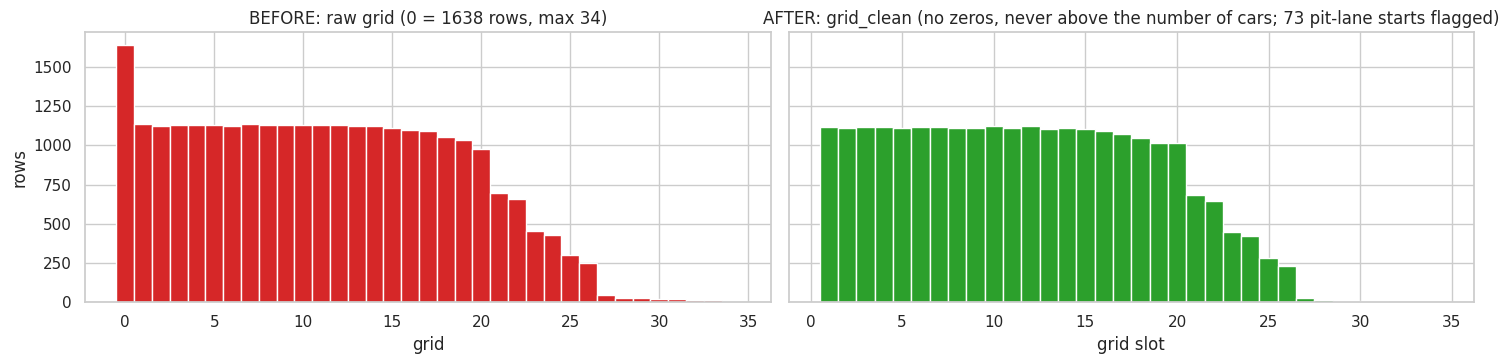

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
g_raw = res_raw["grid"].astype(int)
axes[0].hist(g_raw, bins=np.arange(-0.5, g_raw.max() + 1.5), color="tab:red")
axes[0].set_title(f"BEFORE: raw grid (0 = {int((g_raw == 0).sum())} rows, max {g_raw.max()})"); axes[0].set_xlabel("grid")
axes[1].hist(results_clean["grid_clean"], bins=np.arange(0.5, results_clean["grid_clean"].max() + 1.5), color="tab:green")
axes[1].set_title(f"AFTER: grid_clean (no zeros, never above the number of cars; {int(results_clean['pit_lane_start'].sum())} pit-lane starts flagged)")
axes[1].set_xlabel("grid slot"); axes[0].set_ylabel("rows")
save_fig("06b_grid_before_after")

**What this shows.** The spike at 0 (mostly drivers who never got onto the grid) is gone, and no car has a slot behind the last car anymore. The few real pit-lane starts are now at the back of the field, with their own flag.

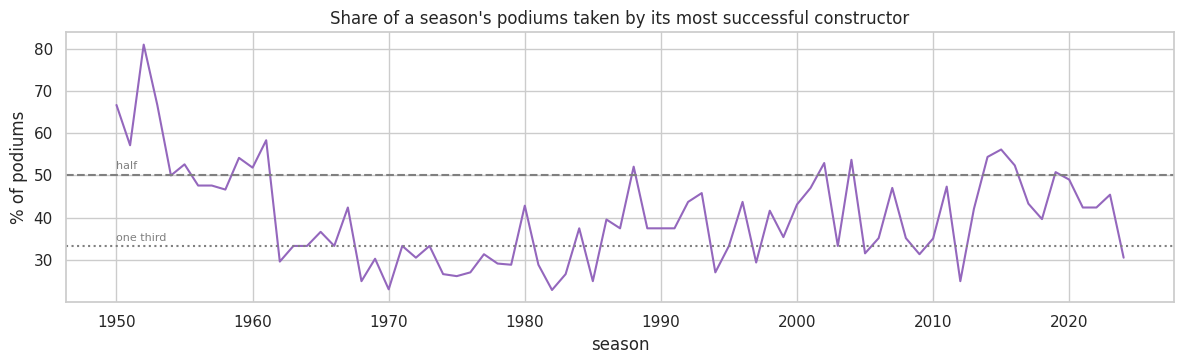

Seasons where one team took over half of all podiums: [1950, 1951, 1952, 1953, 1955, 1959, 1960, 1961, 1988, 2002, 2004, 2014, 2015, 2016, 2019]
Median share of the top team: 37.5 %


In [21]:
# Constructor dominance: in each season, what share of all podiums did the single best team take?
by_team = results_clean[results_clean["podium"] == 1].groupby(["year", "constructorId"]).size()
top_share = (by_team.groupby("year").max() / by_team.groupby("year").sum() * 100)

fig, ax = plt.subplots(figsize=(12, 3.8))
top_share.plot(ax=ax, color="tab:purple")
ax.axhline(100 / 3, ls=":", color="gray"); ax.text(1950, 34.5, "one third", color="gray", fontsize=8)
ax.axhline(50, ls="--", color="gray"); ax.text(1950, 51.5, "half", color="gray", fontsize=8)
ax.set_title("Share of a season's podiums taken by its most successful constructor")
ax.set_ylabel("% of podiums"); ax.set_xlabel("season")
save_fig("07_constructor_dominance")
print("Seasons where one team took over half of all podiums:", list(top_share[top_share > 50].index))
print("Median share of the top team:", round(top_share.median(), 1), "%")

**What this shows.** In most seasons a single constructor takes a third or more of all podiums, and in several seasons more than half. The car (built by the constructor) dominates who podiums, which is why our features include **constructor** form and standings, not only driver form.

**Grid vs qualifying per season (penalties over time).** A driver's grid slot is his qualifying position unless something moved him: a grid penalty (gearbox or engine changes, impeding, a crash in the previous race), a start from the pit lane, or, on the 2021–2022 sprint weekends, the sprint result. We count, for every season with complete qualifying data (2003–2024), how many cars that took the start had a grid slot different from their qualifying position, and why. "Moved forward" is mostly a knock-on effect: when one car is sent back, the cars behind it move up.

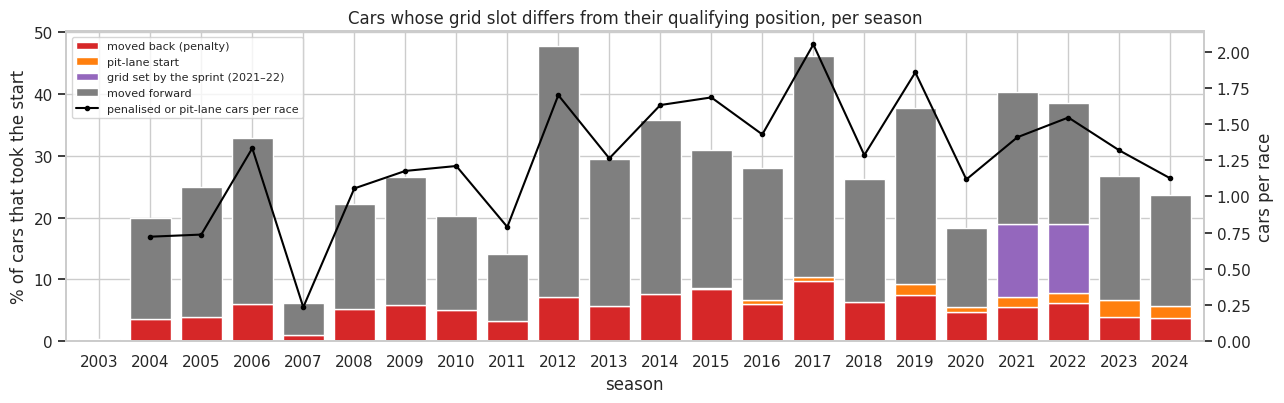

Penalised or pit-lane cars per race: {'2003–2013': 1.02, '2014–2024': 1.5}
Share of starters moved back (penalty or pit lane): {'2003–2013': 4.3, '2014–2024': 7.4} %
Seasons with the most moved-back cars per race: {2017: 2.05, 2019: 1.86, 2012: 1.7}


In [22]:
gq = results_clean[results_clean["year"].between(2003, 2024) & results_clean["started_race"]].merge(
    df["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"}),
    on=["raceId", "driverId"], how="inner", validate="one_to_one")
sprint_weekend = gq["raceId"].isin(set(df["sprint_results"]["raceId"])) & gq["year"].between(2021, 2022)
gq["change"] = np.select(
    [gq["grid_clean"].eq(gq["quali_position"]),
     sprint_weekend,
     gq["pit_lane_start"].eq(1),
     gq["grid_clean"] > gq["quali_position"]],
    ["grid = qualifying", "grid set by the sprint (2021–22)", "pit-lane start", "moved back (penalty)"], default="moved forward")
order = ["moved back (penalty)", "pit-lane start", "grid set by the sprint (2021–22)", "moved forward"]
share = (pd.crosstab(gq["year"], gq["change"], normalize="index") * 100).reindex(columns=order, fill_value=0)
moved_back = gq[gq["change"].isin(["moved back (penalty)", "pit-lane start"])]
per_race = (moved_back.groupby("year").size() / gq.groupby("year")["raceId"].nunique()).reindex(share.index, fill_value=0)

fig, ax = plt.subplots(figsize=(13, 4.2))
share.plot(kind="bar", stacked=True, ax=ax, width=0.8, color=["tab:red", "tab:orange", "tab:purple", "tab:gray"])
ax.set_ylabel("% of cars that took the start"); ax.set_xlabel("season"); ax.tick_params(axis="x", rotation=0)
ax.set_title("Cars whose grid slot differs from their qualifying position, per season")
ax2 = ax.twinx()
ax2.plot(range(len(per_race)), per_race.values, color="black", marker="o", ms=3, label="penalised or pit-lane cars per race")
ax2.set_ylabel("cars per race"); ax2.set_ylim(0, None); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
save_fig("07b_grid_vs_qualifying")

periods = pd.cut(per_race.index, [2002, 2013, 2024], labels=["2003–2013", "2014–2024"])
print("Penalised or pit-lane cars per race:", per_race.groupby(periods, observed=True).mean().round(2).to_dict())
print("Share of starters moved back (penalty or pit lane):",
      (share[["moved back (penalty)", "pit-lane start"]].sum(axis=1).groupby(periods, observed=True).mean().round(1)).to_dict(), "%")
print("Seasons with the most moved-back cars per race:", per_race.sort_values(ascending=False).head(3).round(2).to_dict())

**What this shows.** Grid penalties became more common in the hybrid era (from 2014). On average 1.0 car per race started behind its qualifying position (a penalty or a pit-lane start) in 2003–2013, against 1.5 in 2014–2024 (4.3% vs 7.4% of starters). The peaks are 2017 (2.05 per race) and 2019 (1.86), seasons with strict limits on how many engine parts a team may use. Each penalty pushes the cars behind forward, which is why the grey bars are large. On the 2021–2022 sprint weekends the sprint result, not qualifying, set the grid (purple, about 11–12% of starters in those seasons). The 2003 season shows no difference at all, probably because the data stores that season's grid order as its qualifying order (inferred, not checked against another source). Because grid and qualifying differ for several cars in most races, both `grid_pos` and `quali_position` are kept as features, with the difference as `grid_penalty` measured against the sprint result on sprint weekends (D15).

Save the cleaned table for later sections and for the GitHub repo.

In [23]:
results_clean.to_csv(os.path.join(OUT_DIR, "results_clean.csv"), index=False)
print("Saved", os.path.join(OUT_DIR, "results_clean.csv"))

Saved /kaggle/working/results_clean.csv


## 5. Data-engineering questions

Each answer uses joins across several tables, shows a plot, and states its **grain** (what one row means), how **missing values** were handled, and whether the **pre-race cutoff** matters.

All three questions use the cleaned driver-race table from Section 3 (`results_clean`: starters only, no Indianapolis 500, one row per driver per race). That table was itself built by joining `results` ⨝ `races` ⨝ `status` ⨝ `drivers`.

---
### 5.1 Q1. Which circuits convert a front-row start into a podium most often, and does that ranking change after 2014?

**Tables joined:** `results` ⨝ `races` ⨝ `circuits` ⨝ `qualifying` ⨝ `sprint_results`.
**Grain:** one row per driver per race; we then aggregate to one row per circuit per period.

🔶 **Decision D9 — how Q1 is measured.**
* *Front row by grid* = car in grid slot 1 or 2 (after penalties). *Front row by qualifying* = qualified 1st or 2nd. A car that was on the front row but did not take the start counts as a failed conversion.
* The two definitions differ for two reasons: **penalties**, and in **2021–2022 sprint weekends** the grid was set by the sprint, not by qualifying. We label both.
* "After the 2014 hybrid era" is read as **2014–2024 vs before 2014**. For "before" we use **2003–2013**: 2003 is the first season with complete qualifying data (Section 2.3), so both definitions use exactly the same rows and both periods span 11 seasons.
* Only circuits with **at least 8 front-row starts (4 races) in both periods** are ranked. Every race has 2 front-row cars, so 8 starts means the circuit hosted at least 4 races in that period. A rate from very few starts is mostly luck: with 2 starts it can only be 0%, 50% or 100%. The threshold is a judgement call between keeping more circuits and having steadier rates (8 keeps 17 circuits, 10 keeps 14).
* Because samples per circuit are small, every rate gets a **95% Wilson interval**, we test whether circuits differ at all and whether the overall rate changed (chi-square), and we measure whether the circuit order carries over between periods (Spearman rank correlation).

Rows 2003–2024 without a qualifying position: 22 of 8964 (best grid slot among them: 19, so none is a front-row case)
Front-row cars 2003–2024, split by how their grid slot relates to their qualifying position:


,rows,podiums,podium rate,95% CI
fr_case,,,,
qualified AND started front row,819,594,0.725,0.69–0.75
promoted to front row by others' penalties,32,20,0.625,0.45–0.77
sprint set the grid (2021–22),10,6,0.600,0.31–0.83
"qualified front row, moved back by a penalty",32,9,0.281,0.16–0.45


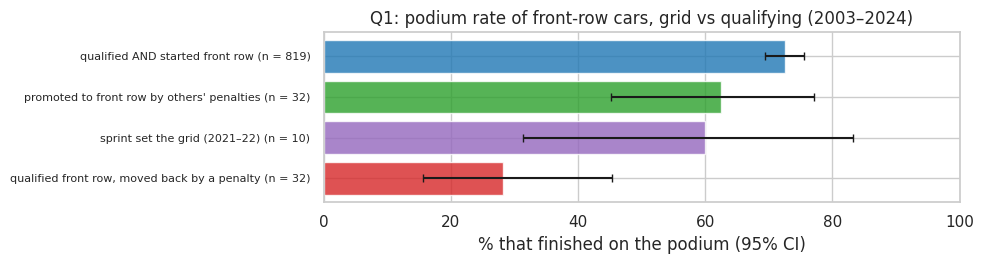


Ranking by GRID (front row = started 1st/2nd), 17 circuits:


,rate 2003–2013,CI 2003–2013,rank 2003–2013,n 2003–2013,rate 2014–2024,CI 2014–2024,rank 2014–2024,n 2014–2024
circuit,,,,,,,,
Suzuka Circuit,0.722,0.49–0.88,4,18,0.889,0.67–0.97,1,18
Sepang International Circuit,0.636,0.43–0.80,10,22,0.875,0.53–0.98,2,8
Yas Marina Circuit,0.600,0.31–0.83,13,10,0.864,0.67–0.95,3,22
Circuit de Monaco,0.773,0.57–0.90,1,22,0.850,0.64–0.95,4,20
Circuit de Spa-Francorchamps,0.722,0.49–0.88,4,18,0.818,0.61–0.93,5,22
Circuit de Barcelona-Catalunya,0.682,0.47–0.84,7,22,0.818,0.61–0.93,5,22
Shanghai International Circuit,0.650,0.43–0.82,9,20,0.786,0.52–0.92,7,14
Circuit Gilles Villeneuve,0.600,0.39–0.78,13,20,0.778,0.55–0.91,8,18
Silverstone Circuit,0.727,0.52–0.87,3,22,0.750,0.55–0.88,9,24


Circuits differ in 2003–2013?  chi-square p = 0.991
Circuits differ in 2014–2024?  chi-square p = 0.796
Pooled front-row conversion: {'2003–2013': '0.680 (n=400)', '2014–2024': '0.759 (n=456)'} | chi-square p = 0.013
Spearman ρ between periods (grid): 0.21 (p = 0.42), 17 circuits
Spearman ρ between periods (qualifying): 0.45 (p = 0.07), 17 circuits
Autodromo Nazionale di Monza: 2003–2013: 17 of 22 (77%, rank 1 of 17) | 2014–2024: 16 of 22 (73%, rank 12 of 17)
Yas Marina Circuit: 2003–2013: 6 of 10 (60%, rank 13 of 17) | 2014–2024: 19 of 22 (86%, rank 3 of 17)
Range of circuit rates: 58% to 89%

Ranking by QUALIFYING (front row = qualified 1st/2nd), 17 circuits:


,rate 2003–2013,CI 2003–2013,rank 2003–2013,n 2003–2013,rate 2014–2024,CI 2014–2024,rank 2014–2024,n 2014–2024
circuit,,,,,,,,
Suzuka Circuit,0.722,0.49–0.88,3,18,0.889,0.67–0.97,1,18
Circuit de Monaco,0.682,0.47–0.84,7,22,0.850,0.64–0.95,2,20
Yas Marina Circuit,0.600,0.31–0.83,12,10,0.818,0.61–0.93,3,22
Circuit de Spa-Francorchamps,0.722,0.49–0.88,3,18,0.818,0.61–0.93,3,22
Circuit de Barcelona-Catalunya,0.636,0.43–0.80,9,22,0.818,0.61–0.93,3,22
Shanghai International Circuit,0.700,0.48–0.85,6,20,0.786,0.52–0.92,6,14
Sepang International Circuit,0.636,0.43–0.80,9,22,0.750,0.41–0.93,7,8
Silverstone Circuit,0.773,0.57–0.90,1,22,0.750,0.55–0.88,7,24
Autodromo Nazionale di Monza,0.727,0.52–0.87,2,22,0.727,0.52–0.87,9,22


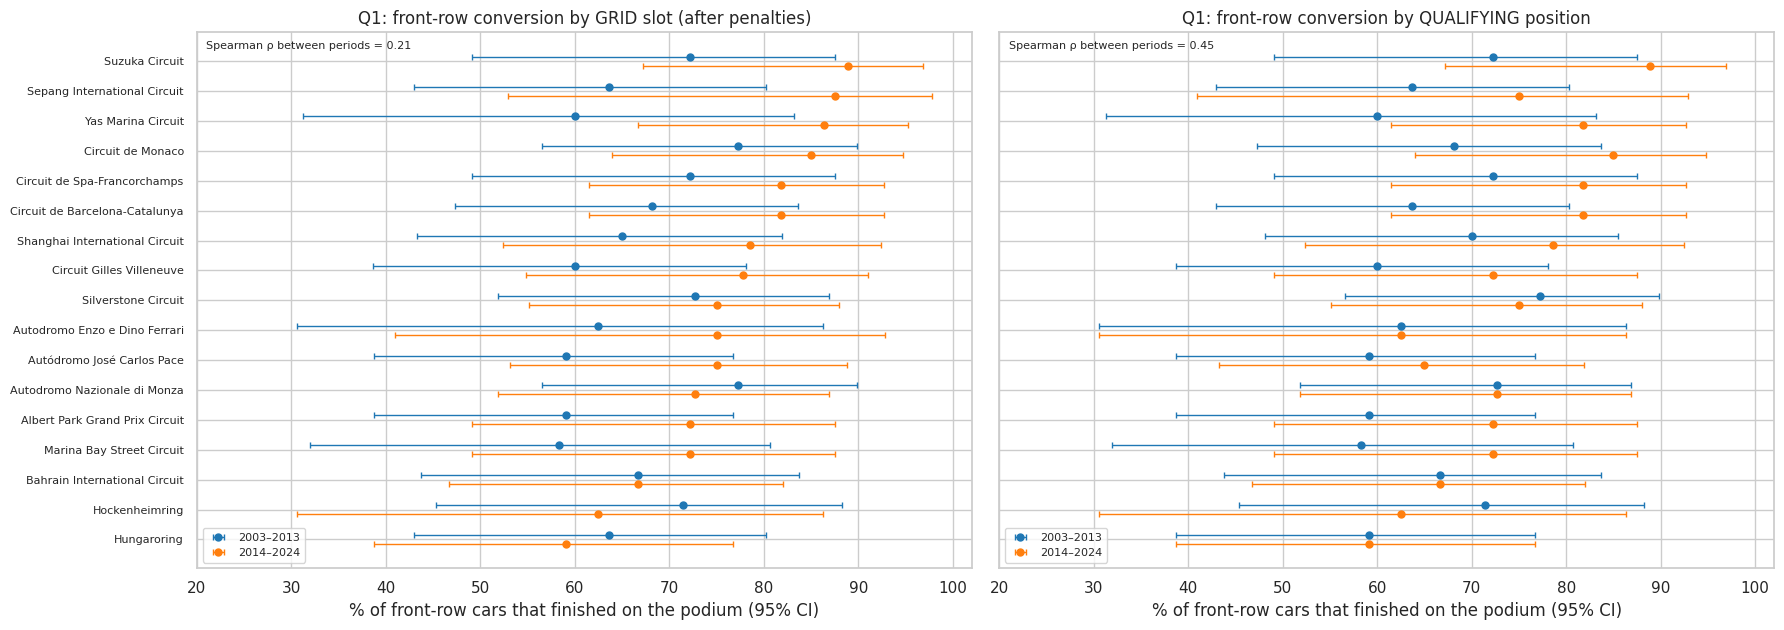

In [24]:
from scipy.stats import chi2_contingency, spearmanr

def wilson(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion k/n (works well for small n and rates near 0 or 1)."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n; den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

# Join chain: cleaned results -> races (circuit) -> circuits (name) -> qualifying (position) -> sprint_results (sprint weekends).
quali_pos = df["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"})
sprint_races = set(df["sprint_results"]["raceId"])
q1_all = (results_clean
          .merge(df["races"][["raceId", "circuitId"]], on="raceId", how="left")
          .merge(df["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit", "circuitId": "cid"}), left_on="circuitId", right_on="cid", how="left")
          .merge(quali_pos, on=["raceId", "driverId"], how="left"))      # left join: rows without qualifying keep NaN
# Grid set by the sprint (2021–2022 sprint weekends) rather than by qualifying:
q1_all["sprint_grid"] = q1_all["raceId"].isin(sprint_races) & q1_all["year"].between(2021, 2022)
q1_all["front_row_grid"] = (q1_all["grid_clean"] <= 2) & (q1_all["pit_lane_start"] == 0)
q1_all["front_row_quali"] = q1_all["quali_position"] <= 2

# DECISION D9 → see DECISIONS.md  (definitions, periods, minimum sample, uncertainty)
q1 = q1_all[q1_all["year"].between(2003, 2024)].copy()
q1["period"] = np.where(q1["year"] <= 2013, "2003–2013", "2014–2024")
miss = q1[q1["quali_position"].isna()]
print(f"Rows 2003–2024 without a qualifying position: {len(miss)} of {len(q1)} "
      f"(best grid slot among them: {int(miss['grid_clean'].min())}, so none is a front-row case)")

# How often do the two definitions disagree, and what does it do to podium conversion?
q1["fr_case"] = np.select(
    [q1["front_row_grid"] & q1["front_row_quali"],
     q1["front_row_quali"] & ~q1["front_row_grid"] & ~q1["sprint_grid"],
     q1["front_row_grid"] & ~q1["front_row_quali"] & ~q1["sprint_grid"],
     (q1["front_row_grid"] ^ q1["front_row_quali"]) & q1["sprint_grid"]],
    ["qualified AND started front row", "qualified front row, moved back by a penalty",
     "promoted to front row by others' penalties", "sprint set the grid (2021–22)"],
    default="neither")
cases = q1[q1["fr_case"] != "neither"].groupby("fr_case")["podium"].agg(rows="size", podiums="sum")
cases["podium rate"] = cases["podiums"] / cases["rows"]
cases["95% CI"] = [f"{lo:.2f}–{hi:.2f}" for lo, hi in zip(*wilson(cases["podiums"], cases["rows"]))]
order_cases = ["qualified AND started front row", "promoted to front row by others' penalties",
               "sprint set the grid (2021–22)", "qualified front row, moved back by a penalty"]
cases = cases.reindex(order_cases)
print("Front-row cars 2003–2024, split by how their grid slot relates to their qualifying position:")
display(cases.round(3))
lo, hi = wilson(cases["podiums"], cases["rows"])
fig, ax = plt.subplots(figsize=(10, 2.8))
yy = np.arange(len(cases))[::-1]
ax.barh(yy, cases["podium rate"] * 100, color=["tab:blue", "tab:green", "tab:purple", "tab:red"], alpha=0.8,
        xerr=[(cases["podium rate"] - lo) * 100, (hi - cases["podium rate"]) * 100], capsize=3)
ax.set_yticks(yy); ax.set_yticklabels([f"{c} (n = {n})" for c, n in zip(cases.index, cases["rows"])], fontsize=8)
ax.set_xlabel("% that finished on the podium (95% CI)"); ax.set_xlim(0, 100)
ax.set_title("Q1: podium rate of front-row cars, grid vs qualifying (2003–2024)")
save_fig("08a_q1_grid_vs_quali_cases")

def conversion(data, flag):
    """Front-row starts, podiums and podium rate per circuit and period."""
    t = data[data[flag]].groupby(["circuit", "period"])["podium"].agg(starts="size", podiums="sum").unstack("period")
    return t

MIN_STARTS = 8                                    # D9: at least 4 races (2 front-row cars each) per period
PERIODS = ["2003–2013", "2014–2024"]

def ranking(flag):
    t = conversion(q1, flag)
    t = t[(t["starts"] >= MIN_STARTS).all(axis=1)]
    out = pd.DataFrame(index=t.index)
    for p in PERIODS:
        out[f"rate {p}"] = t[("podiums", p)] / t[("starts", p)]
        lo, hi = wilson(t[("podiums", p)], t[("starts", p)])
        out[f"CI {p}"] = [f"{a:.2f}–{b:.2f}" for a, b in zip(lo, hi)]
        out[f"rank {p}"] = out[f"rate {p}"].rank(ascending=False, method="min").astype(int)
        out[f"n {p}"] = t[("starts", p)].astype(int)
    return out.sort_values("rate 2014–2024", ascending=False), t

rank_grid, counts_grid = ranking("front_row_grid")
rank_quali, counts_quali = ranking("front_row_quali")
print(f"\nRanking by GRID (front row = started 1st/2nd), {len(rank_grid)} circuits:")
display(rank_grid.round(3))

# 1) Do circuits differ at all? Chi-square test of circuit × podium within each period.
for p in PERIODS:
    tab = np.c_[counts_grid[("podiums", p)], counts_grid[("starts", p)] - counts_grid[("podiums", p)]]
    print(f"Circuits differ in {p}?  chi-square p = {chi2_contingency(tab)[1]:.3f}")
# 2) Did conversion rise overall after 2014? (all front-row starts, all circuits)
pooled = q1[q1["front_row_grid"]].groupby("period")["podium"].agg(["sum", "size"])
print("Pooled front-row conversion:", {p: f"{r['sum'] / r['size']:.3f} (n={int(r['size'])})" for p, r in pooled.iterrows()},
      f"| chi-square p = {chi2_contingency(np.c_[pooled['sum'], pooled['size'] - pooled['sum']])[1]:.3f}")
# 3) Does the order carry over? Spearman rank correlation between the two periods.
def rho_of(rank_df):
    return spearmanr(rank_df["rate 2003–2013"], rank_df["rate 2014–2024"])
rho, rho_p = rho_of(rank_grid)
rho_q, rho_q_p = rho_of(rank_quali)
print(f"Spearman ρ between periods (grid): {rho:.2f} (p = {rho_p:.2f}), {len(rank_grid)} circuits")
print(f"Spearman ρ between periods (qualifying): {rho_q:.2f} (p = {rho_q_p:.2f}), {len(rank_quali)} circuits")

# 4) Reading a rank change: two examples in podiums out of front-row starts.
for c in ["Autodromo Nazionale di Monza", "Yas Marina Circuit"]:
    print(f"{c}: " + " | ".join(
        f"{p}: {int(counts_grid.loc[c, ('podiums', p)])} of {int(counts_grid.loc[c, ('starts', p)])} "
        f"({rank_grid.loc[c, f'rate {p}']:.0%}, rank {rank_grid.loc[c, f'rank {p}']} of {len(rank_grid)})" for p in PERIODS))
print(f"Range of circuit rates: {rank_grid[[f'rate {p}' for p in PERIODS]].min().min():.0%} to {rank_grid[[f'rate {p}' for p in PERIODS]].max().max():.0%}")

print(f"\nRanking by QUALIFYING (front row = qualified 1st/2nd), {len(rank_quali)} circuits:")
display(rank_quali.round(3))

# Figure: left = grid definition with 95% intervals; right = qualifying definition, same circuit order.
order = rank_grid.index
fig, axes = plt.subplots(1, 2, figsize=(18, max(5.5, 0.38 * len(order))), sharey=True)
for ax, (rk, cnt, title) in zip(axes, [(rank_grid, counts_grid, "by GRID slot (after penalties)"),
                                         (rank_quali.reindex(order), counts_quali.reindex(order), "by QUALIFYING position")]):
    y = np.arange(len(order))[::-1]
    for p, col, off in [("2003–2013", "tab:blue", 0.15), ("2014–2024", "tab:orange", -0.15)]:
        k, n = cnt[("podiums", p)].reindex(order), cnt[("starts", p)].reindex(order)
        rate = k / n; lo, hi = wilson(k, n)
        ax.errorbar(rate * 100, y + off, xerr=[(rate - lo) * 100, (hi - rate) * 100], fmt="o", color=col, ms=5,
                    capsize=2, lw=1, label=p)
    ax.set_yticks(np.arange(len(order))[::-1]); ax.set_yticklabels(order, fontsize=8)
    ax.set_xlabel("% of front-row cars that finished on the podium (95% CI)"); ax.set_title(f"Q1: front-row conversion {title}")
    ax.set_xlim(20, 102); ax.legend(loc="lower left", fontsize=8)
axes[0].text(21, len(order) - 0.6, f"Spearman ρ between periods = {rho:.2f}", fontsize=8)
axes[1].text(21, len(order) - 0.6, f"Spearman ρ between periods = {rho_q:.2f}", fontsize=8)
save_fig("08_q1_front_row")

**How to read the numbers in this section**

* **rate**: podiums ÷ front-row starts at that circuit in that period (0.72 = 72% of the front-row cars finished on the podium).
* **n**: how many front-row starts the rate is based on. The smaller n, the less reliable the rate.
* **95% CI** (confidence interval, Wilson method): the range the true rate probably lies in. It is wide when n is small. When two circuits' intervals overlap a lot, we cannot say that one really converts better than the other.
* **rank**: the circuit's place when all circuits are sorted by rate (1 = best; equal rates share a rank).
* **Chi-square test and its p-value**: asks "do all circuits have the same conversion rate, and are the differences between them just luck?" The p-value is the chance of seeing differences at least this large by luck alone. Below 0.05 we call a difference real; above it, luck explains it. The same test on the two periods' overall rates checks whether the rise after 2014 is real.
* **Spearman ρ** (rank correlation): do the circuits keep the same order in both periods? +1 = same order, 0 = the two orders are unrelated, −1 = reversed order. Its p-value asks whether a correlation this large could appear by luck if the two orders were unrelated; above 0.05 we cannot claim the order carries over.

**Answer to Q1** *(numbers from the output above)*

* **Overall, front-row starts convert more often after 2014:** 68.0% of front-row cars finished on the podium in 2003–2013 (n = 400) against 75.9% in 2014–2024 (n = 456). This rise is statistically significant (chi-square p = 0.013).
* **Which circuits convert best (grid definition):** in 2014–2024 Suzuka (89%), Sepang (88%, only 8 starts), Yas Marina (86%) and Monaco (85%); in 2003–2013 Monaco and Monza (both 77%) and Silverstone (73%). The Hungaroring is last after 2014 (59%).
* **Does the ranking change? It appears to, but we cannot show that it really does.** Some circuits move a lot (Monza from joint 1st to 12th, Yas Marina from 13th to 3rd), and the rank correlation between the two periods is weak and not significant (Spearman ρ = 0.21, p = 0.42). But each circuit has only 8–24 front-row starts per period, so every rate has a 95% interval between about 30 and 55 points wide, and the circuits are **not statistically distinguishable from each other in either period** (chi-square p = 0.99 and 0.80). Ranked by qualifying position instead, ρ is higher (0.45) but still not significant (p = 0.07): the two definitions count a few different cars as front-row starters (penalties, sprint weekends), and with so few starts per circuit that is enough to move several ranks. The robust conclusion is the overall rise; a circuit-level reordering is not supported by this much data.
* **How to read a rank change such as "Monza from joint 1st to 12th".** Each period ranks the circuits by their conversion rate. In 2003–2013, 17 of Monza's 22 front-row cars finished on the podium (77%), tied with Monaco for the best rate, so Monza was joint 1st. In 2014–2024, 16 of 22 did (73%) and 11 circuits did better, so it was 12th. Monza fell 11 places because of **one podium fewer**: all circuits sit between 58% and 89%, so a single result reorders the list. Yas Marina went from 6 of 10 (60%, 13th) to 19 of 22 (86%, 3rd).
* **Qualifying vs grid matters** (first table and bar chart in the output above). Drivers who *qualified and started* on the front row podiumed **72.5%** of the time (n = 819). Front-row qualifiers **moved back by a penalty** podiumed only **28.1%** (n = 32); drivers **promoted** to the front row by others' penalties **62.5%** (n = 32); on 2021–22 sprint weekends, where the sprint set the grid, 60% (n = 10). Ranked by qualifying position instead of grid ("Ranking by QUALIFYING" table above), Monaco drops from 1st to 7th before 2014 (68%), because several front-row qualifiers there started further back. The grid (after penalties) is therefore the better measure of a driver's real starting chance; it is our main starting-position feature, and the change from qualifying to grid is kept as its own feature (D15).

**Grain / missingness / cutoff.** One row per driver-race, aggregated per circuit and period. The few 2003–2024 rows without a qualifying position all started near the back (printed above), so they can never be front-row cases; they are kept, not imputed. Grid, qualifying and the sprint result are all known before the race, so this analysis uses nothing a pre-race model could not use.

---
### 5.2 Q2. Do drivers podium more often at their home race, after controlling for starting position?

**Tables joined:** `results` ⨝ `races` ⨝ `circuits` (country) ⨝ `drivers` (nationality).
**Grain:** one row per driver per race.

🔶 **Decision D10 — how Q2 is measured.**
* *Home race* = the driver's nationality maps to the **country the circuit is in**. Nationalities are adjectives ("British") and countries are names ("UK"), so we write the mapping explicitly (below). Conventions: the circuit's location decides, not the race's name (a German at the "European GP" held at the Nürburgring is at home); East German drivers map to Germany; a driver with two nationalities (American-Italian, Argentine-Italian) is at home in **either** country. Drivers whose nationality has no circuit (e.g. Finnish) never have a home race.
* *Controlling for starting position*: we compare home and away drivers **within the same stratum** of grid bucket (1 / 2–3 / 4–6 / 7–10 / 11+) × era (1950–1979 / 1980–2013 / 2014–2024), then average the within-stratum differences, weighted by how many home starts each stratum has. Era is added because podium rates per grid slot differ by era (Section 4). The grid-only version is shown too, so the effect of adding era is visible.
* The control is shown as a **pivot table** (as in Lab 1): home − away podium rate in every grid bucket × era cell, drawn as a heatmap.
* The test: a **logistic regression** `podium ~ home + grid slot + era` with standard errors clustered by race (rows from one race are not independent). Its odds ratio for `home` and its 95% interval give the answer.

Nationalities with no circuit country (never at home): ['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']
Circuit countries with no driver nationality mapped to them: ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE']
Starts by drivers with two nationalities: {('American-Italian', 'Italy'): {'starts': 1, 'home': 1}, ('Argentine-Italian', 'Argentina'): {'starts': 1, 'home': 1}, ('Argentine-Italian', 'USA'): {'starts': 1, 'home': 0}}
Home starts: 1944 of 24715 driver-race rows
Home − away podium rate: raw -2.12 pp | within grid bucket -0.60 pp | within grid bucket × era (main) -0.83 pp
Home − away podium rate (pp) per grid bucket × era:


era,1950–1979,1980–2013,2014–2024
grid_bucket,,,
1,-3.2,0.3,-15.0
2–3,7.7,5.6,3.8
4–6,0.6,-1.1,-1.7
7–10,-1.3,-5.1,-1.3
11+,-1.9,-0.0,0.4


Logistic regression (clustered by race): odds ratio for home = 0.93 (95% CI 0.79–1.11), p = 0.43
Share of starts by drivers with ≤ 5 career starts — home: 13.1%, away: 1.4%


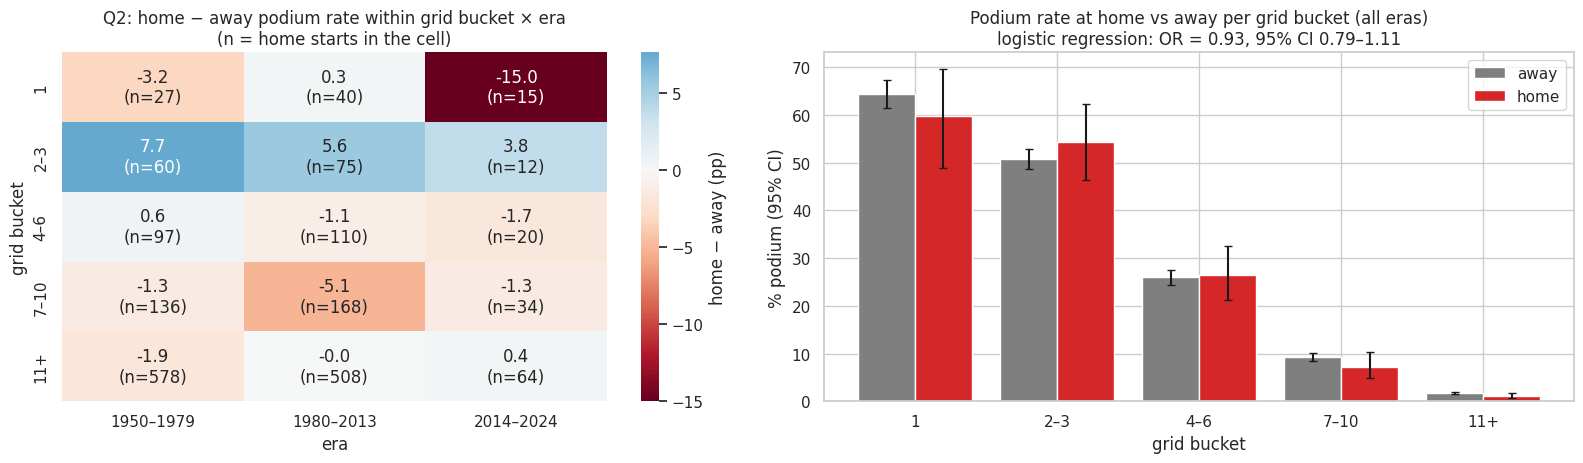

In [25]:
import statsmodels.formula.api as smf

# DECISION D10 → see DECISIONS.md  (nationality -> country mapping, grid bucket × era control, logistic regression)
NAT_TO_COUNTRY = {
    "American": "USA", "American-Italian": ["USA", "Italy"], "Argentine": "Argentina", "Argentine-Italian": ["Argentina", "Italy"],
    "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium", "Brazilian": "Brazil",
    "British": "UK", "Canadian": "Canada", "Chinese": "China", "Dutch": "Netherlands",
    "East German": "Germany", "French": "France", "German": "Germany", "Hungarian": "Hungary",
    "Indian": "India", "Italian": "Italy", "Japanese": "Japan", "Malaysian": "Malaysia",
    "Mexican": "Mexico", "Monegasque": "Monaco", "Portuguese": "Portugal", "Russian": "Russia",
    "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden", "Swiss": "Switzerland",
}
q2 = (results_clean
      .merge(df["races"][["raceId", "circuitId"]], on="raceId", how="left")
      .merge(df["circuits"][["circuitId", "country"]], on="circuitId", how="left")
      .merge(df["drivers"][["driverId", "nationality"]], on="driverId", how="left"))
def home_flag(nationality, country):
    """1 if the circuit's country is one of the driver's countries (a dual nationality counts both), else 0."""
    countries = nationality.map(lambda n: NAT_TO_COUNTRY.get(n, []))
    countries = countries.map(lambda v: v if isinstance(v, list) else [v])
    return np.array([c in cs for cs, c in zip(countries, country)], dtype=int)

# Home race = the country the circuit is in is (one of) the driver's countries, from his nationality.
q2["home"] = home_flag(q2["nationality"], q2["country"])
all_countries = {c for v in NAT_TO_COUNTRY.values() for c in (v if isinstance(v, list) else [v])}
print("Nationalities with no circuit country (never at home):", sorted(set(q2["nationality"]) - set(NAT_TO_COUNTRY)))
print("Circuit countries with no driver nationality mapped to them:", sorted(set(q2["country"]) - all_countries))
dual = q2[q2["nationality"].map(lambda n: isinstance(NAT_TO_COUNTRY.get(n), list))]
print("Starts by drivers with two nationalities:", dual.groupby(["nationality", "country"]).agg(starts=("home", "size"), home=("home", "sum")).to_dict("index"))
print(f"Home starts: {int(q2['home'].sum())} of {len(q2)} driver-race rows")

# Strata for the control: compare home vs away only between drivers who started in a similar place, in the same era.
q2["grid_bucket"] = pd.cut(q2["grid_clean"], [0, 1, 3, 6, 10, 99], labels=["1", "2–3", "4–6", "7–10", "11+"])
q2["era"] = pd.cut(q2["year"], [1949, 1979, 2013, 2024], labels=["1950–1979", "1980–2013", "2014–2024"])

def stratified_effect(d, strata):
    """Within-stratum podium-rate difference (home − away), weighted by home starts per stratum."""
    g = d.groupby(strata + ["home"], observed=True)["podium"].agg(["sum", "size"]).unstack("home").dropna()
    rate_h, rate_a, w = g[("sum", 1)] / g[("size", 1)], g[("sum", 0)] / g[("size", 0)], g[("size", 1)]
    return float(((rate_h - rate_a) * w).sum() / w.sum())

GE = ["grid_bucket", "era"]
raw_diff, grid_diff, main_diff = (100 * stratified_effect(q2.assign(all="all"), ["all"]),
                                  100 * stratified_effect(q2, ["grid_bucket"]), 100 * stratified_effect(q2, GE))
print(f"Home − away podium rate: raw {raw_diff:+.2f} pp | within grid bucket {grid_diff:+.2f} pp | "
      f"within grid bucket × era (main) {main_diff:+.2f} pp")

# The control as a pivot table (as in Lab 1): home − away podium rate in every grid bucket × era cell.
cell_rates = q2.pivot_table(index="grid_bucket", columns=["era", "home"], values="podium", aggfunc="mean", observed=True)
cell_n = q2[q2["home"] == 1].pivot_table(index="grid_bucket", columns="era", values="podium", aggfunc="size", observed=True)
home_minus_away = 100 * (cell_rates.xs(1, axis=1, level="home") - cell_rates.xs(0, axis=1, level="home"))
print("Home − away podium rate (pp) per grid bucket × era:")
display(home_minus_away.round(1))

# The test: logistic regression, odds ratio of a podium at home, holding grid slot (1..20, 21+) and era fixed.
q2["grid_cat"] = q2["grid_clean"].clip(upper=21)
logit = smf.logit("podium ~ home + C(grid_cat) + C(era)", data=q2).fit(disp=0, cov_type="cluster", cov_kwds={"groups": q2["raceId"]})
or_, (or_lo, or_hi) = np.exp(logit.params["home"]), np.exp(logit.conf_int().loc["home"])
print(f"Logistic regression (clustered by race): odds ratio for home = {or_:.2f} (95% CI {or_lo:.2f}–{or_hi:.2f}), p = {logit.pvalues['home']:.2f}")

# Evidence for the "one-off local drivers" explanation of the raw gap
career = results_clean.groupby("driverId").size()
q2["career_starts"] = q2["driverId"].map(career)
print("Share of starts by drivers with ≤ 5 career starts — home: "
      f"{(q2.loc[q2['home'] == 1, 'career_starts'] <= 5).mean():.1%}, away: {(q2.loc[q2['home'] == 0, 'career_starts'] <= 5).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
annot = home_minus_away.round(1).astype(str) + "\n(n=" + cell_n.reindex_like(home_minus_away).fillna(0).astype(int).astype(str) + ")"
sns.heatmap(home_minus_away, annot=annot, fmt="", cmap="RdBu", center=0, ax=axes[0], cbar_kws={"label": "home − away (pp)"})
axes[0].set_title("Q2: home − away podium rate within grid bucket × era\n(n = home starts in the cell)")
axes[0].set_xlabel("era"); axes[0].set_ylabel("grid bucket")
strat = q2.groupby(["grid_bucket", "home"], observed=True)["podium"].agg(["sum", "size"]).unstack("home")
x = np.arange(len(strat))
for h, col, off, lab in [(0, "tab:gray", -0.2, "away"), (1, "tab:red", 0.2, "home")]:
    k, n = strat[("sum", h)], strat[("size", h)]
    lo, hi = wilson(k, n)
    axes[1].bar(x + off, k / n * 100, 0.4, color=col, label=lab, yerr=[(k / n - lo) * 100, (hi - k / n) * 100], capsize=3)
axes[1].set_xticks(x); axes[1].set_xticklabels(strat.index)
axes[1].set_xlabel("grid bucket"); axes[1].set_ylabel("% podium (95% CI)"); axes[1].legend()
axes[1].set_title(f"Podium rate at home vs away per grid bucket (all eras)\nlogistic regression: OR = {or_:.2f}, 95% CI {or_lo:.2f}–{or_hi:.2f}")
save_fig("09_q2_home")


**How to read the numbers in this section**

* **home − away (pp)**: the podium rate at home minus the podium rate away, in **percentage points** (pp). Example: if home drivers podium 12% of the time and away drivers 14%, home − away = 12 − 14 = **−2 pp**. Negative = drivers do *worse* at home, positive = better, 0 = no difference. We say "percentage points" and not "%" because it is a difference between two percentages (12% → 14% is 2 points, not 2%).
* **Grid bucket** (rows of the heatmap, x-axis of the right plot): groups of **starting-grid slots**, not eras. **1** = started from pole position (1st on the grid); **2–3** = started 2nd or 3rd; **4–6** = 4th to 6th; **7–10** = 7th to 10th; **11+** = 11th or further back. The right plot pools all eras: for each grid bucket it compares the podium rate of drivers at home (red) and away (gray), with 95% Wilson intervals.
* **Era**: a separate split by season: **1950–1979**, **1980–2013**, **2014–2024**. It is needed because the chance of a podium from a given grid slot changed over time (Section 4).
* **Stratum (group)**: one grid bucket in one era, e.g. "started 2nd–3rd in 1980–2013". There are 5 × 3 = 15 groups. Comparing home vs away *inside* a group means we compare drivers who started in a similar place in the same era, so a home driver who started from the back is not compared with an away driver who started on pole. The heatmap (left plot) is this pivot table: one cell per group, showing home − away and the number of home starts *n*.
* **Controlled estimate**: home − away is computed inside each group, then averaged across groups, giving each group a weight equal to its number of home starts (groups with more home races count more).
* **Raw estimate**: home − away over all rows, without groups.
* **Odds ratio** (logistic regression): another way to measure the same thing. 1 = no home effect, above 1 = more podiums at home, below 1 = fewer. If its interval includes 1 (and p > 0.05), there is no evidence of an effect.
* **Clustered by race**: the drivers of one race are not independent (only three of them can podium, and rain or a safety car affects them all), so the regression treats each race as one unit when it computes the interval; otherwise it would count 20 linked rows as 20 separate pieces of evidence and the interval would come out too narrow.

**Answer to Q2** *(numbers from the output above)*

* **Raw comparison:** home drivers podium **2.1 percentage points less** often than away drivers. This is a composition effect: 13.1% of home starts come from drivers with five or fewer career starts (one-off local entrants in uncompetitive cars), against 1.4% of away starts.
* **Controlled for starting position:** comparing home and away drivers from the same grid bucket, the difference shrinks to **−0.6 pp**; adding era gives **−0.8 pp**. Controlling removes most of the raw gap: (2.12 − 0.83) ÷ 2.12 ≈ 61%. The heatmap shows no consistent direction: the 15 cells range from −15.0 to +7.7 pp, with signs in both directions in every era.
* **The test:** the logistic regression, holding grid slot and era fixed and clustered by race, gives an odds ratio for racing at home of **0.93 (95% CI 0.79–1.11, p = 0.43)**. The interval includes 1 (no effect).
* **Conclusion: we find no evidence that drivers podium more often at home once starting position is accounted for.**
* This is an association, not a causal effect.

**Grain / missingness / cutoff.** One row per driver-race. Nationality and circuit country have no missing values; unmapped nationalities are "away" by construction. Nationality, circuit and grid are all known before the race, so a `home_race` flag would be a legal feature; it was built as a candidate in the context group, but it shows no signal (Section 6.7) and is not a model input (D30).

---
### 5.3 Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Tables joined:** `results` ⨝ `races` ⨝ `status` (category, D3) ⨝ `constructors`.
**Grain:** one row per car that took the start; aggregated to one row per team lineage per period.

🔶 **Decision D11 — how Q3 is measured.**
* Rate = mechanical retirements ÷ **race starts** of that constructor in the period. Following the brief's definition ("a race start that ended early"), cars that were on the grid but **did not take the start** (e.g. Leclerc's driveshaft failure before the start at Monaco 2021) are not race starts and are not counted.
* *Mechanical* = status category `mechanical` (D3): the label names a failed car component. Crashes, driver causes, regulation decisions, team pit errors and ambiguous labels are not mechanical. As a robustness check we also report a *broad* rate that adds the ambiguous labels.
* Teams are grouped by **lineage**: a renamed team keeps its factory, staff and car design but gets a new `constructorId`, and four renames fall right on the period boundary (Racing Point → Aston Martin and Renault → Alpine in 2021, AlphaTauri → RB and Alfa Romeo → Sauber in 2024). By `constructorId`, "Alpine 2014–2021" would be one season and "RB 2022–2024" only 2024. A small hand-written dictionary joins Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin, Lotus F1 → Renault → Alpine, Sauber ↔ Alfa Romeo and Marussia → Manor; the dictionary is printed in the output below so it can be checked. We only rank lineages with **at least 30 starts** in a period, show 95% Wilson intervals, and test whether teams differ at all (chi-square).

Constructor names grouped into one lineage: {'Force India → Racing Point → Aston Martin': ['Aston Martin', 'Force India', 'Racing Point'], 'Lotus F1 → Renault → Alpine': ['Alpine F1 Team', 'Lotus F1', 'Renault'], 'Marussia → Manor': ['Manor Marussia', 'Marussia'], 'Sauber ↔ Alfa Romeo': ['Alfa Romeo', 'Sauber'], 'Toro Rosso → AlphaTauri → RB': ['AlphaTauri', 'RB F1 Team', 'Toro Rosso']}

2014–2021: overall mechanical-retirement rate = 0.089 | teams differ? chi-square p = 3.72e-08


,starts,mech,mech_broad,rate,rate_broad,ci_low,ci_high,rank strict,rank broad
constructor,,,,,,,,,
Caterham,33,7,10,0.212,0.303,0.107,0.378,1,1
Toro Rosso → AlphaTauri → RB,319,46,52,0.144,0.163,0.110,0.187,2,3
Lotus F1 → Renault → Alpine,318,42,54,0.132,0.170,0.099,0.174,3,2
McLaren,316,41,49,0.130,0.155,0.097,0.171,4,4
Red Bull,318,34,37,0.107,0.116,0.078,0.146,5,5
Sauber ↔ Alfa Romeo,319,25,31,0.078,0.097,0.054,0.113,6,7
Haas F1 Team,241,18,28,0.075,0.116,0.048,0.115,7,6
Williams,319,23,31,0.072,0.097,0.049,0.106,8,7
Marussia → Manor,108,7,9,0.065,0.083,0.032,0.128,9,9



2022–2024: overall mechanical-retirement rate = 0.055 | teams differ? chi-square p = 0.183


,starts,mech,mech_broad,rate,rate_broad,ci_low,ci_high,rank strict,rank broad
constructor,,,,,,,,,
Lotus F1 → Renault → Alpine,135,14,14,0.104,0.104,0.063,0.167,1,1
Sauber ↔ Alfa Romeo,136,12,14,0.088,0.103,0.051,0.148,2,2
Toro Rosso → AlphaTauri → RB,136,8,12,0.059,0.088,0.030,0.112,3,3
Williams,134,7,11,0.052,0.082,0.026,0.104,4,4
Ferrari,134,6,9,0.045,0.067,0.021,0.094,5,5
Haas F1 Team,135,6,7,0.044,0.052,0.021,0.094,6,7
Mercedes,136,6,6,0.044,0.044,0.020,0.093,7,8
Force India → Racing Point → Aston Martin,134,5,9,0.037,0.067,0.016,0.084,8,5
McLaren,136,5,5,0.037,0.037,0.016,0.083,9,10


Teams present in both periods: 10 | Spearman ρ of their rates = 0.27 (p = 0.45)


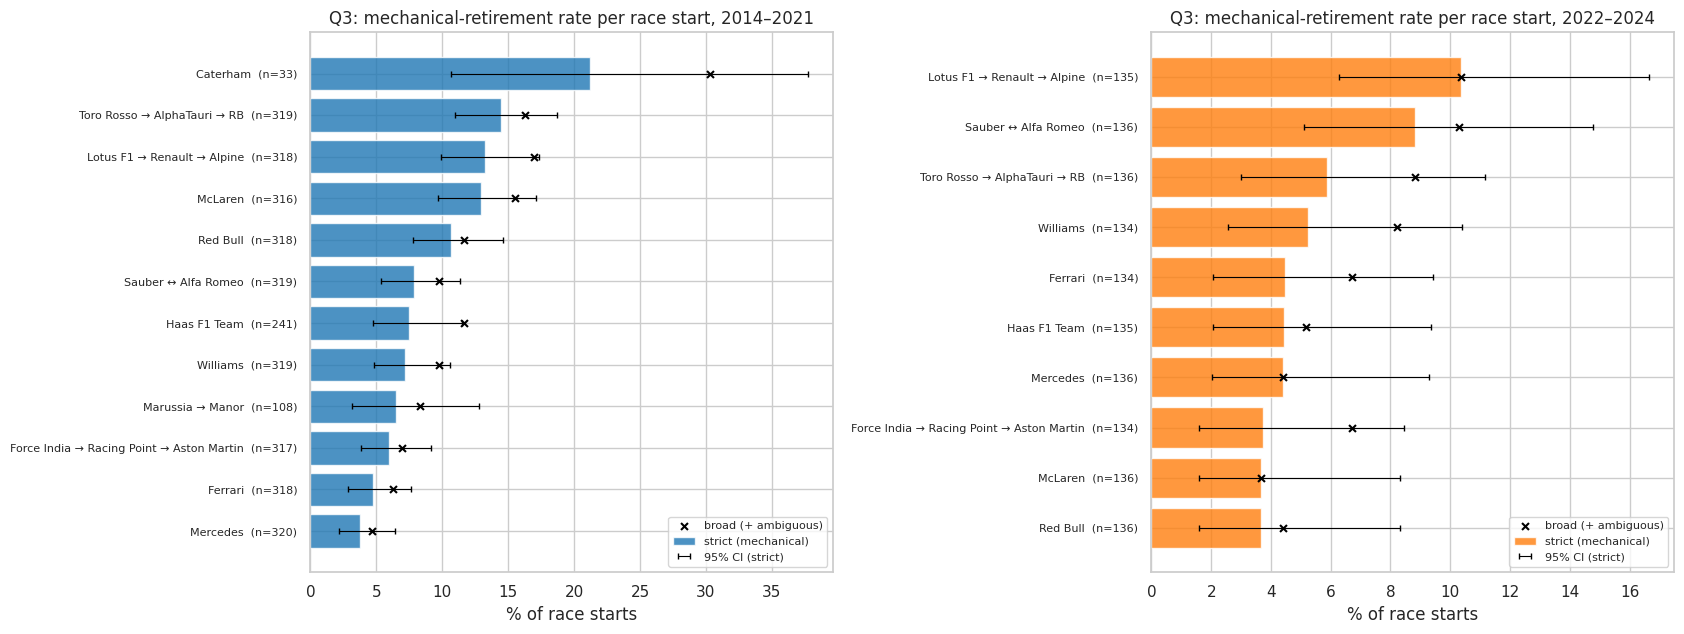

In [26]:
# DECISION D11 → see DECISIONS.md  (team lineage, denominator = race starts, strict vs broad mechanical, min 30 starts, intervals)
# A renamed team keeps its factory, staff and car design, but gets a new constructorId. Four renames fall on the
# 2021/2022 period boundary, so we group constructors by LINEAGE: each team is compared with itself.
LINEAGE = {
    "Toro Rosso": "Toro Rosso → AlphaTauri → RB", "AlphaTauri": "Toro Rosso → AlphaTauri → RB", "RB F1 Team": "Toro Rosso → AlphaTauri → RB",
    "Force India": "Force India → Racing Point → Aston Martin", "Racing Point": "Force India → Racing Point → Aston Martin",
    "Aston Martin": "Force India → Racing Point → Aston Martin",
    "Lotus F1": "Lotus F1 → Renault → Alpine", "Renault": "Lotus F1 → Renault → Alpine", "Alpine F1 Team": "Lotus F1 → Renault → Alpine",
    "Sauber": "Sauber ↔ Alfa Romeo", "Alfa Romeo": "Sauber ↔ Alfa Romeo",
    "Marussia": "Marussia → Manor", "Manor Marussia": "Marussia → Manor",
}
q3 = results_clean[results_clean["year"].between(2014, 2024) & results_clean["started_race"]].merge(
    df["constructors"][["constructorId", "name"]].rename(columns={"name": "team_name"}), on="constructorId", how="left")
q3["constructor"] = q3["team_name"].map(LINEAGE).fillna(q3["team_name"])      # teams that were never renamed keep their name
print("Constructor names grouped into one lineage:",
      {lin: sorted(set(q3.loc[q3["constructor"] == lin, "team_name"])) for lin in sorted(set(LINEAGE.values()))})
q3["period"] = np.where(q3["year"] <= 2021, "2014–2021", "2022–2024")
# Strict: only labels where a car component failed (D3). Broad: also the ambiguous labels, as a robustness check.
q3["mech"] = (q3["category"] == "mechanical").astype(int)
q3["mech_broad"] = q3["category"].isin(["mechanical", "ambiguous"]).astype(int)

agg = q3.groupby(["period", "constructor"]).agg(starts=("mech", "size"), mech=("mech", "sum"), mech_broad=("mech_broad", "sum"))
agg["rate"] = agg["mech"] / agg["starts"]
agg["rate_broad"] = agg["mech_broad"] / agg["starts"]
agg["ci_low"], agg["ci_high"] = wilson(agg["mech"], agg["starts"])
agg = agg[agg["starts"] >= 30]                     # D11: below 30 starts one or two failures swing the rate too much

PERIODS3 = ["2014–2021", "2022–2024"]
for p in PERIODS3:
    t = agg.loc[p].sort_values("rate", ascending=False)
    t["rank strict"] = t["rate"].rank(ascending=False, method="min").astype(int)
    t["rank broad"] = t["rate_broad"].rank(ascending=False, method="min").astype(int)
    tab = np.c_[t["mech"], t["starts"] - t["mech"]]
    print(f"\n{p}: overall mechanical-retirement rate = {q3.loc[q3['period'] == p, 'mech'].mean():.3f} | "
          f"teams differ? chi-square p = {chi2_contingency(tab)[1]:.3g}")
    display(t.round(3))
both = agg["rate"].unstack("period").dropna()
print(f"Teams present in both periods: {len(both)} | Spearman ρ of their rates = {spearmanr(both[PERIODS3[0]], both[PERIODS3[1]])[0]:.2f} "
      f"(p = {spearmanr(both[PERIODS3[0]], both[PERIODS3[1]])[1]:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, p, col in zip(axes, PERIODS3, ["tab:blue", "tab:orange"]):
    t = agg.loc[p].sort_values("rate")
    y = np.arange(len(t))
    ax.barh(y, t["rate"] * 100, color=col, alpha=0.8, label="strict (mechanical)")
    ax.errorbar(t["rate"] * 100, y, xerr=[(t["rate"] - t["ci_low"]) * 100, (t["ci_high"] - t["rate"]) * 100],
                fmt="none", ecolor="black", capsize=2, lw=0.8, label="95% CI (strict)")
    ax.scatter(t["rate_broad"] * 100, y, color="black", marker="x", s=25, zorder=3, label="broad (+ ambiguous)")
    ax.set_yticks(y); ax.set_yticklabels([f"{c}  (n={n})" for c, n in zip(t.index, t["starts"])], fontsize=8)
    ax.set_title(f"Q3: mechanical-retirement rate per race start, {p}")
    ax.set_xlabel("% of race starts"); ax.legend(loc="lower right", fontsize=8)
save_fig("10_q3_mechanical")

**How to read the Q3 tables** (one row per team lineage; only lineages with at least 30 starts in the period)

* **starts**: how many times the team's cars took the start in that period (2 cars per race, so about 40 starts per season). This is the denominator of every rate.
* **mech**: how many of those starts ended in a **mechanical** retirement (strict definition: the status names a failed car part, e.g. "Engine", "Gearbox", "Hydraulics").
* **mech_broad**: the same count plus retirements with an **ambiguous** label (e.g. "Retired"), which may or may not be mechanical.
* **rate** = mech ÷ starts: the share of starts lost to a mechanical failure. Example: Caterham 7 ÷ 33 = 0.212, so 21.2% of its starts ended with a broken car.
* **rate_broad** = mech_broad ÷ starts: the same rate under the broad definition.
* **ci_low / ci_high**: the 95% confidence interval (Wilson method) of the strict rate. Caterham's true rate is probably between 10.7% and 37.8%; the interval is wide because it had only 33 starts. When two teams' intervals overlap a lot, we cannot say one is really less reliable than the other.
* **rank strict / rank broad**: the team's place when sorted by each rate (1 = most mechanical failures). If a team's two ranks are close, its position does not depend on how "mechanical" is defined.
* **Chi-square p** (line above each table): the chance that differences between teams this large appear by luck alone, if all teams were equally reliable. Below 0.05, teams really differ.
* **Spearman ρ** (line after the tables): do the teams that failed most in 2014–2021 also fail most in 2022–2024? +1 = same order, 0 = unrelated, −1 = reversed.
* In the bar chart, each bar is the strict rate with its 95% interval, the black × is the broad rate, and *n* is the number of starts.

**Answer to Q3** *(numbers from the output above)*

* **2014–2021 (overall 8.9% of race starts):** the highest rates belong to **Caterham (21.2%, n = 33)**, **Toro Rosso → AlphaTauri → RB (14.4%)**, **Lotus F1 → Renault → Alpine (13.2%)** and **McLaren (13.0%)**; the lowest to **Mercedes (3.8%)**, the dominant team of that period, Ferrari (4.7%) and Force India → Racing Point → Aston Martin (6.0%). Teams differ clearly (chi-square p < 0.001).
* **2022–2024 (overall 5.5%):** the highest are **Lotus F1 → Renault → Alpine (10.4%, 95% CI 6–17%)**, **Sauber ↔ Alfa Romeo (8.8%)** and **Toro Rosso → AlphaTauri → RB (5.9%)**; the lowest McLaren, Red Bull and Force India → Racing Point → Aston Martin (3.7% each). Here the differences between teams are **not significant** (chi-square p = 0.18) and the intervals overlap, so the 2022–2024 order is weak evidence.
* **Change between periods:** mechanical failures became rarer overall (8.9% → 5.5%) and for almost every lineage: McLaren (13.0% → 3.7%), Red Bull (10.7% → 3.7%) and Toro Rosso → AlphaTauri → RB (14.4% → 5.9%) improved most. Only Sauber ↔ Alfa Romeo (7.8% → 8.8%) and Mercedes (3.8% → 4.4%) rose slightly. For the 10 lineages present in both periods the rank correlation is +0.27 (p = 0.45): no evidence that the same teams stay the least reliable. (Grouped by `constructorId` instead, the same correlation came out −0.49, because renamed teams were split across the period boundary.)
* **Robustness.** Adding the ambiguous labels (broad rate) keeps the same top four in 2014–2021 (Caterham, the two renamed lineages and McLaren) and the same top three in 2022–2024.

**Grain / missingness / cutoff.** One row per car that took the start; status has no missing values. Status is **post-race** information: it is used only for this analysis and never as a feature for the current race. A constructor's *past* reliability is a legal feature when computed only from earlier races, which is what `con_mech_rate_last10` does (Section 6).

## 6. Feature engineering (leakage-safe)

**The rule for every feature:** it must be known *after qualifying and before the race starts*. Anything from the current race's result (position, points, laps, status, pit stops, lap times, fastest lap) and the standings published *after* the current race are forbidden.

We build five **feature groups**. The groups are used again in the ablation (Section 10).

🔶 **Decision D16 — feature groups**

| group | features | why it should help (hypothesis from EDA) |
|---|---|---|
| **grid** | `grid_pos`, `grid_pct` (candidate not used: `pit_lane_start`) | Section 4(d): podium rate falls steeply with grid slot |
| **qualifying** | `quali_position`, `quali_gap_pct`, `grid_penalty` | Q1: qualifying pace and penalties change podium chances |
| **standings** | driver & constructor points share, rank and win share **before** this race | Section 4: one constructor often dominates a season |
| **form** | driver & constructor podium rate / average finish over their last 5 races, constructor mechanical-failure rate over last 10 | recent results and reliability (Q3) differ by team |
| **context** | `driver_age`, `experience` (candidates not used: `home_race`, `field_size`) | field size sets the base rate; Q2 tests home advantage |

We build **21 candidate features** and check all of them in 6.7. The models use **18**: the three candidates with no signal in 6.7 are not model inputs (D30), and Section 10 adds each of them back to every model to check that this costs nothing.

🔶 **Decision D17 (part 1) — the training window uses every season before validation: 1950–2019.** Leaving seasons out throws away data, so it needs evidence that a shorter window predicts better, not only a domain argument. Qualifying was not recorded before 1994 (Section 2.3), but this does not stop older seasons from being used: the grid position, which exists for every season, carries almost the same information as the qualifying position (they differ only when a penalty moves a car, Section 4 and 6.7), and missing qualifying values are filled and flagged by the preprocessing (D19). Section 8.4 trains the models on later start years and scores them on the same validation seasons; a later start would only be used if it clearly beat 1950. Feature evidence in 6.7 is computed on the training seasons.

In [27]:
# DECISION D17 → see DECISIONS.md  (training window 1950–2019: every season before validation; checked in 8.4)
TRAIN_START, TRAIN_END, VAL_END = 1950, 2019, 2021

### 6.1 Base table and race order

Every past-only feature needs a strict notion of "earlier". We order races by date (then by `raceId` as a tie-breaker) and give every race a running index `race_seq`.

In [29]:
races = df["races"][["raceId", "year", "round", "circuitId", "date"]].sort_values(["date", "raceId"]).reset_index(drop=True)
races["race_seq"] = np.arange(len(races))     # 0, 1, 2, ... in chronological order
assert not races["date"].duplicated().any(), "two races on the same date: order would be ambiguous"

base = results_clean[["raceId", "driverId", "constructorId", "year", "grid_clean", "pit_lane_start", "started_race",
                      "field_size", "finish_rank", "category", "podium"]].copy()
base = base.merge(races[["raceId", "round", "circuitId", "date", "race_seq"]], on="raceId", how="left", validate="many_to_one")
base = base.sort_values(["race_seq", "grid_clean"]).reset_index(drop=True)
print(base.shape)

(24715, 15)


### 6.2 Grid group

* `grid_pos`: starting slot after penalties, re-ranked among the cars on the grid (D7).
* `grid_pct`: the same slot as a fraction of the field (0 = pole, 1 = last). P10 in a 30-car field is not the same as P10 in a 20-car field.
* `pit_lane_start`: flag from D7. Built as a candidate but not a model input (no signal in 6.7, D30); a pit-lane start is already in `grid_pos` as the last slot.

In [30]:
base["grid_pos"] = base["grid_clean"]
base["grid_pct"] = (base["grid_clean"] - 1) / (base["field_size"] - 1)
assert base["grid_pct"].between(0, 1).all()

### 6.3 Qualifying group

🔶 **Decision D15 — qualifying features.**
* We do **not** use raw lap times (`q1_sec`, `q2_sec`, `q3_sec`) as features. A pole lap at Monaco (~70 s) and at Spa (~105 s) are not comparable, so the model would partly learn track length.
* `quali_gap_pct` = how far the driver's **Q1** lap is from the fastest Q1 lap of that race, in percent. We use Q1 because it is the only session every driver ran: comparing a Q3 lap with a Q1 lap mixes different track conditions, and in 2006–2009 the final session was even run with race fuel loads, so "best lap of any session" was not a fair comparison. Laps more than 20% off the fastest are not a real attempt (a car that stopped or crashed); they are rare (see the plot) and are set to missing.
* `grid_penalty` = `grid_pos − reference slot` (positive = moved back). The reference is the qualifying position, except on the **2021–2022 sprint weekends**, where the sprint set the grid and the reference is the sprint finishing position. Without this, sprint overtakes would be counted as "penalties".
* Qualifying data only exists from 1994 (complete from 2003). In the table, missing qualifying stays **NaN**. The model pipeline later fills it with the training median *and* adds a "was missing" indicator column (D19), so the model can tell "not recorded" (old seasons) from "slow".

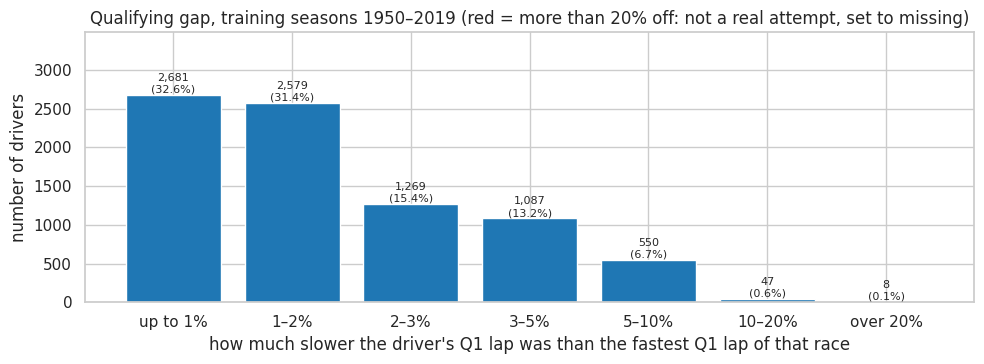

Q1 laps more than 20% slower than the fastest (a car that stopped or crashed, set to missing): 10 of 10,338 in all seasons (8 in the training seasons, the red bar above).
Qualifying position is available for 37% of training rows (1950–2019) and 42% of all rows (1950–2024); qualifying was not recorded before 1994.
164 drivers have a qualifying position but no usable Q1 lap time, so their gap is missing.
32 pole-sitters were more than 1% off the fastest Q1 lap. Pole is decided in the last session (Q3), so the fastest car in Q1 is often someone else: the gap shows pace across the whole field, and quali_position decides the very front.

The three qualifying features on the training rows (1950–2019):


,typical value (median),middle half of drivers,min,max,% missing
quali_position,11.0,6.00 to 17.00,1.0,26.0,63%
quali_gap_pct,1.5,0.79 to 2.63,0.0,19.67,64%
grid_penalty,0.0,0.00 to 0.00,-9.0,23.0,63%


Grid slot compared with qualifying position (training rows with qualifying data):


,drivers,% of drivers
moved back (penalty or pit-lane start),404,4.8
no change,6497,77.8
moved forward (others penalised or not starting),1447,17.3


In [31]:
q = df["qualifying"][["raceId", "driverId", "position", "q1_sec"]].copy()
q["q1_best"] = q.groupby("raceId")["q1_sec"].transform("min")      # fastest Q1 lap of anyone in that race
q["quali_gap_pct"] = (q["q1_sec"] / q["q1_best"] - 1) * 100
q = q.merge(races[["raceId", "year"]], on="raceId", how="left")
in_window = q["year"].between(TRAIN_START, TRAIN_END)          # the cutoff is chosen on training seasons only

# How far off the fastest Q1 lap drivers were, in a few readable bands (training seasons).
bands = pd.cut(q.loc[in_window, "quali_gap_pct"].dropna(), [-np.inf, 1, 2, 3, 5, 10, 20, np.inf],
               labels=["up to 1%", "1–2%", "2–3%", "3–5%", "5–10%", "10–20%", "over 20%"])
counts = bands.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.bar(counts.index.astype(str), counts.values, color=["tab:blue"] * 6 + ["tab:red"])
for b, n in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{n:,}\n({n / counts.sum():.1%})", ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, counts.max() * 1.3)
ax.set_xlabel("how much slower the driver's Q1 lap was than the fastest Q1 lap of that race")
ax.set_ylabel("number of drivers")
ax.set_title(f"Qualifying gap, training seasons {TRAIN_START}–{TRAIN_END} (red = more than 20% off: not a real attempt, set to missing)")
save_fig("11a_quali_gap_cutoff")
print(f"Q1 laps more than 20% slower than the fastest (a car that stopped or crashed, set to missing): "
      f"{int((q['quali_gap_pct'] > 20).sum())} of {int(q['quali_gap_pct'].notna().sum()):,} in all seasons "
      f"({int(counts['over 20%'])} in the training seasons, the red bar above).")
q.loc[q["quali_gap_pct"] > 20, "quali_gap_pct"] = np.nan

# DECISION D15 → see DECISIONS.md  (position + Q1 gap %, not raw lap times; penalty vs the right reference slot)
base = base.merge(q[["raceId", "driverId", "position", "quali_gap_pct"]].rename(columns={"position": "quali_position"}),
                  on=["raceId", "driverId"], how="left", validate="one_to_one")
sprint_pos = df["sprint_results"].set_index(["raceId", "driverId"])["positionOrder"]
sprint_set_grid = base["raceId"].isin(set(df["sprint_results"]["raceId"])) & base["year"].between(2021, 2022)
reference = base["quali_position"].copy()
reference[sprint_set_grid] = [sprint_pos.get(k, np.nan) for k in zip(base.loc[sprint_set_grid, "raceId"], base.loc[sprint_set_grid, "driverId"])]
base["grid_penalty"] = base["grid_pos"] - reference

train = base["year"].between(TRAIN_START, TRAIN_END)
print(f"Qualifying position is available for {base.loc[train, 'quali_position'].notna().mean():.0%} of training rows "
      f"({TRAIN_START}–{TRAIN_END}) and {base['quali_position'].notna().mean():.0%} of all rows ({base['year'].min()}–{base['year'].max()}); "
      "qualifying was not recorded before 1994.")
print(f"{int((base['quali_position'].notna() & base['quali_gap_pct'].isna()).sum())} drivers have a qualifying position "
      "but no usable Q1 lap time, so their gap is missing.")
print(f"{int(((base['quali_position'] == 1) & (base['quali_gap_pct'] > 1)).sum())} pole-sitters were more than 1% off the fastest "
      "Q1 lap. Pole is decided in the last session (Q3), so the fastest car in Q1 is often someone else: the gap shows pace "
      "across the whole field, and quali_position decides the very front.")

QUALI = ["quali_position", "quali_gap_pct", "grid_penalty"]
print(f"\nThe three qualifying features on the training rows ({TRAIN_START}–{TRAIN_END}):")
display(pd.DataFrame({c: {"typical value (median)": round(base.loc[train, c].median(), 2),
                          "middle half of drivers": f"{base.loc[train, c].quantile(0.25):.2f} to {base.loc[train, c].quantile(0.75):.2f}",
                          "min": round(base.loc[train, c].min(), 2), "max": round(base.loc[train, c].max(), 2),
                          "% missing": f"{base.loc[train, c].isna().mean():.0%}"} for c in QUALI}).T)

pen = base.loc[train, "grid_penalty"].dropna()
moves = pd.Series({"moved back (penalty or pit-lane start)": (pen > 0).sum(), "no change": (pen == 0).sum(),
                   "moved forward (others penalised or not starting)": (pen < 0).sum()})
print("Grid slot compared with qualifying position (training rows with qualifying data):")
display(pd.DataFrame({"drivers": moves, "% of drivers": (100 * moves / moves.sum()).round(1)}))

### 6.4 Standings group — the "shift" that prevents leakage

> 💬 **In plain words.** The standings table for a race already contains that race's points, so using it would tell the model the answer. We therefore always use the table from *before* the race: the one published after the previous race (or, for a season's first race, last season's final table). Example: before the 2023 Belgian GP Verstappen had 281 points; the 314 he had after it are never used.

`driver_standings` and `constructor_standings` hold the championship table **after** each race, so the row for race N already contains race N's points. Using it would leak the answer.

🔶 **Decision D13 — standings before the race.**
* For race N we join the standings of the **previous race of the same season**. We do this with an explicit lookup table `raceId → prev_raceId` rather than a row `shift()`, so a driver who missed a race still gets the correct previous table.
* For the **first race of a season** there is no earlier race that year. We use the **final standings of the previous season**: they are known before the opener and describe how strong each driver and team was. That table describes a whole season rather than a few races. We do not add a flag `season_opener` to tell the two cases apart: whether a race is an opener says nothing by itself about who finishes on the podium (every race has three podiums), and both kinds of table describe how strong the driver and the team are (D13). The opener rule is only used in the code, to choose which table to join.
* A driver or team that does not appear in the previous table (no points yet, or new) gets 0 points, no wins and the rank after the last ranked entry.
* Points systems changed (a win was worth 8, 9, 10 and now 25 points) and season lengths changed (7 to 24 races), so we use **points as a share of the leader's points**, the **rank**, and **wins as a share of the races run so far**, which mean the same thing in every era.
* Exclusions from a championship (Schumacher 1997, McLaren's constructors' result 2007) were decided **at or after the end of the season**, although the data flags McLaren as excluded in every 2007 table. So during a season we use the points as they were published (McLaren was leading in mid-2007); only the previous season's **final** table used for an opener applies the exclusion (0 points, never the leader), because by then it was known.

🔶 **Decision D12 — sprint results are not used as features (except as the grid reference in D15).** A sprint runs before the main race, so it is technically pre-race information. But sprints only exist from 2021: they are **absent from every training season** (1950–2019), so a model could not learn anything from them, and in 2021–22 the sprint result *was* the grid, which `grid_pos` already contains. The standings we join (from the *previous* race) already include earlier weekends' sprint points.

In [32]:
# prev_raceId: the race whose standings describe the situation just before this race.
season_order = races.sort_values(["year", "round"]).copy()
season_order["prev_raceId"] = season_order.groupby("year")["raceId"].shift(1)        # previous race, same season
last_of_season = season_order.groupby("year")["raceId"].last()                      # final race of each season
openers = season_order["prev_raceId"].isna()
season_order.loc[openers, "prev_raceId"] = season_order.loc[openers, "year"].map(lambda y: last_of_season.get(y - 1, np.nan))
prev_map = season_order.set_index("raceId")["prev_raceId"]
base["prev_raceId"] = base["raceId"].map(prev_map)
races_so_far = races.set_index("raceId")["round"]               # races completed when the prev_raceId table was published

def standings_before(table, key, prefix, apply_exclusions):
    """Standings after prev_raceId: share of the leader's points, rank, and wins per race run so far.
    apply_exclusions: True only for previous-season FINAL tables (exclusions were decided at season end)."""
    st = df[table][["raceId", key, "points", "position", "positionText", "wins"]].copy()
    if apply_exclusions:
        excluded = ~st["positionText"].astype(str).str.isdigit()              # 'D' / 'E' = excluded from that championship
        st.loc[excluded, ["points", "wins"]] = 0
        st.loc[excluded, "position"] = np.nan
    st["leader_pts"] = st.groupby("raceId")["points"].transform("max")
    st[f"{prefix}_pts_share_before"] = np.where(st["leader_pts"] > 0, st["points"] / st["leader_pts"], 0.0)
    st[f"{prefix}_rank_before"] = st["position"]
    st[f"{prefix}_win_share_before"] = st["wins"] / st["raceId"].map(races_so_far)
    st = st.rename(columns={"raceId": "prev_raceId"})
    return st[["prev_raceId", key, f"{prefix}_pts_share_before", f"{prefix}_rank_before", f"{prefix}_win_share_before"]]

# DECISION D13 → see DECISIONS.md  (standings from the previous race / previous season's final table)
# DECISION D12 → see DECISIONS.md  (sprint_results is deliberately NOT joined as a feature)
for table, key, prefix in [("driver_standings", "driverId", "drv"), ("constructor_standings", "constructorId", "con")]:
    st_in, st_final = standings_before(table, key, prefix, False), standings_before(table, key, prefix, True)
    cols = [c for c in st_in.columns if c.startswith(prefix)]
    m_in = base[["prev_raceId", key]].merge(st_in, on=["prev_raceId", key], how="left", validate="many_to_one")
    m_fin = base[["prev_raceId", key]].merge(st_final, on=["prev_raceId", key], how="left", validate="many_to_one")
    opener = (base["round"] == 1).to_numpy()          # season opener: use the previous season's final table
    for c in cols:                                   # openers: final table with exclusions; in-season: table as published
        base[c] = np.where(opener, m_fin[c].to_numpy(), m_in[c].to_numpy())
    st = st_final
    # Entries with no row (or an excluded row) in the previous table: 0 points, no wins, ranked after the last ranked entry.
    has_table = base["prev_raceId"].isin(st["prev_raceId"])
    worst = st.groupby("prev_raceId")[f"{prefix}_rank_before"].max()
    missing = has_table & base[f"{prefix}_rank_before"].isna()
    base.loc[missing, [f"{prefix}_pts_share_before", f"{prefix}_win_share_before"]] = 0.0
    base.loc[missing, f"{prefix}_rank_before"] = base.loc[missing, "prev_raceId"].map(worst) + 1

# Constructor standings only exist from 1958, and the 1950 opener has no previous season: those stay NaN.
print("Missing driver standings:", int(base["drv_rank_before"].isna().sum()), "rows (1950 opener)",
      "| missing constructor standings:", int(base["con_rank_before"].isna().sum()), "rows (before 1958)")

Missing driver standings: 23 rows (1950 opener) | missing constructor standings: 1181 rows (before 1958)


**Leakage check on the standings.** For a known race we compare the leaky value ("after this race") with our feature ("before this race"). Verstappen at the 2023 Belgian GP had 314 points after the race and 281 before it.

In [33]:
spa23 = races[(races["year"] == 2023) & (races["round"] == 12)]["raceId"].iloc[0]
ver = df["drivers"].loc[df["drivers"]["driverRef"] == "max_verstappen", "driverId"].iloc[0]
after = df["driver_standings"].query("raceId == @spa23 and driverId == @ver")["points"].iloc[0]
before = df["driver_standings"].query("raceId == @prev_map[@spa23] and driverId == @ver")["points"].iloc[0]
ver_row = base.query("raceId == @spa23 and driverId == @ver")
print(f"Points after the race (leaky): {after} | points before the race: {before}")
print(f"Feature used: rank {int(ver_row['drv_rank_before'].iloc[0])}, points share {ver_row['drv_pts_share_before'].iloc[0]:.3f} "
      f"(= {before} / leader's points before the race), win share {ver_row['drv_win_share_before'].iloc[0]:.2f}")

# Every prev_raceId must be strictly earlier in time than the race itself.
seq = races.set_index("raceId")["race_seq"]
assert (base["prev_raceId"].dropna().map(seq).values < base.loc[base["prev_raceId"].notna(), "raceId"].map(seq).values).all()
print("✔ every standings feature comes from a race that happened earlier")

Points after the race (leaky): 314.0 | points before the race: 281.0
Feature used: rank 1, points share 1.000 (= 281.0 / leader's points before the race), win share 0.82
✔ every standings feature comes from a race that happened earlier


**Standings features used by the model (6).** All are taken from the standings table published **after the previous race** (or, at the first race of a season, the previous season's final table), so none of them contains the result of the race being predicted. The raw points, positions and wins are only used to compute them.

| feature | what it measures |
|---|---|
| `drv_pts_share_before` | the driver's championship points ÷ the leader's points (1 = leading the championship, 0.5 = half the leader's points) |
| `drv_rank_before` | the driver's position in the championship (1 = leader) |
| `drv_win_share_before` | the driver's wins ÷ races run so far in the season (0.5 = won half of them) |
| `con_pts_share_before` | the same points share for the driver's team (constructors' championship) |
| `con_rank_before` | the team's position in the constructors' championship |
| `con_win_share_before` | the team's wins ÷ races run so far in the season |

Shares are used instead of raw points and wins because the points for a win (8, 9, 10, now 25) and the number of races per season (7 to 24) changed over time; a share means the same in every era.

### 6.5 Form group — rolling windows over past races only

> 💬 **In plain words.** Form = how a driver or team did in their last few races. To predict a driver's 6th race we average races 1–5; race 6 itself must not be inside the average. `shift(1)` moves every value one race down, so each row only sees the races before it, and `rolling(5)` then averages the last 5 of those. A hand check in the code below recomputes one value from earlier races to prove it.

🔶 **Decision D14 — form windows.**
* **Driver form:** podium rate and average finishing position (as a fraction of the field, 0 = winner) over the driver's **previous 5 races**.
* **Constructor form:** the same over the constructor's **previous 5 races** (both cars together), plus the constructor's **mechanical-failure rate over its previous 10 races** (the reliability that Q3 showed differs a lot between teams; a longer window because failures are rarer than podiums).
* The windows carry across season boundaries (the first races of a season still have a recent history).
* `shift(1)` before `rolling(...)` is what makes these features past-only: the current race is never inside its own window.
* Constructor form follows `constructorId`, so a renamed team starts with no history (accepted limitation).
* Window length 5 is a trade-off: long enough to smooth one bad race, short enough to react within a season.

In [34]:
base["finish_pct"] = (base["finish_rank"] - 1) / (base["field_size"] - 1)   # 0 = winner, 1 = last (post-race! only used shifted)
base["mech_fail"] = (base["category"] == "mechanical").astype(int)
assert base["finish_pct"].between(0, 1).all()

# DECISION D14 → see DECISIONS.md  (past-only rolling windows)
base = base.sort_values(["race_seq", "grid_pos"]).reset_index(drop=True)
g = base.groupby("driverId")
base["drv_podium_rate_last5"] = g["podium"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
base["drv_avg_finish_last5"] = g["finish_pct"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
base["experience"] = g.cumcount()                    # number of previous races on the grid (0 on debut)

# Constructor level: first collapse to one row per (constructor, race) so teammates in the SAME race never leak into each other.
con_race = (base.groupby(["constructorId", "raceId", "race_seq"], as_index=False)
                .agg(con_podiums=("podium", "mean"), con_finish=("finish_pct", "mean"), con_mech=("mech_fail", "mean"))
                .sort_values("race_seq"))
gc = con_race.groupby("constructorId")
con_race["con_podium_rate_last5"] = gc["con_podiums"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
con_race["con_avg_finish_last5"] = gc["con_finish"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
con_race["con_mech_rate_last10"] = gc["con_mech"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
base = base.merge(con_race[["constructorId", "raceId", "con_podium_rate_last5", "con_avg_finish_last5", "con_mech_rate_last10"]],
                  on=["constructorId", "raceId"], how="left", validate="many_to_one")

# Leakage spot-check: recompute one driver's feature by hand from strictly earlier races.
chk = base[base["driverId"] == ver].sort_values("race_seq").iloc[60]
earlier = base[(base["driverId"] == ver) & (base["race_seq"] < chk["race_seq"])].sort_values("race_seq").tail(5)
assert np.isclose(earlier["podium"].mean(), chk["drv_podium_rate_last5"])
print(f"✔ hand check: Verstappen's podium rate over the 5 races before raceId {int(chk['raceId'])} "
      f"= {earlier['podium'].mean():.2f}, feature = {chk['drv_podium_rate_last5']:.2f}")

✔ hand check: Verstappen's podium rate over the 5 races before raceId 989 = 0.40, feature = 0.40


**Form features used by the model (5).** Each is an average over the driver's or team's **previous** races only (the current race is never inside its window). If fewer races exist (e.g. a rookie's 3rd race), the average uses those available; at a first-ever race there is no history and the value is missing (filled later in the pipeline, D19).

| feature | what it measures |
|---|---|
| `drv_podium_rate_last5` | share of the driver's last 5 races that ended on the podium (0.4 = 2 podiums in 5 races) |
| `drv_avg_finish_last5` | the driver's average finishing position over his last 5 races, as a fraction of the field (0 = always won, 1 = always last) |
| `con_podium_rate_last5` | share of the team's cars that finished on the podium over its last 5 races (both cars counted, so 0.5 = one car on the podium per race on average) |
| `con_avg_finish_last5` | the team's average finishing position (both cars, as a fraction of the field) over its last 5 races |
| `con_mech_rate_last10` | share of the team's cars that retired with a mechanical failure over its last 10 races (team reliability, see Q3) |

The cell also computes `experience` (number of previous races on the grid), which belongs to the context group (6.6).

### 6.6 Context group

* `driver_age` at race date (date of birth is known in advance).
* `experience`: number of previous races on the grid (computed above, from the cleaned table).
* `home_race`: nationality matches the circuit's country (mapping from Q2, D10). Candidate only, not a model input (D30).
* `field_size`: number of cars on the grid. A bigger field lowers every driver's podium chance. Candidate only: it is used to compute `grid_pct`, but is not a model input itself (D30).

All numeric features are rounded to 6 decimals. This changes no value in a meaningful way, but it removes floating-point noise (differences in the 15th decimal) that otherwise makes histogram-based models give slightly different results after saving and reloading the table.

In [35]:
base = base.merge(df["drivers"][["driverId", "dob", "nationality"]], on="driverId", how="left", validate="many_to_one")
base["driver_age"] = (base["date"] - base["dob"]).dt.days / 365.25
base = base.merge(df["circuits"][["circuitId", "country"]], on="circuitId", how="left", validate="many_to_one")
base["home_race"] = home_flag(base["nationality"], base["country"])          # same rule as Q2 (dual nationality = both countries)

# DECISION D16 → see DECISIONS.md  (the five feature groups, reused by the ablation)
FEATURE_GROUPS = {
    "grid": ["grid_pos", "grid_pct", "pit_lane_start"],
    "qualifying": ["quali_position", "quali_gap_pct", "grid_penalty"],
    "standings": ["drv_pts_share_before", "drv_rank_before", "drv_win_share_before",
                  "con_pts_share_before", "con_rank_before", "con_win_share_before"],
    "form": ["drv_podium_rate_last5", "drv_avg_finish_last5",
             "con_podium_rate_last5", "con_avg_finish_last5", "con_mech_rate_last10"],
    "context": ["driver_age", "experience", "home_race", "field_size"],
}
CANDIDATES = [f for fs in FEATURE_GROUPS.values() for f in fs]        # all 21 candidate features (evidence in 6.7)
CANDIDATE_GROUPS = FEATURE_GROUPS

# DECISION D30 → see DECISIONS.md  (parsimony: a candidate with no signal in the EDA (6.7) is not a model input;
# Section 10 checks that adding each one back never helps significantly). field_size stays an input of the
# inference function, because grid_pct is computed from it, and pit_lane_start still moves a car to the last slot (D7).
NO_SIGNAL = ["pit_lane_start", "home_race", "field_size"]
FEATURE_GROUPS = {g: [f for f in fs if f not in NO_SIGNAL] for g, fs in CANDIDATE_GROUPS.items()}
FEATURES = [f for fs in FEATURE_GROUPS.values() for f in fs]           # the 18 model features
ID_COLS = ["raceId", "driverId", "constructorId", "year", "round", "date"]

# Leakage guard: none of the post-race columns may be a feature.
POST_RACE = {"positionOrder", "position", "positionText", "points", "laps", "time", "milliseconds", "fastestLap",
             "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "category", "finish_pct", "finish_rank",
             "mech_fail", "started_race"}
assert not POST_RACE & set(CANDIDATES), "a post-race column is listed as a feature"

model_table = base[ID_COLS + CANDIDATES + ["podium"]].sort_values(["date", "raceId", "grid_pos"]).reset_index(drop=True)
model_table[CANDIDATES] = model_table[CANDIDATES].astype(float).round(6)
assert not model_table.duplicated(["raceId", "driverId"]).any()
model_table.to_csv(os.path.join(OUT_DIR, "f1_modeling_table.csv"), index=False)
print(model_table.shape, "| candidate features:", len(CANDIDATES), "| model features:", len(FEATURES))
model_table.sample(5, random_state=SEED)

(24715, 28) | candidate features: 21 | model features: 18


,raceId,driverId,constructorId,year,round,date,grid_pos,grid_pct,pit_lane_start,quali_position,quali_gap_pct,grid_penalty,drv_pts_share_before,drv_rank_before,drv_win_share_before,con_pts_share_before,con_rank_before,con_win_share_before,drv_podium_rate_last5,drv_avg_finish_last5,con_podium_rate_last5,con_avg_finish_last5,con_mech_rate_last10,driver_age,experience,home_race,field_size,podium
4106,628,309,1,1972,9,1972-08-13,4.0,0.125000,0.0,NaN,NaN,NaN,0.232558,6.0,0.0,0.674419,4.0,0.125000,0.4,0.248667,0.200000,0.277818,0.15,33.459274,10.0,0.0,25.0,1
22235,1013,842,9,2019,4,2019-04-28,20.0,1.000000,1.0,20.0,NaN,0.0,0.191176,6.0,0.0,0.400000,3.0,0.000000,0.0,0.515789,0.300000,0.205263,0.10,23.219713,29.0,0.0,20.0,0
6916,501,152,51,1980,4,1980-03-30,6.0,0.217391,0.0,NaN,NaN,NaN,0.111111,10.0,0.0,0.111111,9.0,0.000000,0.0,0.608696,0.000000,0.595652,0.35,27.550992,13.0,0.0,24.0,0
1661,755,347,66,1960,10,1960-11-20,4.0,0.136364,0.0,NaN,NaN,NaN,0.050000,22.0,0.0,0.125000,4.0,0.000000,0.0,0.711446,0.066667,0.657442,0.45,30.803559,28.0,0.0,23.0,0
8647,449,170,34,1984,14,1984-09-09,5.0,0.160000,0.0,NaN,NaN,NaN,0.166667,12.0,0.0,0.306977,5.0,0.153846,0.2,0.321615,0.100000,0.411859,0.50,29.505818,17.0,1.0,26.0,0


### 6.7 Evidence for the features

Feature choices must be backed by evidence. We use three checks, **all computed on the training seasons only (1950–2019)**, so validation and test seasons stay unseen and the evidence describes the rows the model will learn from:

1. **Standalone ROC-AUC** of each feature: how well that single feature ranks podium finishers above the rest (0.5 = no signal). Features where *lower* is better (e.g. grid) are flipped so all values read the same way. For grid vs qualifying we also compare on **the same rows** (rows that have qualifying data), so the comparison is fair.
2. **Podium rate across feature bins**, for every feature: a picture of the relationship.
3. **Correlation between features:** which features carry overlapping information (relevant for interpreting the ablation and SHAP later).

,group,feature,auc,direction,missing %
3,qualifying,quali_position,0.905,lower → podium,63.0
0,grid,grid_pos,0.883,lower → podium,0.0
1,grid,grid_pct,0.880,lower → podium,0.0
9,standings,con_pts_share_before,0.834,higher → podium,5.2
7,standings,drv_rank_before,0.834,lower → podium,0.1
4,qualifying,quali_gap_pct,0.830,lower → podium,63.6
14,form,con_podium_rate_last5,0.829,higher → podium,1.1
10,standings,con_rank_before,0.827,lower → podium,5.2
6,standings,drv_pts_share_before,0.827,higher → podium,0.1
12,form,drv_podium_rate_last5,0.810,higher → podium,3.0


On the same rows (training rows with qualifying data): {'grid_pos': np.float64(0.904), 'quali_position': np.float64(0.905)}


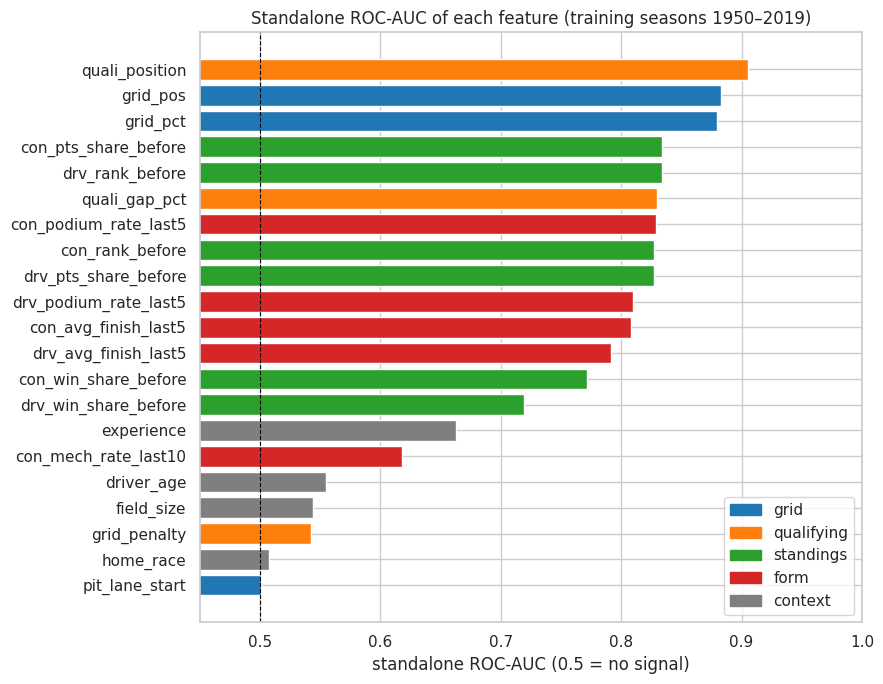

In [36]:
from sklearn.metrics import roc_auc_score
from matplotlib.patches import Patch

train_rows = model_table[model_table["year"].between(TRAIN_START, TRAIN_END)]
ev = []
for grp, cols in CANDIDATE_GROUPS.items():
    for c in cols:
        m = train_rows[c].notna()
        auc = roc_auc_score(train_rows.loc[m, "podium"], train_rows.loc[m, c]) if train_rows.loc[m, c].nunique() > 1 else np.nan
        ev.append({"group": grp, "feature": c, "auc": max(auc, 1 - auc), "direction": "higher → podium" if auc >= 0.5 else "lower → podium",
                   "missing %": round(100 * (1 - m.mean()), 1)})
evidence = pd.DataFrame(ev).sort_values("auc", ascending=False)
display(evidence.round(3))

same = train_rows["quali_position"].notna()
print("On the same rows (training rows with qualifying data):",
      {c: round(1 - roc_auc_score(train_rows.loc[same, "podium"], train_rows.loc[same, c]), 3) for c in ["grid_pos", "quali_position"]})

fig, ax = plt.subplots(figsize=(9, 7))
colors = dict(zip(CANDIDATE_GROUPS, ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:gray"]))
e = evidence.sort_values("auc")
ax.barh(e["feature"], e["auc"], color=e["group"].map(colors))
ax.axvline(0.5, color="black", ls="--", lw=0.8)
ax.set_xlim(0.45, 1); ax.set_xlabel("standalone ROC-AUC (0.5 = no signal)")
ax.set_title(f"Standalone ROC-AUC of each feature (training seasons {TRAIN_START}–{TRAIN_END})")
ax.legend(handles=[Patch(color=c, label=g) for g, c in colors.items()], loc="lower right")
save_fig("11_feature_auc")

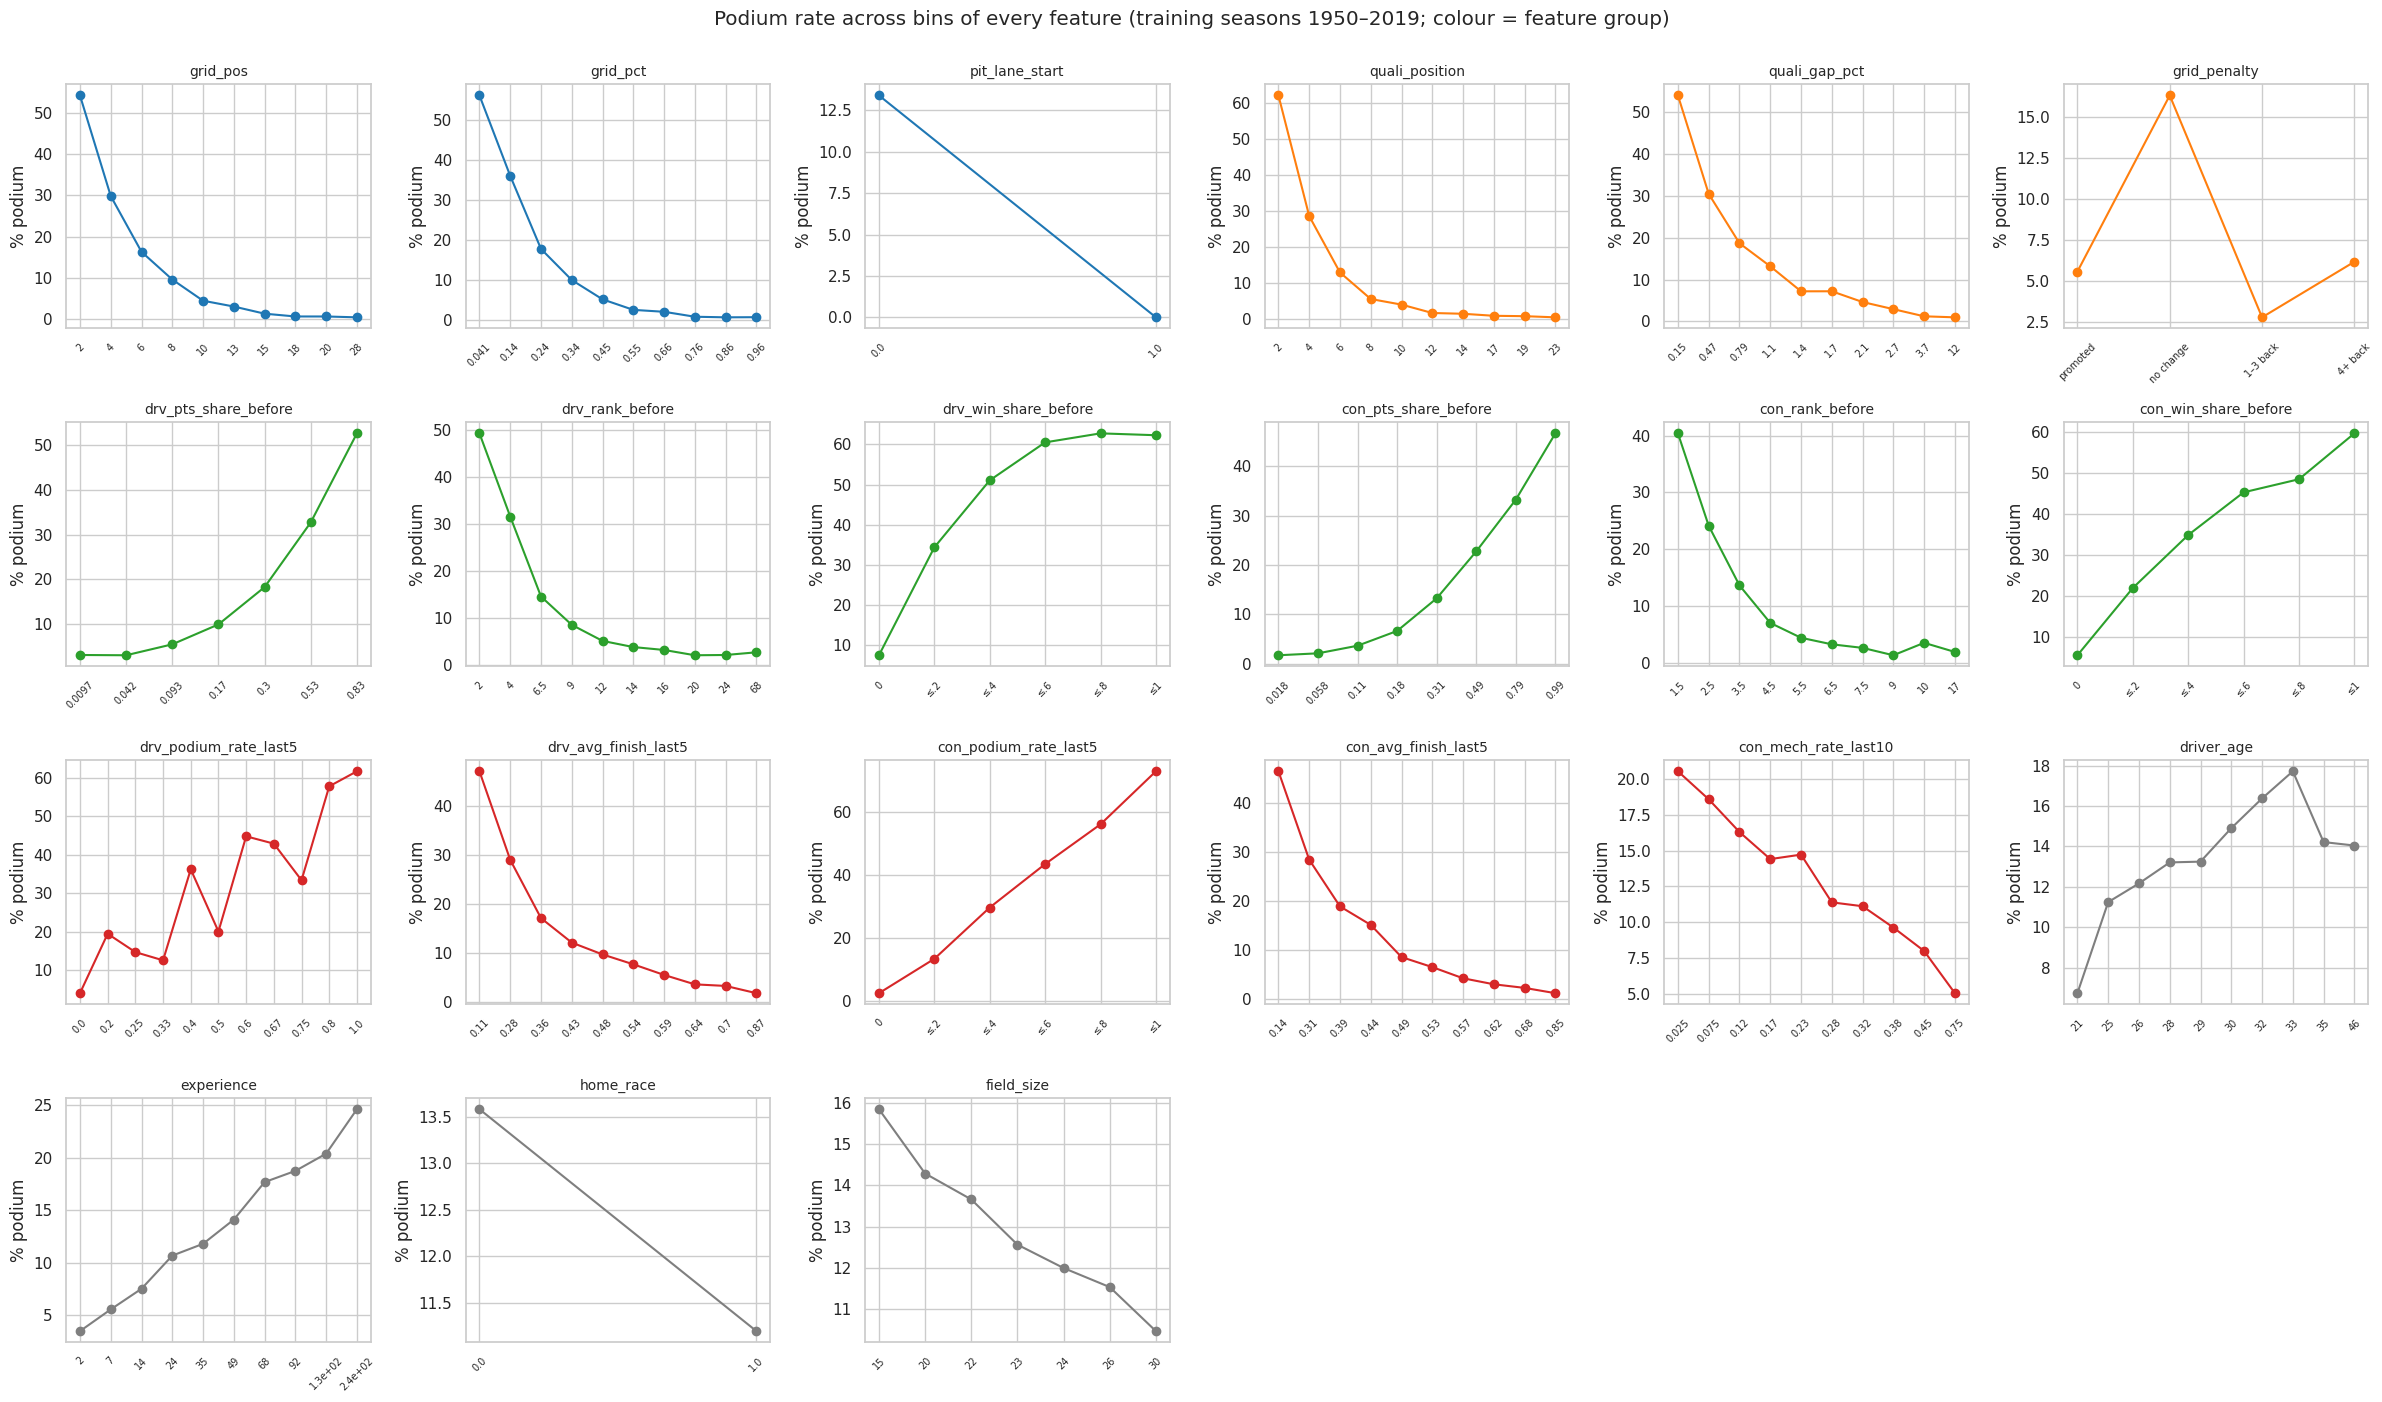

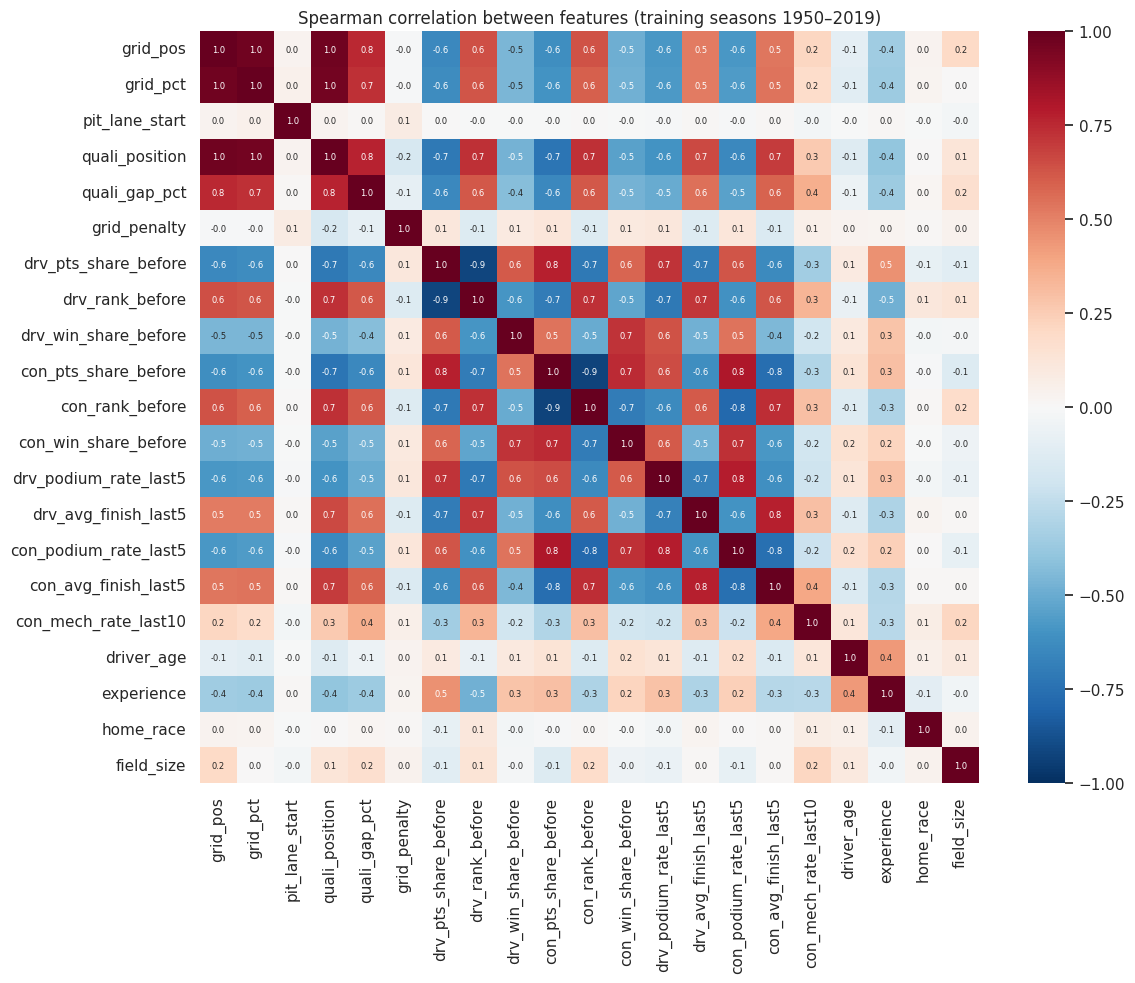

In [37]:
def bin_feature(d, c):
    """Bins that make sense for each kind of feature (flags and small integers stay as they are)."""
    if d[c].nunique() <= 12:
        return d[c].round(2)
    if c == "grid_penalty":
        return pd.cut(d[c], [-99, -1, 0, 3, 99], labels=["promoted", "no change", "1–3 back", "4+ back"])
    if c in ("drv_podium_rate_last5", "con_podium_rate_last5", "drv_win_share_before", "con_win_share_before"):
        return pd.cut(d[c], [-0.01, 0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=["0", "≤.2", "≤.4", "≤.6", "≤.8", "≤1"])
    return pd.qcut(d[c], 10, duplicates="drop")

fig, axes = plt.subplots(4, 6, figsize=(24, 14))
for ax, c in zip(axes.ravel(), CANDIDATES):
    d = train_rows[[c, "podium"]].dropna().copy()
    d["bin"] = bin_feature(d, c)
    rate = d.groupby("bin", observed=True)["podium"].mean() * 100
    labels = [f"{iv.mid:.2g}" if hasattr(iv, "mid") else str(iv) for iv in rate.index]
    ax.plot(range(len(rate)), rate.values, marker="o", color=colors[[g for g, cs in CANDIDATE_GROUPS.items() if c in cs][0]])
    ax.set_xticks(range(len(rate))); ax.set_xticklabels(labels, rotation=45, fontsize=7)
    ax.set_title(c, fontsize=10); ax.set_ylabel("% podium")
for ax in axes.ravel()[len(CANDIDATES):]:
    ax.axis("off")
fig.suptitle(f"Podium rate across bins of every feature (training seasons {TRAIN_START}–{TRAIN_END}; colour = feature group)", y=1.0)
save_fig("12_feature_bins")

corr = train_rows[CANDIDATES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot=True, fmt=".1f", annot_kws={"size": 6})
ax.set_title(f"Spearman correlation between features (training seasons {TRAIN_START}–{TRAIN_END})")
save_fig("13_feature_corr")

**Missing values per season.** The plot below shows, for each feature that has missing values, the share of rows without a value in every season from the start of the training window. It shows where the gaps are inside the training seasons: no qualifying before 1994 and a patchy record until 2002 (Section 2.3), and no constructors' championship before 1958, which is why the model gets "was missing" indicators (D19).

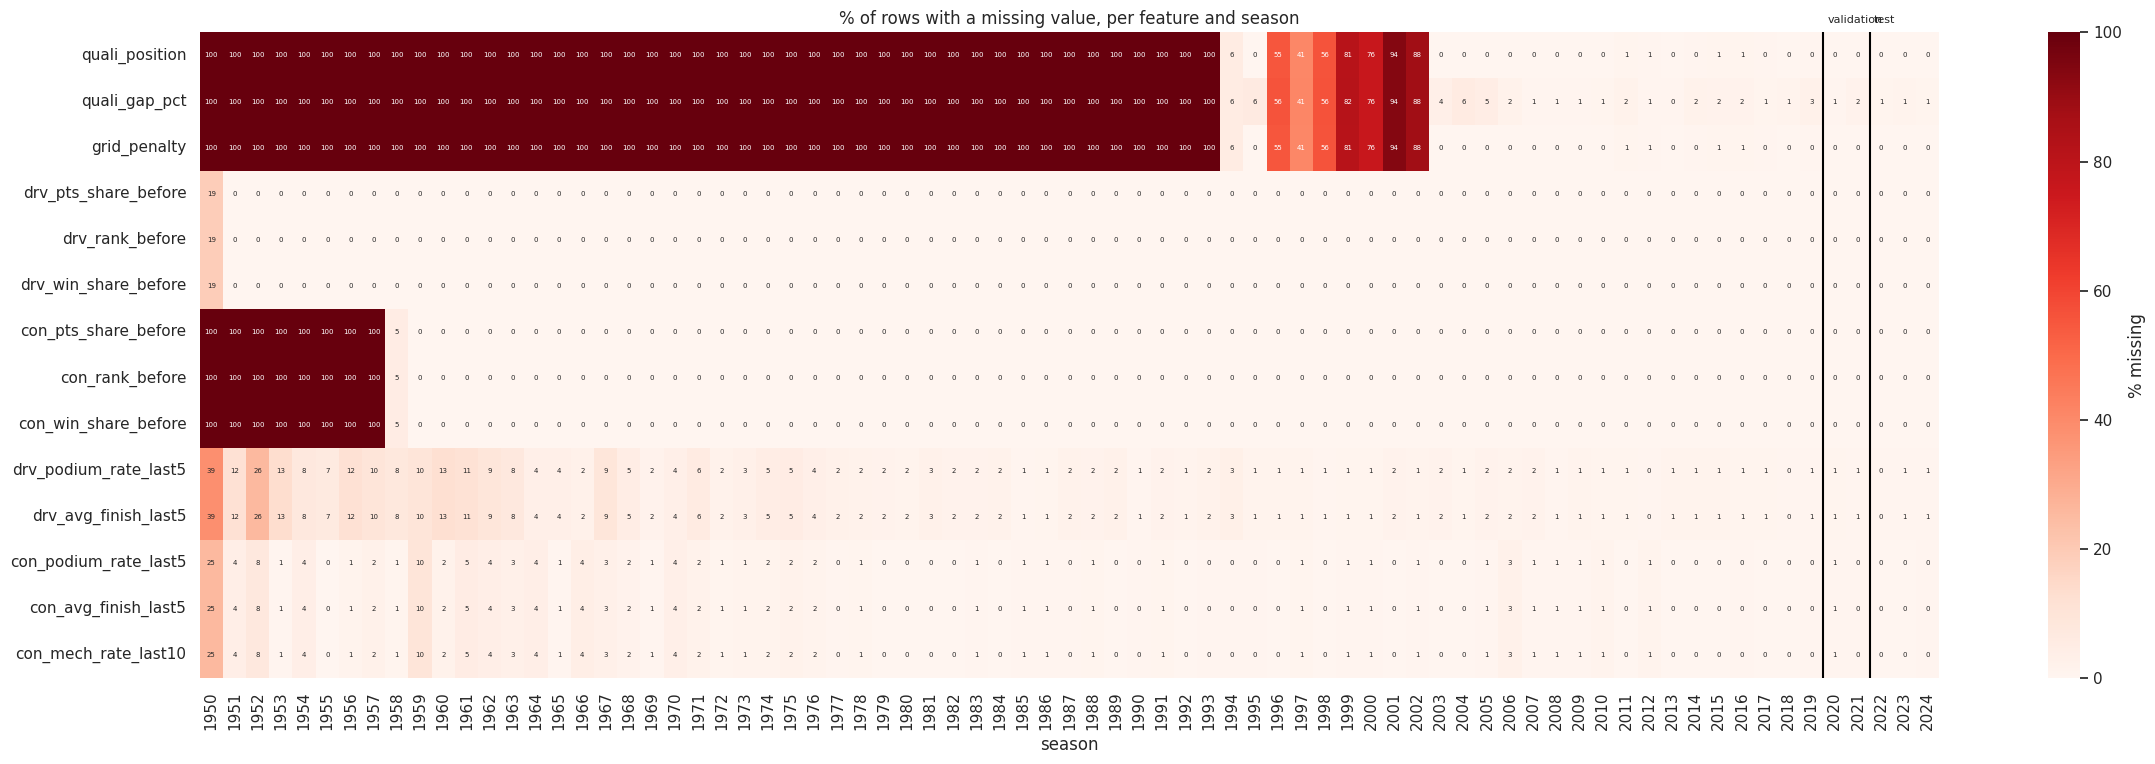

Rows without a qualifying position — 1950–1993: 100.0% | 1994–2002: 53.6% | 2003–2019: 0.3% | 2020–2024: 0.0%


In [38]:
miss = model_table[model_table["year"] >= TRAIN_START].groupby("year")[FEATURES].apply(lambda d: d.isna().mean() * 100)
miss = miss.loc[:, miss.max() > 0]
fig, ax = plt.subplots(figsize=(24, 0.45 * miss.shape[1] + 1.5))
sns.heatmap(miss.T, cmap="Reds", vmin=0, vmax=100, ax=ax, cbar_kws={"label": "% missing"}, annot=miss.T.round(0), fmt=".0f",
            annot_kws={"size": 5})
for x, lab in [(TRAIN_END - TRAIN_START + 1, "validation"), (VAL_END - TRAIN_START + 1, "test")]:
    ax.axvline(x, color="black", lw=1.5); ax.text(x + 0.2, -0.2, lab, fontsize=8)
ax.set_title("% of rows with a missing value, per feature and season"); ax.set_xlabel("season"); ax.set_ylabel("")
save_fig("13b_missing_per_season")
print("Rows without a qualifying position — 1950–1993:", f"{model_table.loc[model_table['year'] < 1994, 'quali_position'].isna().mean():.1%}",
      "| 1994–2002:", f"{model_table.loc[model_table['year'].between(1994, 2002), 'quali_position'].isna().mean():.1%}",
      "| 2003–2019:", f"{model_table.loc[model_table['year'].between(2003, 2019), 'quali_position'].isna().mean():.1%}",
      "| 2020–2024:", f"{model_table.loc[model_table['year'] >= 2020, 'quali_position'].isna().mean():.1%}")

**What this shows.** Inside the training seasons, a qualifying position is missing for every row before 1994 (100.0%), for 53.6% of the rows from 1994–2002 and for 0.3% in 2003–2019; the validation and test seasons have none missing. Over all training rows that is 63% (table in 6.3). The constructor standings are missing before 1958, when there was no constructors' championship (5.2% of training rows, table in 6.7), and form features only on a driver's or team's first race (1.1–3.0%). So the models learn the qualifying features from 1994 on, while the grid position describes the start for every season. The "was missing" indicators added in Section 8 tell the models which rows had no qualifying; they are always 0 in the validation and test seasons.

**What this shows** *(numbers from the outputs above)*

* **Starting position is the strongest single signal.** On all training rows `grid_pos` reaches a standalone AUC of **0.883** and `grid_pct` 0.880. `quali_position` reaches 0.905, but only on the 37% of rows that have qualifying (1994 on), which are easier to rank. **On the same rows grid and qualifying position are practically identical (0.904 vs 0.905)**, and they correlate almost perfectly (heatmap). This is why the seasons without qualifying data can still be used (D17): the grid position carries the same information. We keep both features because they differ exactly in the penalty cases that Q1 showed matter.
* **Most standings and form features are almost as strong (0.79–0.83)**, and they add what grid does not have: how strong the car and driver have been this season and recently.
* **Constructor features are as strong as or stronger than the driver versions** (constructor points share 0.834 vs driver 0.827; constructor podium rate 0.829 vs driver 0.810; constructor average finish 0.808 vs driver 0.791). The one exception is rank, where the driver's (0.834) is above the constructor's (0.827). This supports the hypothesis that the car is the dominant factor.
* `quali_gap_pct` (0.830) is weaker alone than qualifying position: the Q1 gap separates the field well but not the very front, whose order is decided in Q3 — that order is already in `quali_position`. Win shares (0.719 and 0.771) are weaker than points shares because most drivers have zero wins.
* `con_mech_rate_last10` carries a moderate signal (0.618): unreliable teams podium less, as Q3 suggested. `experience` (0.663) helps a little.
* **Weak on their own (≈ 0.50–0.56):** `pit_lane_start` (0.501), `home_race` (0.508), `grid_penalty` (0.543), `field_size` (0.544) and `driver_age` (0.555). `grid_penalty` is not *meant* to work alone: it only matters together with qualifying position (a penalised front-row qualifier, Q1). It stays in the model with `driver_age`, and both are tested after training in a drop-one-feature check (Section 10), instead of us dropping them on a hunch.
* 🔶 **D30 — no signal, no model input.** `pit_lane_start`, `home_race` and `field_size` show practically no signal, and their information is either already elsewhere or absent: a pit-lane start is the last grid slot in `grid_pos`, the field size is inside `grid_pct`, and Q2 found no home advantage. They are therefore **not model inputs: the models use 18 features**. Section 10 adds each of them back to every model to check that leaving them out costs nothing.
* Several features overlap strongly (grid ↔ qualifying position; rank ↔ points share; driver ↔ constructor form). That is expected: they describe the same underlying strength from different angles. It means removing any single group in the ablation will cost little, because other groups can partly substitute for it.

## 7. Train / validation / test split

🔶 **Decision D18 — split by season, not by random rows.**

| split | seasons | used for |
|---|---|---|
| train | 1950–2019 (window: D17) | fitting models and preprocessing |
| validation | 2020–2021 | early stopping, hyperparameters, threshold, model selection |
| test | 2022–2024 | reported **once** at the end, never used for any choice |

Why not a random split? (1) Rows from the same race would land in both train and test, so the model would be graded on a race it partly saw. (2) Rows from 2023 would be in training while we test on 2022, which is information from the future. (3) In real use you always predict the *next* race from past races. The time split copies that.

It also makes the test meaningful: 2022 introduced new technical rules (ground-effect cars), so the test checks whether the model still works after a rule change.

Two caveats. **2020 was an unusual season** (17 races because of COVID, several circuits used twice). And because validation is used for several choices (early stopping, hyperparameters, threshold, model selection), **validation scores are slightly optimistic**; the test score is the only unbiased estimate. Model weights are fitted on 1950–2019 and frozen: the 2022–2024 test uses the same model and threshold that were chosen on 2020–2021, exactly as a model deployed at the end of 2021 would have been used.

In [40]:
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, roc_curve, brier_score_loss, log_loss)

# DECISION D18 → see DECISIONS.md  (season-based split; training window from D17)
# Every row is assigned to a split only by its season, so a race never ends up in two splits.
def split_of(year):
    return np.select([year < TRAIN_START, year <= TRAIN_END, year <= VAL_END], ["before window", "train", "validation"], "test")
model_table["split"] = split_of(model_table["year"])

split_summary = model_table.groupby("split").agg(seasons=("year", lambda s: f"{s.min()}–{s.max()}"), races=("raceId", "nunique"),
                                                  rows=("podium", "size"), podium_rate=("podium", "mean"))
display(split_summary.reindex([s for s in ["before window", "train", "validation", "test"] if s in split_summary.index]).round(3))
assert model_table.groupby("raceId")["split"].nunique().max() == 1   # no race in two splits

train = model_table[model_table["split"] == "train"]
val = model_table[model_table["split"] == "validation"]
test = model_table[model_table["split"] == "test"]
X_train, y_train = train[FEATURES], train["podium"]
X_val, y_val = val[FEATURES], val["podium"]
X_test, y_test = test[FEATURES], test["podium"]

,seasons,races,rows,podium_rate
split,,,,
train,1950–2019,1007,22576,0.134
validation,2020–2021,39,780,0.150
test,2022–2024,68,1359,0.150


**What this shows.** The models learn from 22,576 rows (1,007 races, 1950–2019). Validation has 39 races (780 rows) and test 68 races (1,359 rows), each with a podium base rate of 15.0% (13.4% in training). That base rate is the **PR-AUC of a random model** on these splits, so every PR-AUC we report should be read against it.

### 7.1 Metrics and uncertainty

> 💬 **In plain words.** The model gives every driver a podium probability. **Precision**: of the drivers we said would podium, how many did. **Recall**: of the drivers who did podium, how many we caught. **F1** balances the two. These three need a **threshold** ("say podium above 0.241", the baseline's threshold). **ROC-AUC** and **PR-AUC** need no threshold: they check how well the probabilities rank the real podium finishers above everyone else, and PR-AUC focuses on the top of that ranking, which is what matters when only ~15% of drivers podium.

🔶 **Decision D21 — metrics.** We report the five metrics of the brief: **ROC-AUC, PR-AUC, F1, precision and recall**, plus two calibration checks (**Brier score** and **log-loss**) because the inference function returns a probability. The model tables in 9.4 show the Brier score; log-loss is computed for every model and saved in `model_comparison.csv` in the output folder, and the experiment tables in Section 8 show it. **Accuracy is not used:** a model that always says "no podium" has accuracy 0.850 on validation and test (1 − the base rate of 0.150) and recall 0, so accuracy would reward ignoring podiums.
* **Primary: PR-AUC.** Podiums are rare (~15%) and PR-AUC scores how clean the *top* of the ranking is, which is the hard part of this task. A useless model still gets ROC-AUC 0.5 but PR-AUC only ≈ 0.15, so PR-AUC exposes weak models more clearly.
* **Secondary: ROC-AUC** for overall separation of podium vs non-podium.
* **F1, precision, recall** describe the yes/no decisions at one threshold.

🔶 **Decision D22 — threshold.** For every model, the threshold is the one that maximises **F1 on the validation set**. The same threshold is then applied to train and test. The test set is never used to choose it.

🔶 **Decision D23 — uncertainty.** Validation has only 39 races, so a difference of 0.01 in PR-AUC can be luck. Every important comparison gets a **95% bootstrap interval over races**: we redraw the races of the split with replacement 1,000 times and recompute the metric (or the difference between two models on the same redrawn races). A difference whose interval includes 0 is treated as "no evidence of a difference".

In [42]:
# DECISION D21 → see DECISIONS.md  (PR-AUC primary, ROC-AUC secondary, F1/precision/recall at the threshold, calibration)
def metrics(y, p, thr):
    """All metrics. AUCs use the probabilities (the ranking); F1/precision/recall use the threshold; Brier/log-loss check calibration."""
    yhat = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "F1": f1_score(y, yhat),
            "precision": precision_score(y, yhat, zero_division=0), "recall": recall_score(y, yhat),
            "Brier": brier_score_loss(y, p), "log-loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6))}

def best_f1_threshold(y, p):
    """DECISION D22 → threshold that maximises F1 on the data given (we only ever pass validation data).
    precision_recall_curve returns one more precision/recall value than thresholds, hence f1[:-1]."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.nanargmax(f1[:-1])])

def race_top3_hit_rate(frame, p):
    """Domain check: in each race take the 3 highest scores; share of actual podium finishers we caught."""
    t = frame[["raceId", "podium"]].assign(p=p)
    t["r"] = t.groupby("raceId")["p"].rank(ascending=False, method="first")
    return float(t.loc[t["r"] <= 3, "podium"].sum() / t["podium"].sum())

# DECISION D23 → see DECISIONS.md  (race-level bootstrap intervals)
def race_bootstrap(frame, preds, n_boot=1000, seed=SEED):
    """PR-AUC of each prediction vector on 1,000 resamples of the races in `frame` (same resamples for every model).
    preds: dict name -> probabilities aligned with frame. Returns a DataFrame n_boot × models."""
    rng = np.random.default_rng(seed)
    race_ids = frame["raceId"].to_numpy()
    groups = pd.Series(np.arange(len(frame))).groupby(race_ids).apply(np.array)
    y = frame["podium"].to_numpy()
    out = []
    for _ in range(n_boot):
        idx = np.concatenate(groups.sample(len(groups), replace=True, random_state=int(rng.integers(1e9))).to_numpy())
        out.append({k: average_precision_score(y[idx], np.asarray(p)[idx]) for k, p in preds.items()})
    return pd.DataFrame(out)

def ci(series):
    lo, hi = np.percentile(series, [2.5, 97.5])
    return f"{lo:+.3f} to {hi:+.3f}" if (series < 0).any() else f"{lo:.3f}–{hi:.3f}"

## 8. Preprocessing and preprocessing experiments

🔶 **Decision D19 — preprocessing.**
* **Imputation: median + missing indicators.** Missing values in our table are structural (no qualifying recorded before 1994 and patchy until 2002, no constructors' championship before 1958, no history yet for a debutant). The median is robust to skewed features, and the indicator columns (`missingindicator_*`) let the model learn that "missing" itself carries information instead of pretending the value was average. The 18 model features become **32 columns**: 14 of them have missing values in training and each gets an indicator.
* **Scaling: `StandardScaler` for logistic regression and the neural network** (both are trained by gradient steps and their penalties depend on feature scale). Tree models split on thresholds and do not need scaling, so they only get the imputer.
* Every preprocessing step is **fitted on the training set only** (`fit_transform`) and then applied unchanged to validation and test (`transform`).

The next cell builds **three versions of the data**, once, and every model in Section 9 uses the version it needs:

| version | what it is | used by |
|---|---|---|
| `X_train`, `X_val`, `X_test` | the cleaned feature table from Section 7 (may contain missing values) | nothing directly: input of the two steps below |
| `X_train_imp`, `X_val_imp`, `X_test_imp` | missing values filled + missing-indicator columns | random forest, gradient boosting (trees do not need scaling) |
| `X_train_scaled`, `X_val_scaled`, `X_test_scaled` | imputed **and** scaled | logistic regression, neural network |

18 features -> 32 columns after imputation; the added missing-value indicators are:
['missingindicator_quali_position', 'missingindicator_quali_gap_pct', 'missingindicator_grid_penalty', 'missingindicator_drv_pts_share_before', 'missingindicator_drv_rank_before', 'missingindicator_drv_win_share_before', 'missingindicator_con_pts_share_before', 'missingindicator_con_rank_before', 'missingindicator_con_win_share_before', 'missingindicator_drv_podium_rate_last5', 'missingindicator_drv_avg_finish_last5', 'missingindicator_con_podium_rate_last5', 'missingindicator_con_avg_finish_last5', 'missingindicator_con_mech_rate_last10']
Shapes: train (22576, 32), validation (780, 32), test (1359, 32)


,missing % (raw),raw min,raw max,median used to fill,min after scaling,max after scaling
grid_pos,0.00,1.00,34.00,12.00,-1.60,3.24
grid_pct,0.00,0.00,1.00,0.50,-1.66,1.66
quali_position,63.02,1.00,26.00,11.00,-2.62,3.84
quali_gap_pct,63.65,0.00,19.67,1.50,-1.46,15.57
grid_penalty,63.02,-9.00,23.00,0.00,-10.50,26.83
drv_pts_share_before,0.10,0.00,1.00,0.06,-0.70,2.81
drv_rank_before,0.10,1.00,109.00,13.00,-1.11,7.55
drv_win_share_before,0.10,0.00,1.00,0.00,-0.33,7.40
con_pts_share_before,5.23,0.00,1.00,0.13,-0.86,2.18
con_rank_before,5.23,1.00,23.00,6.00,-1.42,4.50


After scaling every column has mean 0 and standard deviation 1 (largest deviation: mean 3.0e-16, std 8.2e-13).


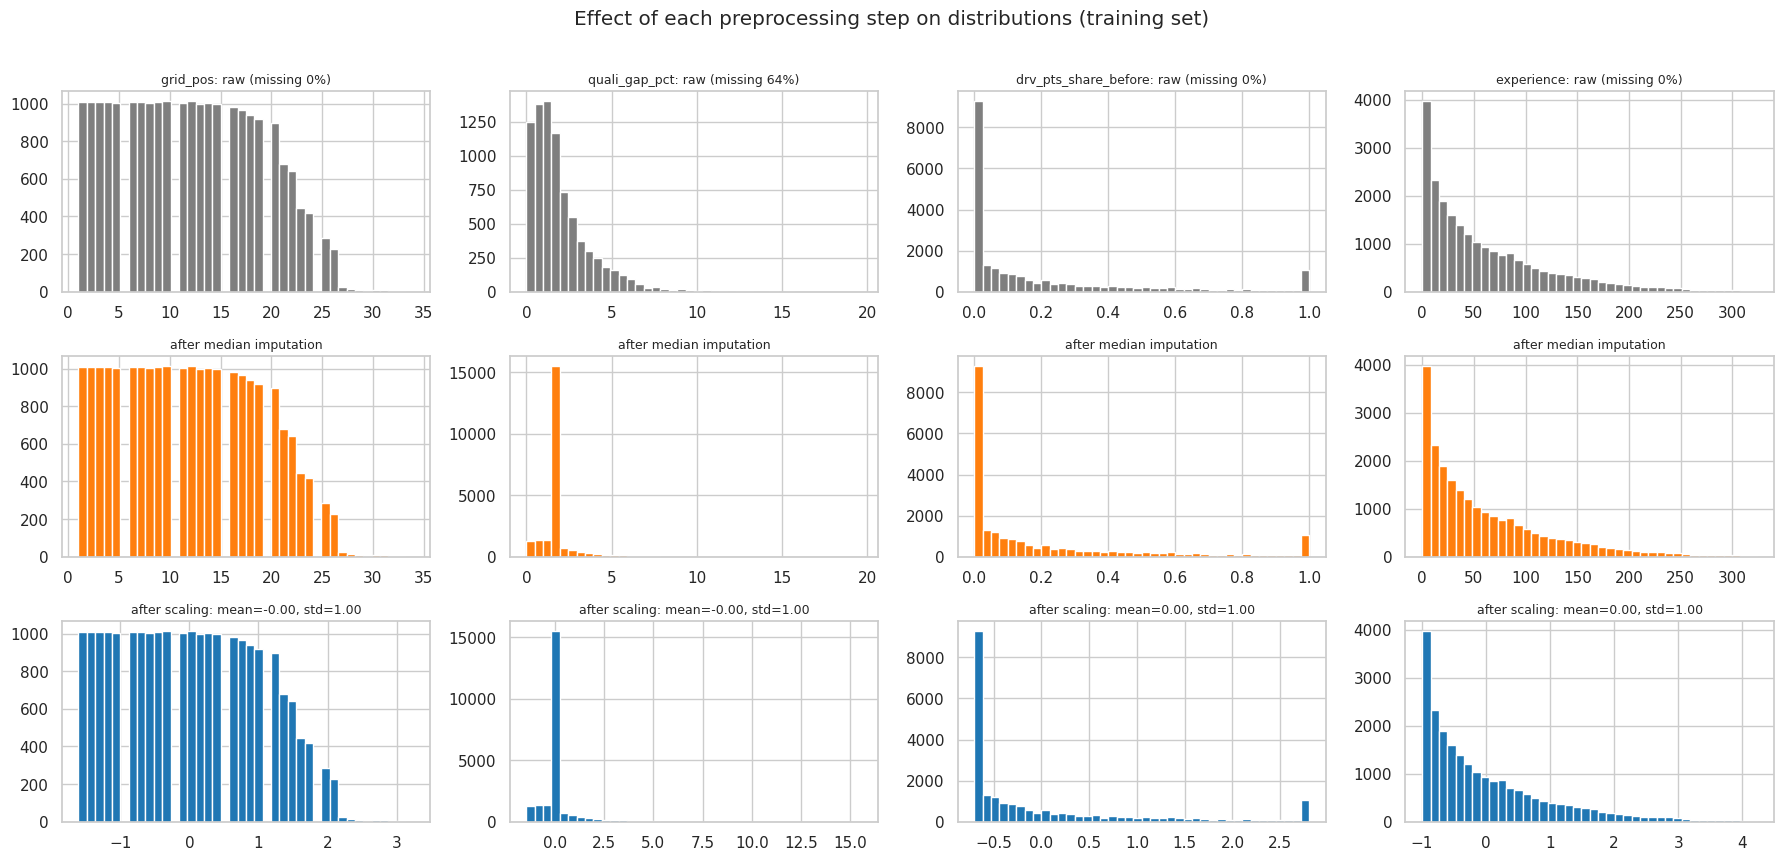

In [43]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

# DECISION D19 → see DECISIONS.md  (median imputation + missing indicators, then scaling; fitted on the training set only)
# X_train / X_val / X_test come from Section 7. Some values are missing (NaN): no qualifying before 1994 and patchy
# until 2002, no constructor standings before 1958, no form history yet for a debutant. scikit-learn's models cannot be trained on NaN, so they are filled first.

# Step 1: imputation. Learn each feature's median on the TRAINING rows, fill NaN with it,
#         and add a 0/1 "was missing" column for every feature that has missing values.
imputer = SimpleImputer(strategy="median", add_indicator=True)
X_train_imp = imputer.fit_transform(X_train)      # learn the medians on train, fill train
X_val_imp = imputer.transform(X_val)               # fill validation with the TRAINING medians
X_test_imp = imputer.transform(X_test)             # fill test with the TRAINING medians

# Step 2: scaling. Learn each column's mean and standard deviation on the TRAINING rows,
#         then replace every value by (value - mean) / std.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)
X_test_scaled = scaler.transform(X_test_imp)

PREP_COLUMNS = list(imputer.get_feature_names_out())
print(f"{len(FEATURES)} features -> {len(PREP_COLUMNS)} columns after imputation; the added missing-value indicators are:")
print([c for c in PREP_COLUMNS if c.startswith("missingindicator")])
print(f"Shapes: train {X_train_scaled.shape}, validation {X_val_scaled.shape}, test {X_test_scaled.shape}")

# Effect of each step, per feature (training set)
Xt_imp = pd.DataFrame(X_train_imp, columns=PREP_COLUMNS, index=X_train.index)
Xt_train = pd.DataFrame(X_train_scaled, columns=PREP_COLUMNS, index=X_train.index)
assert Xt_imp.isna().sum().sum() == 0                              # imputation leaves no missing value
effect = pd.DataFrame({
    "missing % (raw)": X_train.isna().mean() * 100, "raw min": X_train.min(), "raw max": X_train.max(),
    "median used to fill": imputer.statistics_,
    "min after scaling": Xt_train[FEATURES].min(), "max after scaling": Xt_train[FEATURES].max()})
display(effect.round(2))
print(f"After scaling every column has mean 0 and standard deviation 1 (largest deviation: mean {Xt_train.mean().abs().max():.1e}, "
      f"std {(Xt_train.std(ddof=0) - 1).abs().max():.1e}).")

cols_show = ["grid_pos", "quali_gap_pct", "drv_pts_share_before", "experience"]
fig, axes = plt.subplots(3, len(cols_show), figsize=(18, 8.5))
for i, c in enumerate(cols_show):
    axes[0, i].hist(X_train[c].dropna(), bins=40, color="tab:gray")
    axes[0, i].set_title(f"{c}: raw (missing {X_train[c].isna().mean():.0%})", fontsize=9)
    axes[1, i].hist(Xt_imp[c], bins=40, color="tab:orange")
    axes[1, i].set_title("after median imputation", fontsize=9)
    axes[2, i].hist(Xt_train[c], bins=40, color="tab:blue")
    axes[2, i].set_title(f"after scaling: mean={Xt_train[c].mean():.2f}, std={Xt_train[c].std():.2f}", fontsize=9)
fig.suptitle("Effect of each preprocessing step on distributions (training set)", y=1.01)
save_fig("15_preprocessing_effect")

**What this shows.** Imputation removes every missing value; the table lists the training median used to fill each feature. For a feature with many missing values, such as `quali_gap_pct`, it creates a tall spike at the median (second row of the plot). That is why the missing-indicator columns are added: they tell the model which values in the spike were really missing. Scaling then centres every feature at 0 with standard deviation 1, so no feature dominates a linear model just because of its units (`experience` runs up to 300+, `grid_pct` stays between 0 and 1). Scaling does not change the shape of a distribution, only its position and spread.

**Preprocessing-order experiments.** We run three experiments on the order of the preprocessing steps (the brief asks for at least two). Each one changes only the order of two steps and keeps the model, the rows and the threshold rule identical. Scores are on validation; test is shown for reference only.

**How to read them.** These choices are decided by **correctness, not by score**. A wrong order can score the same as the correct one, or even higher, precisely because it uses information it should not have (future seasons, or values we made up). The scores show how large the effect is on this data and whether doing it correctly costs anything; the reason for each choice is given in its text.

### 8.1 Experiment E1 — split first, then fit preprocessing *vs* fit preprocessing first, then split

The imputer and the scaler learn statistics from the rows they are fitted on (medians, means, standard deviations). If they are fitted on **all** rows before splitting, those statistics already contain the validation and test seasons: information from 2020–2024 that a model trained at the end of 2019 could not have had. This is a subtle form of leakage. No labels leak, but the inputs are shaped by the future.


In [44]:
# Correct order: imputer and scaler fitted on the training rows only. These are X_*_scaled from the cell above.
# Leaky order: imputer and scaler fitted on train + validation + test together, before splitting.
X_all = pd.concat([X_train, X_val, X_test])
imputer_leaky = SimpleImputer(strategy="median", add_indicator=True).fit(X_all)
scaler_leaky = StandardScaler().fit(imputer_leaky.transform(X_all))
X_train_leaky = scaler_leaky.transform(imputer_leaky.transform(X_train))
X_val_leaky = scaler_leaky.transform(imputer_leaky.transform(X_val))
X_test_leaky = scaler_leaky.transform(imputer_leaky.transform(X_test))

versions = {"split → fit on train (correct)": (X_train_scaled, X_val_scaled, X_test_scaled),
            "fit on all data → split (leaky)": (X_train_leaky, X_val_leaky, X_test_leaky)}
e1 = []
for label, (A_train, A_val, A_test) in versions.items():
    model = LogisticRegression(max_iter=3000)
    model.fit(A_train, y_train)                      # the model itself is always trained on the training rows only
    p_val = model.predict_proba(A_val)[:, 1]
    p_test = model.predict_proba(A_test)[:, 1]
    thr = best_f1_threshold(y_val, p_val)            # threshold chosen on validation only (D22)
    e1.append({"order": label, "split": "validation", **metrics(y_val, p_val, thr)})
    e1.append({"order": label, "split": "test", **metrics(y_test, p_test, thr)})
display(pd.DataFrame(e1).round(4))

# Which statistics actually change when the future seasons are allowed in? (the size of the leak)
med_train = SimpleImputer(strategy="median").fit(X_train)
med_all = SimpleImputer(strategy="median").fit(X_all)
shift = pd.DataFrame({"median (train only)": med_train.statistics_, "median (all data)": med_all.statistics_,
                      "mean (train only)": X_train.mean().values, "mean (all data)": X_all.mean().values}, index=FEATURES)
display(shift[(shift.iloc[:, 0] != shift.iloc[:, 1]) | ((shift.iloc[:, 2] - shift.iloc[:, 3]).abs() > 0.01 * shift.iloc[:, 2].abs())].round(3))

,order,split,ROC-AUC,PR-AUC,F1,precision,recall,Brier,log-loss
0,split → fit on train (correct),validation,0.9324,0.7226,0.6985,0.6129,0.8120,0.0674,0.2245
1,split → fit on train (correct),test,0.9374,0.7219,0.6729,0.5457,0.8775,0.0684,0.2212
2,fit on all data → split (leaky),validation,0.9326,0.7230,0.6989,0.6184,0.8034,0.0674,0.2245
3,fit on all data → split (leaky),test,0.9374,0.7219,0.6729,0.5457,0.8775,0.0685,0.2213


,median (train only),median (all data),mean (train only),mean (all data)
grid_pos,12.000,12.000,11.919,11.796
quali_position,11.000,11.000,11.364,11.186
quali_gap_pct,1.500,1.343,2.004,1.832
grid_penalty,0.000,0.000,0.000,0.001
drv_pts_share_before,0.064,0.068,0.201,0.205
drv_rank_before,13.000,12.000,14.797,14.445
drv_win_share_before,0.000,0.000,0.043,0.043
con_pts_share_before,0.134,0.137,0.290,0.292
con_rank_before,6.000,6.000,6.288,6.219
drv_avg_finish_last5,0.510,0.512,0.495,0.496


**What this shows** *(numbers from the output above)*. With 22,576 training rows the medians and scales barely move, so the scores are practically identical (validation PR-AUC 0.7226 vs 0.7230). The second table shows that several statistics *do* change when the future seasons are included, for example the median of `quali_gap_pct` (1.500 → 1.343) and of `experience` (41 → 45). So the leaky version uses information from after 2019, and its test score cannot judge it fairly, because the test rows helped build its preprocessing. The correct order costs nothing, so we keep it: **split first, then fit preprocessing on the training set only** (D19). With fewer rows, or with an encoding that uses the target, the same mistake could inflate scores substantially.

### 8.2 Experiment E2 — impute then scale *vs* scale then impute (logistic regression and neural network)

> 💬 **In plain words.** Both orders are allowed; the question is only which comes first. Filling missing values first adds many identical median values, which makes the column look less spread out, so scaling then stretches the real values further. For both the logistic regression and the network the two orders score practically the same, so we keep the standard order (fill, then scale).

Both orders are leak-free as long as each step is fitted on the training rows only. They differ in which values the scaler learns from:
* **Impute → scale (our choice, and the usual order).** Missing values are first filled with the training median; the scaler then computes the mean and standard deviation over all rows, the filled ones included. The matrix the model sees has exactly mean 0 and standard deviation 1.
* **Scale → impute.** scikit-learn's `StandardScaler` ignores missing values when it computes the mean and standard deviation, and leaves them as missing in its output. The imputer then fills them with the median of the *scaled* column, which is the same median expressed in scaled units. Here the scaling statistics come from real values only.

The difference is largest for a feature with many missing values: imputing first adds many identical median values, which shrinks the standard deviation. Scaling matters most for the neural network, so we run the comparison for both model types; the network is the one used in Section 9 (two hidden layers, 32 → 16).


I0000 00:00:1794252396.040636      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794252416.611678      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


,model,order,split,ROC-AUC,PR-AUC,F1,precision,recall,Brier,log-loss
0,logistic regression,impute → scale (our choice),validation,0.9324,0.7226,0.6985,0.6129,0.8120,0.0674,0.2245
1,logistic regression,impute → scale (our choice),test,0.9374,0.7219,0.6729,0.5457,0.8775,0.0684,0.2212
2,shallow NN (32-16),impute → scale (our choice),validation,0.9290,0.7158,0.7027,0.6408,0.7778,0.0685,0.2274
3,shallow NN (32-16),impute → scale (our choice),test,0.9368,0.7112,0.6667,0.5694,0.8039,0.0701,0.2205
4,logistic regression,scale → impute,validation,0.9319,0.7214,0.7011,0.6169,0.8120,0.0675,0.2250
5,logistic regression,scale → impute,test,0.9375,0.7223,0.6754,0.5471,0.8824,0.0684,0.2212
6,shallow NN (32-16),scale → impute,validation,0.9286,0.7220,0.6967,0.6693,0.7265,0.0681,0.2268
7,shallow NN (32-16),scale → impute,test,0.9354,0.7045,0.6785,0.6194,0.7500,0.0701,0.2212


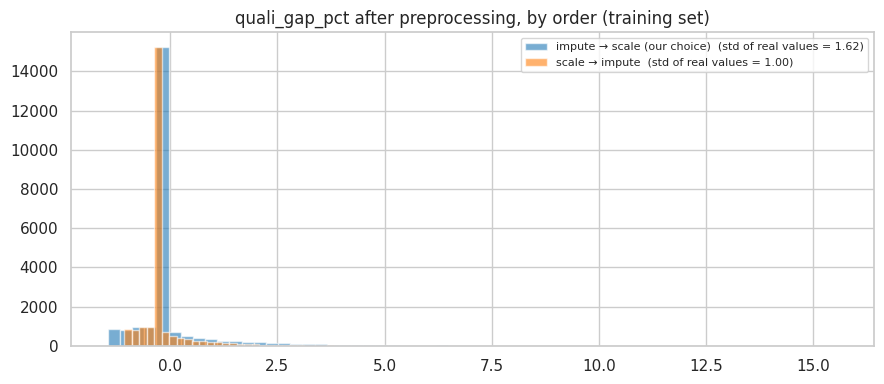

In [45]:
import tensorflow as tf
from tensorflow import keras
keras.utils.set_random_seed(SEED)

# DECISION D25 → see DECISIONS.md  (the shallow network of Section 9.3; defined here because E2 already uses it)
def build_nn(n_inputs, hidden=(32, 16), dropout=0.2, seed=SEED):
    """Input -> Dense ReLU layers (with dropout and a small L2 penalty) -> 1 sigmoid unit = podium probability."""
    keras.utils.set_random_seed(seed)                # same random start every run
    layers = [keras.Input(shape=(n_inputs,))]
    for units in hidden:
        layers += [keras.layers.Dense(units, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
                   keras.layers.Dropout(dropout)]
    net = keras.Sequential(layers + [keras.layers.Dense(1, activation="sigmoid")])
    net.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy",
                metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
    return net

def fit_nn(net, A_train, A_val):
    """Train on the training rows; stop when validation PR-AUC stops improving and keep the best epoch's weights."""
    early_stop = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=15, restore_best_weights=True)
    return net.fit(A_train, np.asarray(y_train), validation_data=(A_val, np.asarray(y_val)), epochs=200, batch_size=128,
                   callbacks=[early_stop], verbose=0)

# Order A (our choice), impute -> scale: X_*_scaled from the start of this section.
# Order B, scale -> impute: StandardScaler skips NaN when it learns mean and std, and keeps NaN in its output;
#          the imputer then fills them with the median of the scaled column.
scaler_b = StandardScaler()
imputer_b = SimpleImputer(strategy="median", add_indicator=True)
X_train_b = imputer_b.fit_transform(scaler_b.fit_transform(X_train))
X_val_b = imputer_b.transform(scaler_b.transform(X_val))
X_test_b = imputer_b.transform(scaler_b.transform(X_test))

versions = {"impute → scale (our choice)": (X_train_scaled, X_val_scaled, X_test_scaled),
            "scale → impute": (X_train_b, X_val_b, X_test_b)}
e2, dists = [], {}
for label, (A_train, A_val, A_test) in versions.items():
    # logistic regression
    model = LogisticRegression(max_iter=3000)
    model.fit(A_train, y_train)
    p_val, p_test = model.predict_proba(A_val)[:, 1], model.predict_proba(A_test)[:, 1]
    thr = best_f1_threshold(y_val, p_val)
    e2.append({"model": "logistic regression", "order": label, "split": "validation", **metrics(y_val, p_val, thr)})
    e2.append({"model": "logistic regression", "order": label, "split": "test", **metrics(y_test, p_test, thr)})
    # neural network (same architecture as Section 9.3)
    net = build_nn(A_train.shape[1])
    fit_nn(net, A_train, A_val)
    p_val, p_test = net.predict(A_val, verbose=0).ravel(), net.predict(A_test, verbose=0).ravel()
    thr = best_f1_threshold(y_val, p_val)
    e2.append({"model": "shallow NN (32-16)", "order": label, "split": "validation", **metrics(y_val, p_val, thr)})
    e2.append({"model": "shallow NN (32-16)", "order": label, "split": "test", **metrics(y_test, p_test, thr)})
    dists[label] = A_train[:, FEATURES.index("quali_gap_pct")]
display(pd.DataFrame(e2).round(4))

fig, ax = plt.subplots(figsize=(9, 4))
real = X_train["quali_gap_pct"].notna().values
for (label, v), col in zip(dists.items(), ["tab:blue", "tab:orange"]):
    ax.hist(v, bins=60, alpha=0.6, label=f"{label}  (std of real values = {np.std(v[real]):.2f})", color=col)
ax.set_title("quali_gap_pct after preprocessing, by order (training set)"); ax.legend(fontsize=8)
save_fig("16_impute_scale_order")

**What this shows** *(numbers from the output above)*. The order visibly changes the distribution of a feature with many missing values (`quali_gap_pct` is missing for 64% of the training rows: every season before 1994 and many rows of 1994–2002): imputing first squeezes the standard deviation, so after scaling the real values are stretched further from 0 (compare the two standard deviations in the legend). On the scores the effect is negligible for the logistic regression (validation PR-AUC 0.7226 vs 0.7214). For the network scale → impute is a little higher on validation (0.7227 vs 0.7158), but on test the order reverses (0.7034 vs 0.7112, for reference only), and the gap is of the same size as the network's own seed spread in 9.3 (validation 0.7158 to 0.7207). So neither order is shown to be better. We keep **impute → scale**: it is the standard order, the scaler never has to deal with missing values, and the matrix the model is trained on has exactly mean 0 and standard deviation 1.

### 8.3 Experiment E3 — derive features, then impute *vs* impute, then derive features

`grid_penalty = grid_pos − quali_position`: how many places a driver moved between qualifying and the start (positive = moved back, for example after a gearbox penalty). It is **derived** from `quali_position`, which is missing whenever no qualifying session was recorded (14,228 training rows, printed below). The question is which step comes first:
* **Derive → impute (our choice).** Without a qualifying position there is no penalty to compute, so `grid_penalty` stays **missing** in the feature table. The imputer then fills it with the training median of `grid_penalty`, which is **0** ("no change between qualifying and grid", see the table at the start of this section), and sets the indicator column `missingindicator_grid_penalty = 1`, so the model knows that this 0 was not observed.
* **Impute → derive.** The missing `quali_position` is first filled with its training median (11), and the penalty is then computed from that made-up value: `grid_penalty = grid_pos − 11`. A driver who started 22nd gets an invented penalty of +11, one who started 3rd gets −8, and nothing tells the model that these values are invented.


In [47]:
# Our order (derive -> impute): grid_penalty was computed in Section 6 from the real quali_position, so it is NaN
# wherever quali_position is NaN; the imputer of this section fills it later (median 0 + "was missing" flag).
# Wrong order (impute -> derive): fill quali_position with its training median FIRST, then recompute grid_penalty from it.
quali_median = X_train["quali_position"].median()
def impute_then_derive(X):
    X = X.copy()
    X["quali_position"] = X["quali_position"].fillna(quali_median)
    X["grid_penalty"] = X["grid_pos"] - X["quali_position"]
    return X
X_train_w, X_val_w, X_test_w = impute_then_derive(X_train), impute_then_derive(X_val), impute_then_derive(X_test)
no_quali = X_train["quali_position"].isna()
print("derive → impute (our choice): training rows whose grid_penalty value is made up =", int((X_train["grid_penalty"].notna() & no_quali).sum()))
print("impute → derive: training rows whose grid_penalty value is made up =", int((X_train_w["grid_penalty"].notna() & no_quali).sum()))

# The wrong-order table then goes through the same imputer + scaler steps (fitted on its own training rows).
imputer_w = SimpleImputer(strategy="median", add_indicator=True)
scaler_w = StandardScaler()
A_train_w = scaler_w.fit_transform(imputer_w.fit_transform(X_train_w))
A_val_w = scaler_w.transform(imputer_w.transform(X_val_w))
A_test_w = scaler_w.transform(imputer_w.transform(X_test_w))

versions = {"derive → impute (our choice)": (X_train_scaled, X_val_scaled, X_test_scaled),
            "impute → derive": (A_train_w, A_val_w, A_test_w)}
e3 = []
for label, (A_train, A_val, A_test) in versions.items():
    model = LogisticRegression(max_iter=3000)
    model.fit(A_train, y_train)
    p_val, p_test = model.predict_proba(A_val)[:, 1], model.predict_proba(A_test)[:, 1]
    thr = best_f1_threshold(y_val, p_val)
    e3.append({"order": label, "split": "validation", **metrics(y_val, p_val, thr)})
    e3.append({"order": label, "split": "test", **metrics(y_test, p_test, thr)})
display(pd.DataFrame(e3).round(4))

derive → impute (our choice): training rows whose grid_penalty value is made up = 0
impute → derive: training rows whose grid_penalty value is made up = 14228


,order,split,ROC-AUC,PR-AUC,F1,precision,recall,Brier,log-loss
0,derive → impute (our choice),validation,0.9324,0.7226,0.6985,0.6129,0.8120,0.0674,0.2245
1,derive → impute (our choice),test,0.9374,0.7219,0.6729,0.5457,0.8775,0.0684,0.2212
2,impute → derive,validation,0.9296,0.7208,0.7045,0.6692,0.7436,0.0676,0.2268
3,impute → derive,test,0.9367,0.7192,0.6807,0.5956,0.7941,0.0686,0.2218


**What this shows** *(numbers from the output above)*. Imputing before deriving invents a penalty value for all 14,228 training rows without qualifying data. The made-up values also score slightly worse on validation: PR-AUC 0.7208 vs 0.7226, ROC-AUC 0.9296 vs 0.9324 and log-loss 0.2268 vs 0.2245, although these differences are small. **Here the choice is a question of correctness more than of score:** a feature value must be either real or marked as missing, never made up. So we compute derived features from the real values first and impute afterwards (D19).


### 8.4 Training-window check (D17): does a later start year predict better?

D17 trains on every season from 1950. Leaving the early seasons out would only be justified if a model trained on a shorter window scored clearly better on the **same validation seasons**.

**How the check works.**
* We train on six start years, always up to 2019: 1950, 1960, 1970, 1980, 1994 (the first season with qualifying data) and 2003 (the first season with complete qualifying data).
* Every version is scored on our validation seasons, **2020–2021**, with PR-AUC.
* We use two very different models, the logistic regression and gradient boosting with default settings, and average their two scores. Both give identical results on every run, so no random seed is involved.
* Each start year is compared with 1950 using the paired race bootstrap (D23): both versions are scored on the same redrawn races.
* **Rule:** a later start year replaces 1950 only if its gain over 1950 has a 95% interval entirely above 0.
* As a robustness check, the same comparison is repeated on two earlier validation periods (2016–17 and 2018–19, each trained up to the season before it).

This check trains many models on different seasons, so the steps "impute → scale → model" are packed into one scikit-learn `Pipeline` per model (`make_lr`, `make_hgb`). `pipeline.fit(X, y)` runs `fit_transform` of each step on the rows given and then fits the model; `pipeline.predict_proba(X)` runs `transform` of each step and then predicts. It does exactly what the cells above do by hand (the code checks this). The ablation in Section 10 reuses these functions.

Validation PR-AUC on 2020–2021 by first training season (models trained up to 2019):


,training rows,LR,GB,mean,gain vs 1950,95% CI of gain,clearly better than 1950
train from,,,,,,,
1950,22576,0.7226,0.7067,0.7146,0.0000,,
1960,21070,0.7240,0.6770,0.7005,-0.0141,-0.036 to +0.007,no
1970,19193,0.7302,0.6809,0.7056,-0.0091,-0.021 to +0.004,no
1980,15737,0.7314,0.7153,0.7234,0.0087,-0.013 to +0.024,no
1994,10156,0.7274,0.6707,0.6990,-0.0156,-0.043 to +0.008,no
2003,6825,0.7331,0.6493,0.6912,-0.0235,-0.060 to +0.008,no


Start years clearly better than 1950: none → train on every season from 1950 (D17)
Mean validation PR-AUC (LR and GB) by first training season and validation period:


,2016–2017,2018–2019,2020–2021
train from,,,
1950,0.7324,0.7131,0.7146
1960,0.7276,0.7140,0.7005
1970,0.7327,0.7076,0.7056
1980,0.7393,0.6975,0.7234
1994,0.7288,0.7042,0.6990
2003,0.7123,0.6944,0.6912


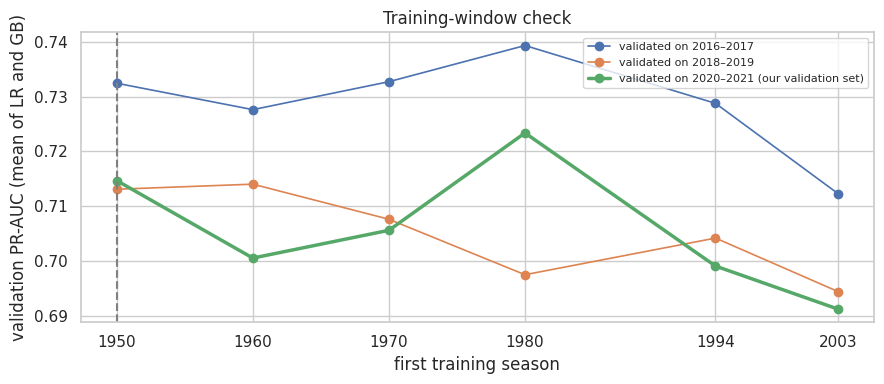

In [48]:
def make_preprocessor(scale=True):
    """The two steps of this section: imputation (+ indicators) and, for LR / NN, scaling."""
    steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        steps.append(("scale", StandardScaler()))
    return steps

def make_lr():
    """Logistic regression with its preprocessing: impute -> scale -> model."""
    return Pipeline(make_preprocessor(scale=True) + [("model", LogisticRegression(max_iter=3000))])

# DECISION D28 → see DECISIONS.md  (gradient boosting without early stopping: deterministic, no random row hold-out)
def make_hgb(**params):
    """Gradient boosting with its preprocessing: impute -> model. early_stopping is OFF: scikit-learn's default turns it on
    above 10,000 rows and then holds out a RANDOM 10% of rows, which would mix drivers of the same race (against D18)."""
    return Pipeline(make_preprocessor(scale=False) + [("model", HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **params))])

# Check: the pipeline gives exactly the same predictions as the step-by-step version.
check = LogisticRegression(max_iter=3000).fit(X_train_scaled, y_train)
assert np.allclose(make_lr().fit(X_train, y_train).predict_proba(X_val), check.predict_proba(X_val_scaled))

START_YEARS = [1950, 1960, 1970, 1980, 1994, 2003]

def window_predictions(v0, v1, starts):
    """For each start year: train LR and GB on seasons start..v0-1, predict the seasons v0..v1."""
    frame = model_table[model_table["year"].between(v0, v1)]
    preds, rows = {}, []
    for start in starts:
        tr = model_table[model_table["year"].between(start, v0 - 1)]
        preds[f"{start} LR"] = make_lr().fit(tr[FEATURES], tr["podium"]).predict_proba(frame[FEATURES])[:, 1]
        preds[f"{start} GB"] = make_hgb().fit(tr[FEATURES], tr["podium"]).predict_proba(frame[FEATURES])[:, 1]
        rows.append({"train from": start, "training rows": len(tr),
                     "LR": average_precision_score(frame["podium"], preds[f"{start} LR"]),
                     "GB": average_precision_score(frame["podium"], preds[f"{start} GB"])})
    table = pd.DataFrame(rows).set_index("train from")
    table["mean"] = (table["LR"] + table["GB"]) / 2
    return frame, preds, table

# Main check: our validation seasons (2020-2021), every start year compared with 1950 on the same redrawn races.
frame, preds, windows = window_predictions(2020, 2021, START_YEARS)
b = race_bootstrap(frame, preds)
mean_1950 = (b["1950 LR"] + b["1950 GB"]) / 2
gain = {s: (b[f"{s} LR"] + b[f"{s} GB"]) / 2 - mean_1950 for s in START_YEARS[1:]}
windows["gain vs 1950"] = windows["mean"] - windows.loc[1950, "mean"]
windows["95% CI of gain"] = [""] + [ci(gain[s]) for s in START_YEARS[1:]]
windows["clearly better than 1950"] = [""] + ["yes" if np.percentile(gain[s], 2.5) > 0 else "no" for s in START_YEARS[1:]]
print("Validation PR-AUC on 2020–2021 by first training season (models trained up to 2019):")
display(windows.round(4))
better = [s for s in START_YEARS[1:] if np.percentile(gain[s], 2.5) > 0]
print("Start years clearly better than 1950:", better or "none → train on every season from 1950 (D17)")

# Robustness: the same comparison on two earlier validation periods.
robust = {}
for v0, v1 in [(2016, 2017), (2018, 2019)]:
    robust[f"{v0}–{v1}"] = window_predictions(v0, v1, START_YEARS)[2]["mean"]
robust["2020–2021"] = windows["mean"]
robust = pd.DataFrame(robust)
print("Mean validation PR-AUC (LR and GB) by first training season and validation period:")
display(robust.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
for vp in robust.columns:
    ax.plot(robust.index, robust[vp], marker="o", lw=2.5 if vp == "2020–2021" else 1.2,
            label=f"validated on {vp}" + (" (our validation set)" if vp == "2020–2021" else ""))
ax.axvline(TRAIN_START, color="gray", ls="--")
ax.set_xticks(START_YEARS); ax.set_xlabel("first training season")
ax.set_ylabel("validation PR-AUC (mean of LR and GB)"); ax.set_title("Training-window check"); ax.legend(fontsize=8)
save_fig("14_training_window")


**What this shows** *(numbers from the output above)*.
* **No later start year beats 1950 on our validation seasons.** Training from 1950 gives the highest mean PR-AUC (0.7230). Every later start is lower: 1960 (−0.0201), 1970 (−0.0073), 1980 (−0.0093), 1994 (−0.0266) and 2003 (−0.0275). No interval of a gain lies above 0, so by the rule the models train on every season from 1950. Three of them lie entirely **below** 0 (1960, 1994 and 2003): starting there is significantly worse.
* **The two models react differently to dropping seasons.** For the logistic regression a later start scores slightly higher (0.7331 from 2003 vs 0.7226 from 1950), but gradient boosting loses much more (0.7235 from 1950, 0.6655 from 1994, 0.6579 from 2003): a flexible model needs many rows to learn from. Gradient boosting also moves between neighbouring start years (0.6820 from 1960), so single gaps are partly noise; the robust pattern is that no later start helps.
* **Earlier validation periods (second table)** show no start year that is best everywhere: 1980 is highest for 2016–17 (0.7443), 1950 for 2018–19 (0.7168) and for 2020–21. Starting in 2003 is the lowest in all three periods.

**Conclusion.** Leaving seasons out does not improve the predictions, so the models are trained on all seasons from 1950 to 2019 (D17). The seasons without qualifying data still help: the grid position carries almost the same information (6.7), and the missing-value indicators let the models treat those rows differently.

### 8.5 Experiment E4 — how to fill the missing qualifying values (D19)

Since D17 the training seasons start in 1950, so qualifying is missing for 63% of training rows (every row before 1994). Is median imputation still a sensible way to fill them? We compare three options with the same rows, features and models (logistic regression and default gradient boosting), scored on validation and compared with the current choice by the paired race bootstrap (D23):
* **median + missing indicator** (our choice, D19);
* **median without indicator**: the filled values look like real ones;
* **grid fallback**: a missing `quali_position` takes the grid slot and a missing `grid_penalty` becomes 0 (a "fall back to grid" option), still with the indicators.

In [49]:
# DECISION D19 → experiment E4: three ways to fill missing qualifying values, compared on validation.
def grid_fallback(X):
    """Missing qualifying position = grid slot; missing grid_penalty = 0 (then the usual imputation for the rest)."""
    X = X.copy(); miss = X["quali_position"].isna()
    X.loc[miss, "quali_position"] = X.loc[miss, "grid_pos"]
    X.loc[miss & X["grid_penalty"].isna(), "grid_penalty"] = 0
    return X

def no_indicator(model):
    """The same pipeline with median imputation but without the missing indicators."""
    model.set_params(impute__add_indicator=False)
    return model

e4_preds = {}
for label, prep, build in [("median + indicator (our choice)", lambda X: X, lambda m: m),
                           ("median, no indicator", lambda X: X, no_indicator),
                           ("grid fallback + indicator", grid_fallback, lambda m: m)]:
    e4_preds[f"{label} | LR"] = build(make_lr()).fit(prep(X_train), y_train).predict_proba(prep(X_val))[:, 1]
    e4_preds[f"{label} | GB"] = build(make_hgb()).fit(prep(X_train), y_train).predict_proba(prep(X_val))[:, 1]
b4 = race_bootstrap(val, e4_preds)
e4 = []
for key, p in e4_preds.items():
    label, model = key.split(" | ")
    ref = f"median + indicator (our choice) | {model}"
    e4.append({"option": label, "model": model, "val PR-AUC": average_precision_score(y_val, p),
               "change vs our choice (95% CI)": "" if key == ref else ci(b4[key] - b4[ref])})
e4 = pd.DataFrame(e4)
print("Experiment E4, validation PR-AUC (2020–2021):")
display(e4.pivot(index="option", columns="model", values="val PR-AUC").round(4))
display(e4.pivot(index="option", columns="model", values="change vs our choice (95% CI)"))

Experiment E4, validation PR-AUC (2020–2021):


model,GB,LR
option,,
grid fallback + indicator,0.6820,0.7154
median + indicator (our choice),0.7067,0.7226
"median, no indicator",0.7133,0.7103


model,GB,LR
option,,
grid fallback + indicator,-0.069 to +0.016,-0.014 to -0.001
median + indicator (our choice),,
"median, no indicator",-0.013 to +0.020,-0.023 to -0.003


**What this shows** *(numbers from the output above)*.
* **Median + indicator is the best of the three options for both models** (validation PR-AUC 0.7226 for the logistic regression, 0.7235 for gradient boosting).
* **Without the indicator** the logistic regression loses significantly (0.7103, change −0.023 to −0.003); gradient boosting drops to 0.7017 (interval −0.048 to +0.010). The median value itself is only a placeholder: the indicator tells the model which values were invented, so it treats the rows without qualifying as a group that relies on the grid.
* **Grid fallback** is significantly worse for both models (LR 0.7154, −0.014 to −0.001; GB 0.6633, −0.087 to −0.013). Filling qualifying with the grid slot makes the two identical and erases the "penalised front-row qualifier" signal that Q1 found.

**Conclusion.** Median imputation with missing indicators stays (D19), even with 63% of training rows missing qualifying. Its known cost: the indicator also marks the old era, so a modern record without qualifying is read partly like a pre-1994 row (Section 12).

## 9. Models

All models are trained on **the same rows** (seasons 1950–2019) with **the same 18 features**, and evaluated on the same validation and test seasons, so their scores are directly comparable. Thresholds and hyperparameters are chosen on **validation only**.

**Every model cell follows the same steps:**
1. **create** the model (for example `LogisticRegression(...)`);
2. **fit** it on the training rows, using the data version it needs (Section 8): `X_train_scaled` for logistic regression and the network, `X_train_imp` for the tree models;
3. **predict** podium probabilities for train, validation and test;
4. **evaluate**: choose the decision threshold on **validation** (D22), then print every metric for train, validation and test.

The test rows are only predicted and scored, never used to fit a model or to choose anything, so reporting the test score is not leakage: it is the score of a model that never saw those seasons.

| # | model | role | how it works |
|---|---|---|---|
| 0 | grid rule | reference, no learning | score = 1 / grid slot: "the further forward you start, the likelier the podium". Tells us how much the learned models add on top of starting position. |
| 1 | logistic regression | **baseline** | computes a weighted sum of the (scaled) features, `z = w·x + b`, and turns it into a probability with the sigmoid `1 / (1 + e^(−z))`. The weights are fitted by minimising log-loss with a small L2 penalty. Each weight says how much one feature moves the log-odds of a podium, holding the others fixed. |
| 2 | random forest | statistical model | builds 400 decision trees, each on a bootstrap sample of rows and choosing among a random subset of features at every split; the predicted probability is the average of the trees' leaf podium-shares. Averaging many different trees reduces the variance of single trees. |
| 3 | gradient boosting (default) | statistical model | builds small trees one after another; each new tree is fitted to the errors (gradients of the log-loss) of the current model and added with a small learning rate. Features are binned into histograms first, which makes it fast. |
| 4 | gradient boosting (tuned) | hyperparameter attempt | the same, with settings chosen on validation from a grid of 54 combinations. |
| 5 | shallow NN, 2 hidden layers | neural network | the 32 imputed and scaled columns (18 features + 14 missing indicators) → 32 → 16 ReLU units → 1 sigmoid output. Trained with backpropagation and the Adam optimiser on log-loss; dropout (randomly switching off 20% of units while training) and an L2 penalty reduce overfitting; training stops when validation PR-AUC stops improving. |

Together these are more than the three distinct modeling attempts the brief asks for (three model families, settings for the forest and a hyperparameter search for gradient boosting chosen on validation, and a neural network), each in its own cell below.

🔶 **Decision D20 — class imbalance: no class weights for any model.** Only 13.4% of training rows are podiums. Balanced class weights would make each podium row count ~6× in the loss, so a model cannot just say "no podium". But weights also push every predicted probability up, so the outputs stop being real probabilities, and the inference function (Section 12) returns a probability. All five models, the random forest included, are therefore trained **unweighted**; the imbalance is handled by the threshold (D22) and by PR-AUC as the main metric (D21). The forest grid in 9.1 still compares weighted and unweighted forests to show that the weights bring no gain. The validation Brier scores in 9.4 show that the unweighted models give usable probabilities.


In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve

RESULTS, scores = {}, []        # per model: probabilities on each split and the threshold; and the score tables

def evaluate(name, p_train, p_val, p_test):
    """Step 4 for every model. The threshold is chosen on VALIDATION only (D22) and then used unchanged on train and test."""
    thr = best_f1_threshold(y_val, p_val)
    RESULTS[name] = {"p": {"train": p_train, "validation": p_val, "test": p_test}, "thr": thr}
    rows = []
    for split_name, frame, y, p in [("train", train, y_train, p_train), ("validation", val, y_val, p_val), ("test", test, y_test, p_test)]:
        rows.append({"model": name, "split": split_name, **metrics(y, p, thr),
                     "race top-3 hit rate": race_top3_hit_rate(frame, p),
                     "predicted podiums per race": float((p >= thr).sum() / frame["raceId"].nunique()), "threshold": thr})
    table = pd.DataFrame(rows)
    scores.append(table)
    print(f"{name}  (threshold {thr:.3f}, chosen on validation)")
    display(table.set_index("split")[["PR-AUC", "ROC-AUC", "F1", "precision", "recall", "Brier"]].round(3))

# 0. Reference rule, no learning: score = 1 / grid slot (the further forward, the higher)
evaluate("0. grid rule (no learning)", 1 / X_train["grid_pos"].values, 1 / X_val["grid_pos"].values, 1 / X_test["grid_pos"].values)

# 1. Logistic regression (the baseline). Data: imputed + scaled.
BASELINE = "1. logistic regression (baseline)"
log_reg = LogisticRegression(max_iter=3000)          # C = 1.0: scikit-learn's default, a mild L2 penalty
log_reg.fit(X_train_scaled, y_train)
evaluate(BASELINE,
         log_reg.predict_proba(X_train_scaled)[:, 1],
         log_reg.predict_proba(X_val_scaled)[:, 1],
         log_reg.predict_proba(X_test_scaled)[:, 1])

# The fitted imputer, scaler and model chained together, so Sections 10-12 can call lr.predict_proba(raw features).
lr = Pipeline([("impute", imputer), ("scale", scaler), ("model", log_reg)])

0. grid rule (no learning)  (threshold 0.333, chosen on validation)


,PR-AUC,ROC-AUC,F1,precision,recall,Brier
split,,,,,,
train,0.496,0.883,0.543,0.543,0.543,0.091
validation,0.639,0.910,0.692,0.692,0.692,0.083
test,0.645,0.913,0.647,0.647,0.647,0.081


1. logistic regression (baseline)  (threshold 0.241, chosen on validation)


,PR-AUC,ROC-AUC,F1,precision,recall,Brier
split,,,,,,
train,0.570,0.900,0.582,0.481,0.737,0.078
validation,0.723,0.932,0.699,0.613,0.812,0.067
test,0.722,0.937,0.673,0.546,0.877,0.068


### 9.1 Random forest: settings chosen on validation

🔶 **Decision D29** — forest settings chosen on validation; logistic regression keeps scikit-learn's default L2 strength (C = 1).

The setting that matters most for a forest is the **minimum number of rows in a leaf** (small leaves memorise single races, large leaves smooth too much). We choose it on validation among the unweighted forests (D20). The grid also shows weighted forests next to them, to check whether class weights would bring a gain; then we check how much the chosen forest moves between random seeds.

**Result** *(numbers from the output below)*: leaf size 100 is best (validation PR-AUC 0.7334). The best weighted forest scores 0.7310, 0.0024 lower, so weights bring no gain and the forest stays unweighted. The forest's in-sample training PR-AUC (0.599) is above its out-of-bag estimate (0.573), which is the training number reported.

In [51]:
# DECISION D29 → see DECISIONS.md  (forest leaf size chosen on validation; out-of-bag training score)
# Settings search: every combination is fitted on train (imputed data) and scored on validation.
rf_grid = []
for leaf in [5, 10, 20, 50, 100]:
    for cw in [None, "balanced_subsample"]:
        model = RandomForestClassifier(n_estimators=400, min_samples_leaf=leaf, max_features="sqrt", class_weight=cw, n_jobs=-1, random_state=SEED)
        model.fit(X_train_imp, y_train)
        rf_grid.append({"min_samples_leaf": leaf, "class_weight": str(cw), "val PR-AUC": average_precision_score(y_val, model.predict_proba(X_val_imp)[:, 1])})
rf_grid = pd.DataFrame(rf_grid)
display(rf_grid.pivot(index="min_samples_leaf", columns="class_weight", values="val PR-AUC").round(4))
# DECISION D20 → the forest is unweighted like the other models: weights inflate the probabilities, and the grid
# shows whether weighting brings a gain larger than the forest's seed spread. Only the leaf size is chosen here.
unweighted = rf_grid[rf_grid["class_weight"] == "None"]
best_rf = unweighted.loc[unweighted["val PR-AUC"].idxmax()]
RF_PARAMS = dict(n_estimators=400, min_samples_leaf=int(best_rf["min_samples_leaf"]), max_features="sqrt", class_weight=None, n_jobs=-1)
print("Chosen on validation:", RF_PARAMS)
best_by_cw = rf_grid.groupby("class_weight")["val PR-AUC"].max()
print(f"Best validation PR-AUC per class-weight setting: {best_by_cw.round(4).to_dict()}, "
      f"a gap of {best_by_cw.get('balanced_subsample') - best_by_cw.get('None'):+.4f} for the weighted forest (compare with the seed spread in 9.3).")

# 2. Random forest with the chosen settings. Data: imputed (trees need no scaling).
rf_model = RandomForestClassifier(random_state=SEED, oob_score=True, **RF_PARAMS)
rf_model.fit(X_train_imp, y_train)
# Training score: the out-of-bag estimate (each training row predicted only by trees that did not see it).
# The in-sample score of a forest is inflated because it has memorised its training rows.
rf_oob = rf_model.oob_decision_function_[:, 1]
evaluate("2. random forest",
         rf_oob,
         rf_model.predict_proba(X_val_imp)[:, 1],
         rf_model.predict_proba(X_test_imp)[:, 1])
print(f"Random forest train PR-AUC in-sample {average_precision_score(y_train, rf_model.predict_proba(X_train_imp)[:, 1]):.3f} "
      f"vs out-of-bag {average_precision_score(y_train, rf_oob):.3f}")

rf = Pipeline([("impute", imputer), ("model", rf_model)])     # for Sections 10-12

def make_rf(seed=SEED):
    """The forest with its preprocessing, for retraining with other seeds (9.3) and in the ablation (Section 10)."""
    return Pipeline(make_preprocessor(scale=False) + [("model", RandomForestClassifier(random_state=seed, oob_score=True, **RF_PARAMS))])

class_weight,None,balanced_subsample
min_samples_leaf,,
5,0.7013,0.7047
10,0.7173,0.7230
20,0.7221,0.7193
50,0.7317,0.7313
100,0.7334,0.7322


Chosen on validation: {'n_estimators': 400, 'min_samples_leaf': 100, 'max_features': 'sqrt', 'class_weight': None, 'n_jobs': -1}
Best validation PR-AUC per class-weight setting: {'None': 0.7334, 'balanced_subsample': 0.7322}, a gap of -0.0012 for the weighted forest (compare with the seed spread in 9.3).
2. random forest  (threshold 0.279, chosen on validation)


,PR-AUC,ROC-AUC,F1,precision,recall,Brier
split,,,,,,
train,0.573,0.901,0.585,0.500,0.706,0.078
validation,0.733,0.932,0.708,0.643,0.786,0.067
test,0.722,0.940,0.672,0.563,0.833,0.069


Random forest train PR-AUC in-sample 0.599 vs out-of-bag 0.573


### 9.2 Gradient boosting: default, then a hyperparameter search on validation

🔶 **Decision D28** — gradient boosting always runs with early stopping switched off (scikit-learn would otherwise hold out a random 10% of rows above 10,000 rows, mixing drivers of the same race and making results seed-dependent), and its settings come from the grid search below.

We try 54 combinations of four settings, each trained on the training seasons and scored on validation PR-AUC. The test set is not touched.

* `learning_rate`: how big a step each new tree takes (smaller = slower, more careful learning)
* `max_iter`: how many trees are added
* `max_leaf_nodes`: how complex each tree can be
* `min_samples_leaf`: the minimum number of rows in a leaf (bigger = smoother, less overfitting)

The default (`learning_rate=0.1`, `max_iter=100`, `max_leaf_nodes=31`, `min_samples_leaf=20`) is one of the 54 points, so the search can only match or beat it on validation.

3. gradient boosting (default)  (threshold 0.308, chosen on validation)


,PR-AUC,ROC-AUC,F1,precision,recall,Brier
split,,,,,,
train,0.765,0.957,0.697,0.603,0.824,0.058
validation,0.707,0.925,0.696,0.662,0.735,0.069
test,0.699,0.928,0.652,0.602,0.711,0.072


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,val PR-AUC
0,0.01,50,7,20,0.7322
1,0.01,50,7,80,0.7322
32,0.03,300,15,20,0.7309
19,0.03,50,7,80,0.7305
6,0.01,100,7,20,0.7299
7,0.01,100,7,80,0.7298
18,0.03,50,7,20,0.7292
9,0.01,100,15,80,0.7273


Chosen on validation: {'learning_rate': 0.01, 'max_iter': 50, 'max_leaf_nodes': 7, 'min_samples_leaf': 20}
4. gradient boosting (tuned)  (threshold 0.214, chosen on validation)


,PR-AUC,ROC-AUC,F1,precision,recall,Brier
split,,,,,,
train,0.575,0.899,0.587,0.534,0.651,0.092
validation,0.732,0.926,0.704,0.669,0.744,0.094
test,0.704,0.936,0.680,0.626,0.745,0.096


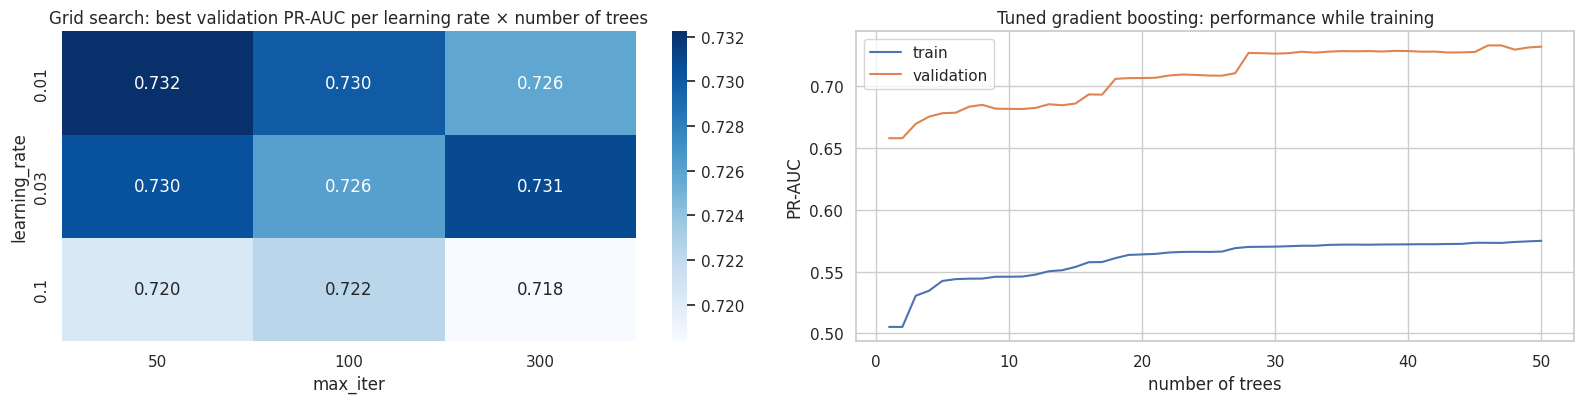

In [52]:
import itertools
# DECISION D28 → see DECISIONS.md  (early stopping off)
# 3. Gradient boosting with scikit-learn's default settings. Data: imputed (trees need no scaling).
gb_default = HistGradientBoostingClassifier(early_stopping=False, random_state=SEED)
gb_default.fit(X_train_imp, y_train)
evaluate("3. gradient boosting (default)",
         gb_default.predict_proba(X_train_imp)[:, 1],
         gb_default.predict_proba(X_val_imp)[:, 1],
         gb_default.predict_proba(X_test_imp)[:, 1])
hgb = Pipeline([("impute", imputer), ("model", gb_default)])     # for Sections 10-12

# Hyperparameter search: every combination (3 × 3 × 3 × 2 = 54) is fitted on train and scored on validation.
grid_search = []
for rate, n_trees, leaves, leaf_min in itertools.product([0.01, 0.03, 0.1], [50, 100, 300], [7, 15, 31], [20, 80]):
    params = dict(learning_rate=rate, max_iter=n_trees, max_leaf_nodes=leaves, min_samples_leaf=leaf_min)
    model = HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **params)
    model.fit(X_train_imp, y_train)
    grid_search.append({**params, "val PR-AUC": average_precision_score(y_val, model.predict_proba(X_val_imp)[:, 1])})
grid_search = pd.DataFrame(grid_search).sort_values("val PR-AUC", ascending=False)
display(grid_search.head(8).round(4))
BEST_HGB_PARAMS = {k: (float(v) if k == "learning_rate" else int(v)) for k, v in
                   grid_search.iloc[0][["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf"]].items()}
print("Chosen on validation:", BEST_HGB_PARAMS)

# 4. Gradient boosting with the chosen settings.
gb_tuned = HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **BEST_HGB_PARAMS)
gb_tuned.fit(X_train_imp, y_train)
evaluate("4. gradient boosting (tuned)",
         gb_tuned.predict_proba(X_train_imp)[:, 1],
         gb_tuned.predict_proba(X_val_imp)[:, 1],
         gb_tuned.predict_proba(X_test_imp)[:, 1])
hgb_tuned = Pipeline([("impute", imputer), ("model", gb_tuned)])  # for Sections 10-12

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
pv = grid_search.groupby(["learning_rate", "max_iter"])["val PR-AUC"].max().unstack()
sns.heatmap(pv, annot=True, fmt=".3f", cmap="Blues", ax=axes[0])
axes[0].set_title("Grid search: best validation PR-AUC per learning rate × number of trees")
# Learning curve of the tuned model: PR-AUC on train and validation after each added tree.
stage_tr = [average_precision_score(y_train, p[:, 1]) for p in gb_tuned.staged_predict_proba(X_train_imp)]
stage_va = [average_precision_score(y_val, p[:, 1]) for p in gb_tuned.staged_predict_proba(X_val_imp)]
axes[1].plot(range(1, len(stage_tr) + 1), stage_tr, label="train"); axes[1].plot(range(1, len(stage_va) + 1), stage_va, label="validation")
axes[1].set_xlabel("number of trees"); axes[1].set_ylabel("PR-AUC"); axes[1].legend()
axes[1].set_title("Tuned gradient boosting: performance while training")
save_fig("17a_gbm_search_and_curve")

**What this shows** *(numbers from the output above)*. The best settings learn **slowly and with very simple trees**: learning rate 0.01 and only 50 trees of at most 7 leaves (validation PR-AUC 0.7361; min leaf 20 and 80 tie). The default (learning rate 0.1, 100 trees of 31 leaves) fits the training seasons much better (train PR-AUC 0.765 vs 0.574) but scores lower on validation (0.724 vs 0.736): it memorises more. The tuned model's training score is not above its validation score, so it shows no sign of overfitting. Three caveats:
* The best point lies at the corner of the grid (smallest learning rate, fewest trees, smallest trees), so an even simpler model would probably do about as well, consistent with the logistic regression results below.
* With so little learning, the tuned model's predictions stay close to the average podium rate: its validation Brier score is 0.094 against 0.070 for the default, and even Verstappen from pole gets only 0.357 (11.3). Its outputs rank drivers well (that is what PR-AUC measures) but cannot be read as probabilities.
* The best of 54 tries on 39 races is an optimistic validation score: on test the tuned and the default model score about the same (0.696 vs 0.693).

### 9.3 Shallow neural network

🔶 **Decision D25 — the shallow neural network.** The brief asks for a network with roughly 1–2 hidden layers and allows a standard library, so we build it with Keras (`build_nn`, defined in 8.2):

| part | our choice | in plain words |
|---|---|---|
| input | the 32 columns: 18 features + 14 missing indicators (`X_train_scaled`) | the same imputed and scaled data as logistic regression |
| hidden layer 1 | 32 units, ReLU | each unit combines all inputs with its own weights; ReLU keeps positive values and sets negative ones to 0 |
| hidden layer 2 | 16 units, ReLU | combines the 32 patterns of layer 1 |
| output | 1 unit, sigmoid | squeezes the result into a number between 0 and 1: the probability of a podium |
| loss | binary cross-entropy | the standard loss for a yes/no prediction; no class weights (D20) |
| optimiser | Adam, learning rate 0.001, batches of 128 rows | how the weights are adjusted after each batch of rows |
| against overfitting | dropout 20% and an L2 penalty of 0.0001 on the hidden layers | dropout switches off 20% of the units at random in every training step, so the network cannot rely on single units; L2 adds a cost for large weights, keeping the network simple |
| early stopping | stop when validation PR-AUC has not improved for 15 epochs, keep the best epoch's weights | the number of epochs does not have to be guessed |
| seeds | 3 training runs (seeds 42, 1 and 2) | each run starts from different random weights; the spread shows how much the result depends on luck. The seed-42 network is the one in the comparison table |

**Why two small hidden layers:** this is inside the 1–2 layers the brief asks for, and the network has only 1,601 weights (printed below), few compared with 22,576 training rows, which keeps overfitting in check. *Note:* Keras computes PR-AUC with an approximation, so the PR-AUC it tracks during training differs slightly from scikit-learn's exact value in the tables.


Weights the network learns: 1,601
5. shallow NN (2 hidden layers: 32-16)  (threshold 0.265, chosen on validation)


,PR-AUC,ROC-AUC,F1,precision,recall,Brier
split,,,,,,
train,0.588,0.906,0.588,0.477,0.764,0.077
validation,0.716,0.929,0.703,0.641,0.778,0.068
test,0.711,0.937,0.667,0.569,0.804,0.070


val PR-AUC                         test PR-AUC                        
                                             mean     std     min     max        mean     std     min     max
model                                                                                                        
2. random forest                           0.7275  0.0053  0.7229  0.7334      0.7227  0.0015  0.7218  0.7244
5. shallow NN (2 hidden layers: 32-16)     0.7190  0.0028  0.7158  0.7207      0.6970  0.0147  0.6819  0.7112

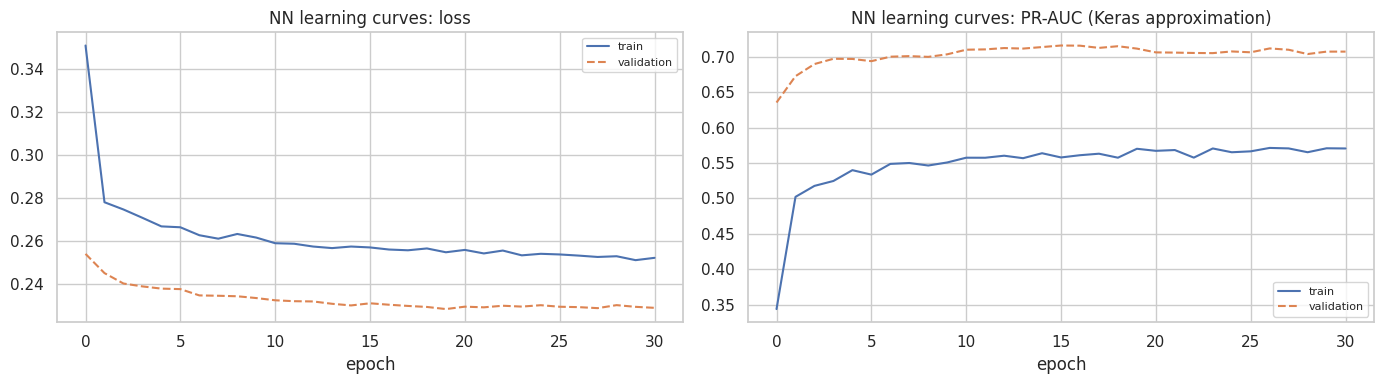

In [53]:
# DECISION D25 → see DECISIONS.md  (shallow network design; build_nn and fit_nn are defined in 8.2)
# 5. Shallow neural network. Data: imputed + scaled (the same matrices as logistic regression).
NN_NAME = "5. shallow NN (2 hidden layers: 32-16)"
seed_rows = []
for s in [SEED, 1, 2]:                                 # 3 random starts, to see how much the result depends on luck
    net = build_nn(X_train_scaled.shape[1], hidden=(32, 16), seed=s)
    history = fit_nn(net, X_train_scaled, X_val_scaled)
    seed_rows.append({"model": NN_NAME, "seed": s, "epochs": len(history.history["loss"]),
                      "val PR-AUC": average_precision_score(y_val, net.predict(X_val_scaled, verbose=0).ravel()),
                      "test PR-AUC": average_precision_score(y_test, net.predict(X_test_scaled, verbose=0).ravel())})
    if s == SEED:
        nn_model, NN_HISTORY = net, history.history     # the seed-42 network is the one evaluated below
print(f"Weights the network learns: {nn_model.count_params():,}")
evaluate(NN_NAME,
         nn_model.predict(X_train_scaled, verbose=0).ravel(),
         nn_model.predict(X_val_scaled, verbose=0).ravel(),
         nn_model.predict(X_test_scaled, verbose=0).ravel())

# Seed variability of the random models: forest and network (gradient boosting is deterministic here).
for s in [1, 2]:
    model = RandomForestClassifier(random_state=s, oob_score=True, **RF_PARAMS)
    model.fit(X_train_imp, y_train)
    seed_rows.append({"model": "2. random forest", "seed": s, "epochs": None,
                      "val PR-AUC": average_precision_score(y_val, model.predict_proba(X_val_imp)[:, 1]),
                      "test PR-AUC": average_precision_score(y_test, model.predict_proba(X_test_imp)[:, 1])})
seed_rows.append({"model": "2. random forest", "seed": SEED, "epochs": None,
                  "val PR-AUC": average_precision_score(y_val, RESULTS["2. random forest"]["p"]["validation"]),
                  "test PR-AUC": average_precision_score(y_test, RESULTS["2. random forest"]["p"]["test"])})
seeds = pd.DataFrame(seed_rows)
display(seeds.groupby("model")[["val PR-AUC", "test PR-AUC"]].agg(["mean", "std", "min", "max"]).round(4))

class NNPipeline:
    """The network with its preprocessing (impute -> scale -> network), used like the scikit-learn pipelines:
    fit(raw features, labels) and predict_proba(raw features). Used for retraining in the ablation (Section 10),
    and with the network fitted above for the explanations and the inference function (Sections 11-12)."""
    def __init__(self, seed=SEED, imputer=None, scaler=None, net=None):
        self.seed, self.imputer, self.scaler, self.net = seed, imputer, scaler, net

    def fit(self, X, y):
        assert len(X) == len(X_train), "the network is always trained on the training rows (early stopping uses validation)"
        self.imputer = SimpleImputer(strategy="median", add_indicator=True)
        self.scaler = StandardScaler()
        A = self.scaler.fit_transform(self.imputer.fit_transform(X))
        A_val = self.scaler.transform(self.imputer.transform(val[list(X.columns)]))   # val holds all 21 candidates
        self.net = build_nn(A.shape[1], seed=self.seed)
        fit_nn(self.net, A, A_val)
        return self

    def transform(self, X):
        return self.scaler.transform(self.imputer.transform(X))

    def predict_proba(self, X):
        p = self.net.predict(self.transform(X), verbose=0, batch_size=4096).ravel()
        return np.column_stack([1 - p, p])

nn = NNPipeline(imputer=imputer, scaler=scaler, net=nn_model)     # the seed-42 network, for Sections 10-12
assert np.allclose(nn.predict_proba(X_val)[:, 1], RESULTS[NN_NAME]["p"]["validation"], atol=1e-6)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(NN_HISTORY["loss"], label="train"); axes[0].plot(NN_HISTORY["val_loss"], ls="--", label="validation")
axes[1].plot(NN_HISTORY["pr_auc"], label="train"); axes[1].plot(NN_HISTORY["val_pr_auc"], ls="--", label="validation")
axes[0].set_title("NN learning curves: loss"); axes[0].set_xlabel("epoch"); axes[0].legend(fontsize=8)
axes[1].set_title("NN learning curves: PR-AUC (Keras approximation)"); axes[1].set_xlabel("epoch"); axes[1].legend(fontsize=8)
save_fig("17_nn_learning_curves")

**What the learning curves and seeds show** *(numbers from the output above)*. Loss and PR-AUC improve quickly in the first ~10 epochs and then flatten; early stopping ends training once validation PR-AUC stops improving and keeps the best epoch. The seed table shows how much the network (validation 0.7158 to 0.7207) and the forest (0.7230 to 0.7334) move just because of their random start: differences between models smaller than that spread mean nothing.

*Why is validation PR-AUC **higher** than training PR-AUC?* It is not leakage: it happens even for the grid rule, which learns nothing (train 0.496 vs validation 0.639; per-period table in 9.4). The training seasons include eras that are much harder to rank (before 1994: bigger and changing fields, frequent breakdowns, no qualifying data), and PR-AUC also depends on the share of podiums, which is lower in training (13.4%) than in validation (15.0%).

### 9.4 Model comparison

🔶 **Decision D24 — compare all models; the logistic regression is the recommended model.**
1. The models are ranked by **validation PR-AUC** (the primary metric); for the random forest and the network we use the **mean over the 3 seeds**, so a lucky seed does not decide.
2. Each model's difference from the baseline gets a paired race-bootstrap interval (D23). A model is called **better than the baseline only if that interval lies entirely above 0**; otherwise the extra complexity has not been shown to help.
3. If no model is better, the **logistic regression is recommended**: it is the simplest model, deterministic, readable and well calibrated. The other four are still reported, explained and given an inference function (Sections 10–12), so they can be compared on the same inputs.


In [54]:
scores = pd.concat(scores, ignore_index=True)
MAIN = ["PR-AUC", "ROC-AUC", "F1", "precision", "recall", "Brier", "race top-3 hit rate", "predicted podiums per race", "threshold"]
for split_name in ["validation", "test", "train"]:
    t = scores[scores["split"] == split_name].set_index("model")[MAIN]
    if split_name == "train":
        print("TRAIN (random forest: out-of-bag estimate; others: in-sample)")
        display(t[["PR-AUC", "ROC-AUC", "F1", "Brier"]].round(3))
        continue
    b = race_bootstrap(val if split_name == "validation" else test, {n: RESULTS[n]["p"][split_name] for n in t.index})
    t.insert(1, "PR-AUC 95% CI", [ci(b[n]) for n in t.index])
    print(split_name.upper(), f"(random-model PR-AUC = base rate = {(y_val if split_name == 'validation' else y_test).mean():.3f})")
    display(t.round(3))
scores.round(4).to_csv(os.path.join(OUT_DIR, "model_comparison.csv"), index=False)

# DECISION D24 → see DECISIONS.md  (rank on validation, seed-averaged; each model vs the baseline with a paired bootstrap)
val_pr = scores[scores["split"] == "validation"].set_index("model")["PR-AUC"].drop("0. grid rule (no learning)")
val_pr.update(seeds.groupby("model")["val PR-AUC"].mean())
b = race_bootstrap(val, {n: RESULTS[n]["p"]["validation"] for n in RESULTS})
ranking = val_pr.sort_values(ascending=False).to_frame("validation PR-AUC (seed mean where applicable)")
ranking["95% CI of difference vs baseline"] = ["" if n == BASELINE else ci(b[n] - b[BASELINE]) for n in ranking.index]
ranking["better than baseline"] = ["" if n == BASELINE else ("yes" if np.percentile(b[n] - b[BASELINE], 2.5) > 0 else "no")
                                   for n in ranking.index]
display(ranking.round(4))
print(f"Baseline − grid rule on validation: 95% CI {ci(b[BASELINE] - b['0. grid rule (no learning)'])}")

# The five learned models, each with its own fitted preprocessing; used by the ablation, the explanations and the inference functions.
MODELS = {BASELINE: lr, "2. random forest": rf, "3. gradient boosting (default)": hgb,
          "4. gradient boosting (tuned)": hgb_tuned, NN_NAME: nn}
SHORT_NAMES = ['1. logistic regression', '2. random forest', '3. GB (default)', '4. GB (tuned)', '5. shallow NN']   # axis labels

VALIDATION (random-model PR-AUC = base rate = 0.150)


,PR-AUC,PR-AUC 95% CI,ROC-AUC,F1,precision,recall,Brier,race top-3 hit rate,predicted podiums per race,threshold
model,,,,,,,,,,
0. grid rule (no learning),0.639,0.541–0.745,0.910,0.692,0.692,0.692,0.083,0.692,3.000,0.333
1. logistic regression (baseline),0.723,0.612–0.836,0.932,0.699,0.613,0.812,0.067,0.675,3.974,0.241
2. random forest,0.733,0.624–0.840,0.932,0.708,0.643,0.786,0.067,0.675,3.667,0.279
3. gradient boosting (default),0.707,0.597–0.819,0.925,0.696,0.662,0.735,0.069,0.684,3.333,0.308
4. gradient boosting (tuned),0.732,0.631–0.833,0.926,0.704,0.669,0.744,0.094,0.675,3.333,0.214
5. shallow NN (2 hidden layers: 32-16),0.716,0.607–0.827,0.929,0.703,0.641,0.778,0.068,0.675,3.641,0.265


TEST (random-model PR-AUC = base rate = 0.150)


,PR-AUC,PR-AUC 95% CI,ROC-AUC,F1,precision,recall,Brier,race top-3 hit rate,predicted podiums per race,threshold
model,,,,,,,,,,
0. grid rule (no learning),0.645,0.590–0.708,0.913,0.647,0.647,0.647,0.081,0.647,3.000,0.333
1. logistic regression (baseline),0.722,0.658–0.785,0.937,0.673,0.546,0.877,0.068,0.662,4.824,0.241
2. random forest,0.722,0.664–0.779,0.940,0.672,0.563,0.833,0.069,0.642,4.441,0.279
3. gradient boosting (default),0.699,0.641–0.759,0.928,0.652,0.602,0.711,0.072,0.637,3.544,0.308
4. gradient boosting (tuned),0.704,0.644–0.764,0.936,0.680,0.626,0.745,0.096,0.642,3.574,0.214
5. shallow NN (2 hidden layers: 32-16),0.711,0.651–0.769,0.937,0.667,0.569,0.804,0.070,0.642,4.235,0.265


TRAIN (random forest: out-of-bag estimate; others: in-sample)


,PR-AUC,ROC-AUC,F1,Brier
model,,,,
0. grid rule (no learning),0.496,0.883,0.543,0.091
1. logistic regression (baseline),0.570,0.900,0.582,0.078
2. random forest,0.573,0.901,0.585,0.078
3. gradient boosting (default),0.765,0.957,0.697,0.058
4. gradient boosting (tuned),0.575,0.899,0.587,0.092
5. shallow NN (2 hidden layers: 32-16),0.588,0.906,0.588,0.077


,validation PR-AUC (seed mean where applicable),95% CI of difference vs baseline,better than baseline
model,,,
4. gradient boosting (tuned),0.7322,-0.026 to +0.035,no
2. random forest,0.7275,-0.010 to +0.024,no
1. logistic regression (baseline),0.7226,,
5. shallow NN (2 hidden layers: 32-16),0.7190,-0.043 to +0.024,no
3. gradient boosting (default),0.7067,-0.049 to +0.016,no


Baseline − grid rule on validation: 95% CI 0.031–0.144


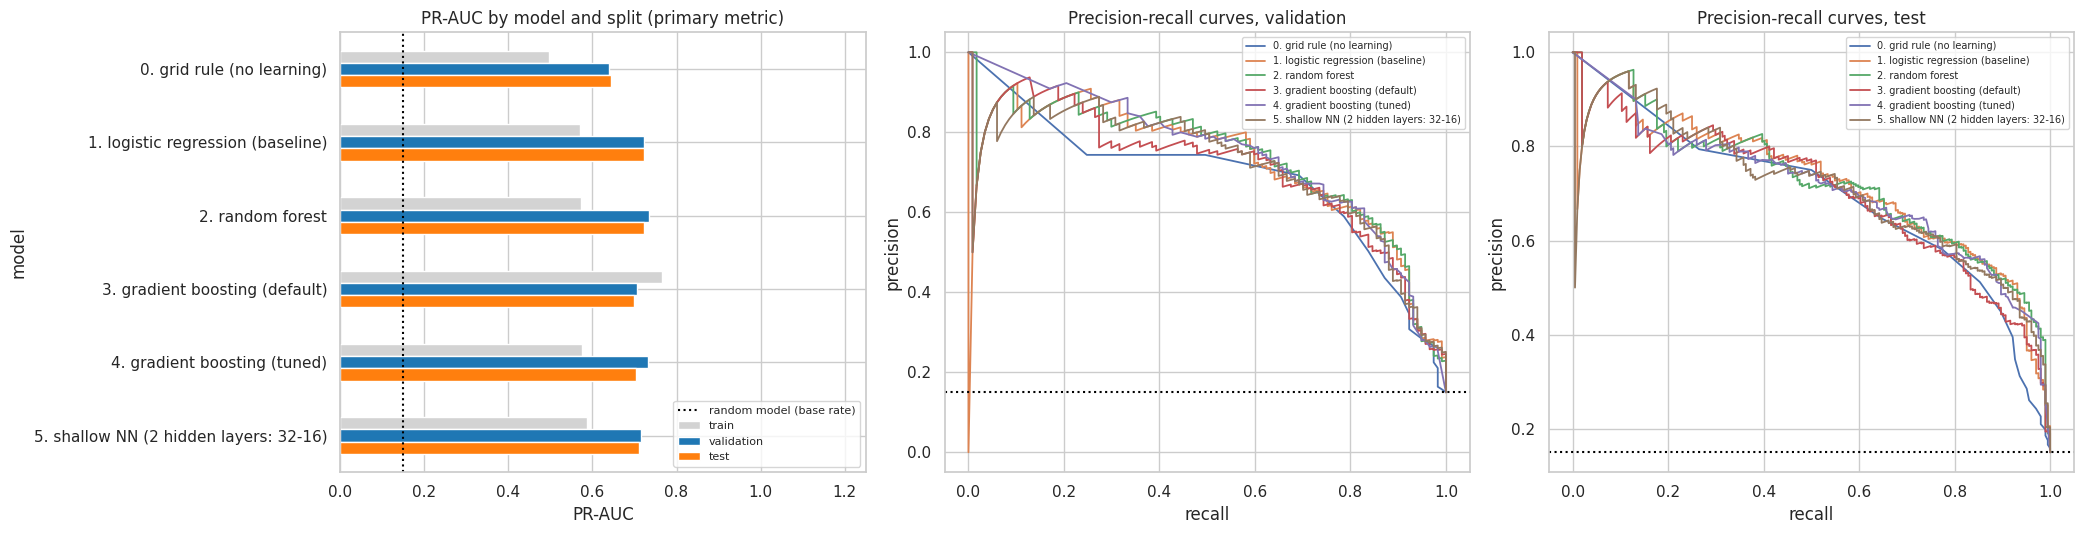

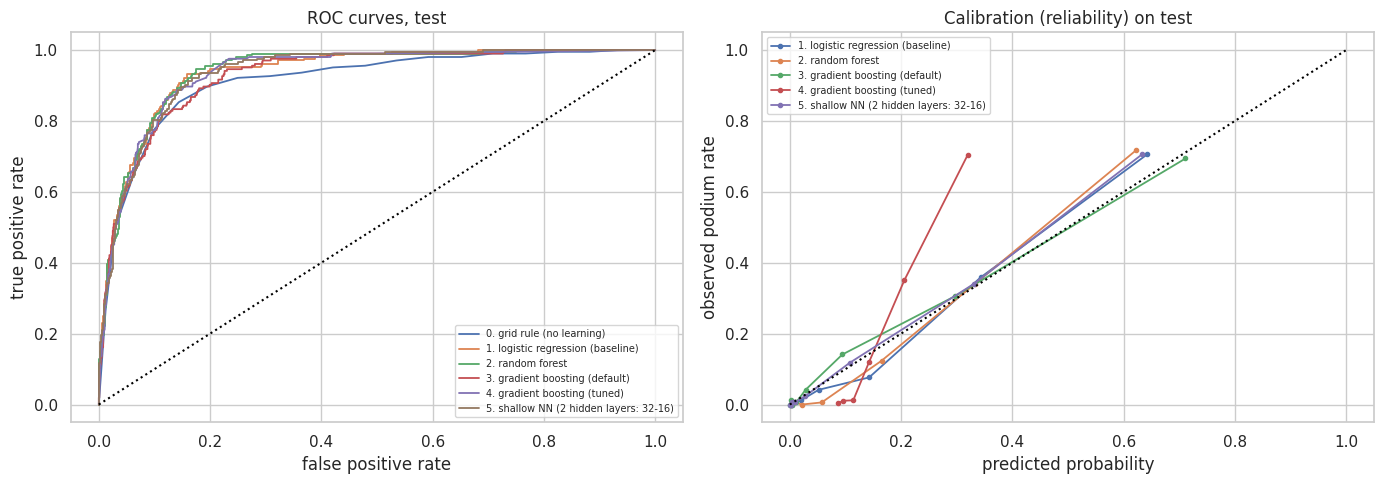

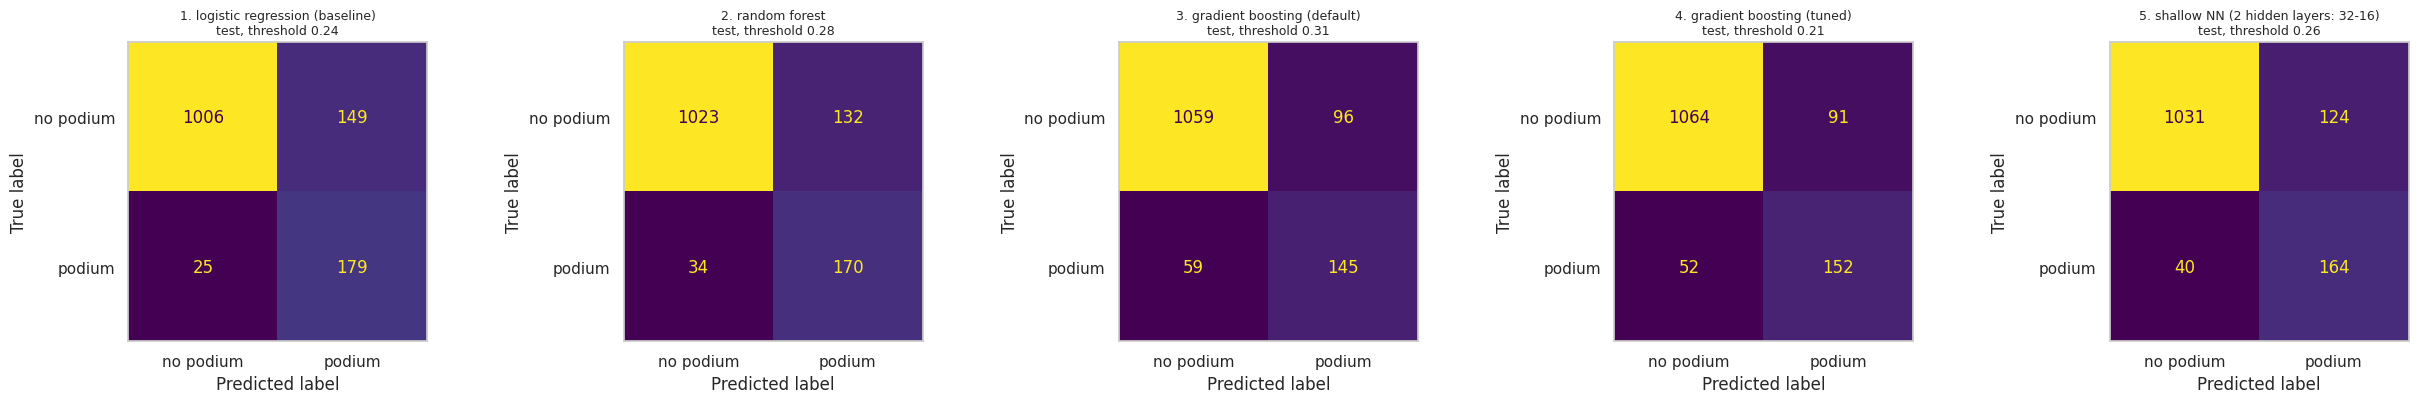

,grid-rule PR-AUC,baseline PR-AUC,podium rate,avg cars
period,,,,
1950–59,0.455,0.491,0.148,20.351
1960–69,0.389,0.445,0.158,18.960
1970–79,0.410,0.456,0.125,24.000
1980–93,0.446,0.513,0.118,25.368
1994–2002,0.513,0.559,0.134,22.356
2003–09,0.582,0.660,0.146,20.602
2010–13,0.602,0.661,0.128,23.442
2014–16,0.683,0.739,0.142,21.119
2017–19,0.701,0.714,0.150,20.000


In [55]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
v = scores.pivot(index="model", columns="split", values="PR-AUC")[["train", "validation", "test"]]
v.plot(kind="barh", ax=axes[0], color=["lightgray", "tab:blue", "tab:orange"])
axes[0].axvline(y_test.mean(), color="black", ls=":", label="random model (base rate)")
axes[0].set_xlim(0, 1.25); axes[0].set_xlabel("PR-AUC"); axes[0].set_title("PR-AUC by model and split (primary metric)")
axes[0].legend(fontsize=8, loc="lower right"); axes[0].invert_yaxis()
for split_name, ax, y in [("validation", axes[1], y_val), ("test", axes[2], y_test)]:
    for name in RESULTS:
        prec, rec, _ = precision_recall_curve(y, RESULTS[name]["p"][split_name])
        ax.plot(rec, prec, lw=1.3, label=name)
    ax.axhline(y.mean(), color="black", ls=":")
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title(f"Precision-recall curves, {split_name}"); ax.legend(fontsize=7)
save_fig("18_model_comparison")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in RESULTS:
    fpr, tpr, _ = roc_curve(y_test, RESULTS[name]["p"]["test"])
    axes[0].plot(fpr, tpr, lw=1.3, label=name)
axes[0].plot([0, 1], [0, 1], color="black", ls=":"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curves, test"); axes[0].legend(fontsize=7)
# Calibration: when a model says 0.7, do 70% of those drivers really podium?
for name in MODELS:
    frac, mean_pred = calibration_curve(y_test, RESULTS[name]["p"]["test"], n_bins=8, strategy="quantile")
    axes[1].plot(mean_pred, frac, marker="o", ms=3, lw=1.3, label=name)
axes[1].plot([0, 1], [0, 1], color="black", ls=":"); axes[1].set_xlabel("predicted probability"); axes[1].set_ylabel("observed podium rate")
axes[1].set_title("Calibration (reliability) on test"); axes[1].legend(fontsize=7)
save_fig("19_roc_calibration")

# Confusion matrix of every learned model on test, at its own validation-tuned threshold.
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4.2))
for ax, name in zip(axes, MODELS):
    cm = confusion_matrix(y_test, RESULTS[name]["p"]["test"] >= RESULTS[name]["thr"])
    ConfusionMatrixDisplay(cm, display_labels=["no podium", "podium"]).plot(ax=ax, colorbar=False)
    ax.grid(False); ax.set_title(f"{name}\ntest, threshold {RESULTS[name]['thr']:.2f}", fontsize=9)
save_fig("19b_confusion_matrices")

# Why is train PR-AUC below validation? The grid rule (no learning) shows the same pattern by period.
periods = [1949, 1959, 1969, 1979, 1993, 2002, 2009, 2013, 2016, 2019, 2021, 2024]
labels = ["1950–59", "1960–69", "1970–79", "1980–93", "1994–2002", "2003–09", "2010–13", "2014–16", "2017–19", "2020–21 (val)", "2022–24 (test)"]
gr = model_table[model_table["year"] >= TRAIN_START].assign(period=lambda d: pd.cut(d["year"], periods, labels=labels))
per_period = gr.groupby("period", observed=True).apply(lambda d: pd.Series({
    "grid-rule PR-AUC": average_precision_score(d["podium"], 1 / d["grid_pos"]),
    "baseline PR-AUC": average_precision_score(d["podium"], lr.predict_proba(d[FEATURES])[:, 1]),
    "podium rate": d["podium"].mean(), "avg cars": d.groupby("raceId").size().mean()}))
display(per_period.round(3))

### 9.5 Interpretation of the comparison

The full numbers are in the tables above. The key points *(all numbers from those tables)*:

* **The learned models clearly beat the grid rule, but not each other.** On validation the baseline logistic regression reaches PR-AUC **0.723** against **0.639** for the grid rule; the bootstrap interval of that difference (0.031 to 0.144) is entirely above 0, so standings, form and qualifying pace add real information on top of starting position. On the unseen test seasons it is 0.722 vs 0.645. A random model would score 0.150.
* **No model is better than the baseline, so the logistic regression is recommended (D24).** Tuned gradient boosting has the highest validation PR-AUC (0.7361), followed by the random forest (0.7276, mean of 3 seeds), default gradient boosting (0.7235), the baseline (0.7226) and the network (0.7190, mean of 3 seeds). Every interval of *model − baseline* includes 0 (for tuned gradient boosting −0.023 to +0.040), so the extra complexity has not been shown to help. On test the baseline ties the random forest for the best score (0.722 each), ahead of the network (0.711), tuned gradient boosting (0.696) and default gradient boosting (0.693), all well inside each other's intervals (about ±0.06). Close scores are expected here: all models rely on the same strong signals (starting position and season strength, Sections 10–11), so the model type matters little.
* **Calibration (D20).** No model uses class weights. The validation Brier scores of the logistic regression (0.067), the random forest (0.067), the network (0.068) and default gradient boosting (0.070) are low, so their outputs can be read as probabilities. Tuned gradient boosting (0.094) is the exception: its slow learning keeps every prediction near the average. The calibration plot is drawn on test, for reference only.
* **Overfitting.** Default gradient boosting has a training PR-AUC of 0.765 but only 0.724 on validation; tuning removes that gap (0.574 train, 0.736 validation). The random forest's in-sample training score (0.599) is above its out-of-bag score (0.573), which is the number shown in the train table.
* **The network** scores about the same as the logistic regression (validation 0.719 averaged over 3 seeds, against 0.723; test 0.711 vs 0.722). It shows no advantage on ~22,600 tabular rows.
* **Train lower than validation.** This happens even for the grid rule (0.496 train vs 0.639 validation). The per-period table shows why: the seasons before 1994 are by far the hardest to rank (grid rule 0.389–0.455 per period, against 0.683–0.701 in 2014–2019). The baseline beats the grid rule in every period.
* **Race top-3 hit rate.** Picking the three highest scores in each race, the learned models catch about as many podium finishers as simply picking the first three on the grid (grid rule 0.692 on validation and 0.647 on test; learned models 0.675 and 0.637–0.662). Their advantage is not in reordering the front of one grid, but in knowing **how likely** each front-runner is to podium across races (a front-row start in the dominant car vs in a midfield car), which is what PR-AUC and the Brier score reward.
* **Decisions at the threshold.** Most F1-optimal thresholds are low (0.241 for the baseline), so the baseline predicts about 4.0 podiums per race on validation and 4.8 on test, more than the 3 that are possible. This follows from scoring each driver independently (limitation below).

### 9.6 Strengths and limitations of each model

| model | strengths | limitations |
|---|---|---|
| logistic regression (**recommended**, D24) | simple, fast, deterministic; coefficients are readable; probabilities are well calibrated; ties for the best test score | assumes each feature moves the log-odds along a straight line; it cannot learn "pole matters more at Monaco" unless we build that feature |
| random forest | captures non-linear effects and interactions; robust to outliers and unscaled features | large; its in-sample score is above its out-of-bag score (it memorises training rows); results move with the random seed |
| gradient boosting | usually strong on tabular data; handles interactions | many hyperparameters; with fast learning and complex trees it overfits (default vs tuned); the tuned version learns so little that its probabilities stay near the average; tuning on a 39-race validation set is noisy |
| shallow NN | can approximate smooth non-linear functions; well calibrated here | needs scaling and careful regularisation; results vary with the random seed; harder to explain (no exact SHAP method); no advantage on ~22,600 tabular rows |

**Limitations shared by all models:** each driver is scored independently, so the model does not know that exactly three drivers podium per race (at the chosen threshold most models predict more than three podiums per race, see the table). There is no information about weather, tyres, safety cars or crashes, which cause many upsets. And the validation set is small (39 races), so model and threshold choices carry noise; the bootstrap intervals show how much.

## 10. Feature-group ablation

> 💬 **In plain words.** We take one group of features out, retrain the same model on the same rows, and check how much PR-AUC drops. If it barely drops, the other groups already carry the same information. The result, for every one of the five models: keeping *only* the two grid features loses 0.08–0.10 PR-AUC on validation, while removing one group usually changes little. So starting position is the backbone, and the other groups together add real information on top of it while overlapping each other.

Section 6.7 justified each feature *before* training (hypotheses from EDA). The ablation measures each group's actual contribution *after* training: we remove one group at a time, retrain with everything else unchanged, and see how much PR-AUC drops.

We run it for **all five models**, so the conclusion does not depend on a single model type. Every model keeps its own settings from Section 9 (hyperparameters, preprocessing); only the feature list changes. Because a drop of 0.01 can be luck on 39 races, every change gets a **paired race-bootstrap interval** (D23): the full and the reduced model are scored on the same redrawn races. The random forest and the network depend on a random seed, so every variant of those two is trained with 3 seeds and averaged, so seed noise does not create fake differences.

🔶 **Decision D30 — which features the models use.** (1) A candidate feature with no signal in the EDA (6.7) is not a model input; to check that this costs nothing, each of the three (`pit_lane_start`, `home_race`, `field_size`) and all three together are **added back** to every model below. (2) A group or feature is removed from a model only if removing it **improves that model's validation PR-AUC with a 95% interval entirely above 0**. Otherwise it stays, and we report what the ablation says about it. Test numbers are shown but never used for these decisions.


In [ ]:
# DECISION D30 → see DECISIONS.md  (ablation for all five models; remove a group only if that significantly helps)
# Ablation = take a feature group out, RETRAIN the model from scratch, and compare its PR-AUC with the full model.

# Step 1: a fresh, untrained copy of each model, with exactly the settings of Section 9.
#         (make_lr and make_hgb come from 8.4, make_rf from 9.1, NNPipeline from 9.3)
def new_model(name, seed=SEED):
    if name == BASELINE:
        return make_lr()                              # 1. logistic regression
    if name == "2. random forest":
        return make_rf(seed=seed)                     # 2. random forest
    if name == "3. gradient boosting (default)":
        return make_hgb()                             # 3. gradient boosting, default settings
    if name == "4. gradient boosting (tuned)":
        return make_hgb(**BEST_HGB_PARAMS)            # 4. gradient boosting, settings from 9.2
    return NNPipeline(seed=seed)                      # 5. shallow neural network

# Step 2: train one model on a list of features, then predict validation and test.
#         The random forest and the network depend on a random seed, so they are trained 3 times and averaged.
def train_and_predict(name, features):
    seeds = [SEED, 1, 2] if name in ["2. random forest", NN_NAME] else [SEED]
    p_val, p_test = np.zeros(len(val)), np.zeros(len(test))
    for s in seeds:
        model = new_model(name, s)
        model.fit(train[features], y_train)                # train/val/test hold all 21 candidates (D30 add-back check)
        p_val += model.predict_proba(val[features])[:, 1] / len(seeds)
        p_test += model.predict_proba(test[features])[:, 1] / len(seeds)
    return p_val, p_test

# Step 3: the feature lists we try: all features, all minus one group, and the grid group alone.
variants = {"all features": FEATURES}
for group, cols in FEATURE_GROUPS.items():
    variants[f"without {group}"] = [f for f in FEATURES if f not in cols]
variants["grid group only"] = FEATURE_GROUPS["grid"]

# Step 4: train every model on every feature list, and compare each with "all features".
#         A change counts as significant when its 95% bootstrap interval over races excludes 0 (D23).
rows, abl_preds = [], {}
for name in MODELS:
    abl_preds[name] = {v: train_and_predict(name, feats) for v, feats in variants.items()}   # v -> (p_val, p_test)
    for split_name, frame, k in [("validation", val, 0), ("test", test, 1)]:
        boot = race_bootstrap(frame, {v: p[k] for v, p in abl_preds[name].items()})    # same redrawn races for all variants
        full = average_precision_score(frame["podium"], abl_preds[name]["all features"][k])
        for v in variants:
            score = average_precision_score(frame["podium"], abl_preds[name][v][k])
            diff = boot[v] - boot["all features"]
            sig = bool(np.percentile(diff, 2.5) > 0 or np.percentile(diff, 97.5) < 0)
            rows.append({"model": name, "variant": v, "split": split_name, "PR-AUC": score, "change": score - full,
                         "95% CI": ci(diff), "significant": sig,
                         "cell": f"{score:.4f}" if v == "all features" else f"{score - full:+.4f} ({ci(diff)})" + (" *" if sig else "")})
ablation = pd.DataFrame(rows)
ablation.drop(columns="cell").to_csv(os.path.join(OUT_DIR, "ablation.csv"), index=False)

# Step 5: show the results. First row = PR-AUC with all features; other rows = change when that group is removed.
for split_name in ["validation", "test"]:
    print(f"{split_name.upper()}: first row = PR-AUC with all features; other rows = change (95% CI), * = significant")
    a = ablation[ablation["split"] == split_name]
    display(a.pivot(index="variant", columns="model", values="cell").reindex(list(variants))[list(MODELS)])

fig, axes = plt.subplots(1, 2, figsize=(20, 4.8), sharey=True)
for ax, split_name in zip(axes, ["validation", "test"]):
    a = ablation[(ablation["split"] == split_name) & (ablation["variant"] != "all features")]
    change = a.pivot(index="variant", columns="model", values="change").reindex(list(variants)[1:])[list(MODELS)] * 100
    sig = a.pivot(index="variant", columns="model", values="significant").reindex(list(variants)[1:])[list(MODELS)]
    labels = change.round(1).astype(str) + np.where(sig, "*", "")
    sns.heatmap(change, annot=labels, fmt="", cmap="RdBu", center=0, ax=ax, cbar_kws={"label": "change in PR-AUC, in hundredths"})
    ax.set_title(f"Ablation, {split_name}: PR-AUC change when a group is removed\n(negative = the group helped; * = 95% interval excludes 0)")
    ax.set_xlabel(""); ax.set_xticklabels(SHORT_NAMES, rotation=20, ha="right")
save_fig("20_ablation")

**Single weak features.** Section 6.7 found several features that are weak on their own. The group ablation cannot test them one by one, so for every model we drop each weak model feature (`grid_penalty`, `driver_age`, `experience`) separately, and add back each no-signal candidate (`pit_lane_start`, `home_race`, `field_size`) and all three together (validation only, as D30 requires).

In [57]:
# Drop ONE weak model feature at a time, and ADD BACK each no-signal candidate (D30), retrain, and compare validation
# PR-AUC with the 18-feature model (same steps as above).
weak = ["grid_penalty", "driver_age", "experience"] + [f"+ {f}" for f in NO_SIGNAL] + ["+ all three"]
def weak_variant(f):
    if f == "+ all three":
        return FEATURES + NO_SIGNAL
    if f.startswith("+ "):
        return FEATURES + [f[2:]]
    return [c for c in FEATURES if c != f]
weak_rows = []
for name in MODELS:
    p_all = abl_preds[name]["all features"][0]                       # validation predictions with the 18 features
    preds = {"all": p_all}
    for f in weak:
        preds[f] = train_and_predict(name, weak_variant(f))[0]
    boot = race_bootstrap(val, preds)
    for f in weak:
        change = average_precision_score(y_val, preds[f]) - average_precision_score(y_val, p_all)
        diff = boot[f] - boot["all"]
        sig = bool(np.percentile(diff, 2.5) > 0 or np.percentile(diff, 97.5) < 0)
        weak_rows.append({"model": name, "feature removed": f, "change": change, "significant": sig,
                          "cell": f"{change:+.4f} ({ci(diff)})" + (" *" if sig else "")})
weak_table = pd.DataFrame(weak_rows)
print("Validation PR-AUC change when one weak feature is removed (−) or a no-signal candidate is added back (+): change (95% CI), * = significant")
display(weak_table.pivot(index="feature removed", columns="model", values="cell").reindex(weak)[list(MODELS)])

# DECISION D30 → a group or feature is removed from a model only if removing it significantly IMPROVES validation PR-AUC.
for name in MODELS:
    g = ablation[(ablation["model"] == name) & (ablation["split"] == "validation") & ablation["variant"].str.startswith("without")]
    w = weak_table[weak_table["model"] == name]
    removals = w[~w["feature removed"].str.startswith("+")]
    additions = w[w["feature removed"].str.startswith("+")]
    to_drop = list(g.loc[g["significant"] & (g["change"] > 0), "variant"]) + list(removals.loc[removals["significant"] & (removals["change"] > 0), "feature removed"])
    to_add = list(additions.loc[additions["significant"] & (additions["change"] > 0), "feature removed"])
    print(f"{name}: removal that significantly improves validation PR-AUC →", to_drop or "none, all 18 features stay",
          "| no-signal candidate whose return significantly improves it →", to_add or "none")

Validation PR-AUC change when one weak feature is removed (−) or a no-signal candidate is added back (+): change (95% CI), * = significant


model,1. logistic regression (baseline),2. random forest,3. gradient boosting (default),4. gradient boosting (tuned),5. shallow NN (2 hidden layers: 32-16)
feature removed,,,,,
grid_penalty,-0.0010 (-0.009 to +0.006),-0.0029 (-0.009 to +0.005),-0.0194 (-0.037 to -0.000) *,+0.0000 (0.000–0.000),+0.0091 (-0.004 to +0.022)
driver_age,-0.0036 (-0.010 to +0.002),-0.0023 (-0.008 to +0.006),-0.0042 (-0.029 to +0.020),+0.0000 (0.000–0.000),+0.0071 (-0.004 to +0.019)
experience,-0.0091 (-0.018 to -0.002) *,+0.0005 (-0.008 to +0.008),+0.0033 (-0.022 to +0.026),+0.0000 (0.000–0.000),-0.0082 (-0.021 to +0.005)
+ pit_lane_start,+0.0004 (-0.001 to +0.001),-0.0031 (-0.009 to +0.005),+0.0000 (0.000–0.000),+0.0000 (0.000–0.000),+0.0020 (-0.005 to +0.009)
+ home_race,-0.0007 (-0.003 to +0.001),-0.0033 (-0.009 to +0.004),+0.0066 (-0.026 to +0.031),+0.0000 (0.000–0.000),+0.0019 (-0.006 to +0.011)
+ field_size,-0.0003 (-0.002 to +0.000),-0.0041 (-0.010 to +0.003),+0.0086 (-0.023 to +0.035),+0.0000 (0.000–0.000),-0.0024 (-0.012 to +0.006)
+ all three,-0.0001 (-0.002 to +0.002),-0.0038 (-0.010 to +0.003),-0.0021 (-0.018 to +0.015),+0.0000 (0.000–0.000),+0.0071 (-0.006 to +0.019)


1. logistic regression (baseline): removal that significantly improves validation PR-AUC → none, all 18 features stay | no-signal candidate whose return significantly improves it → none
2. random forest: removal that significantly improves validation PR-AUC → none, all 18 features stay | no-signal candidate whose return significantly improves it → none
3. gradient boosting (default): removal that significantly improves validation PR-AUC → none, all 18 features stay | no-signal candidate whose return significantly improves it → none
4. gradient boosting (tuned): removal that significantly improves validation PR-AUC → none, all 18 features stay | no-signal candidate whose return significantly improves it → none
5. shallow NN (2 hidden layers: 32-16): removal that significantly improves validation PR-AUC → none, all 18 features stay | no-signal candidate whose return significantly improves it → none


**What this shows** *(numbers from the outputs above)*

* **"Grid group only" is the one large, clear effect, for every model:** keeping just the two grid features loses between 0.084 (logistic regression and network) and 0.100 (tuned gradient boosting) PR-AUC on validation and 0.050–0.079 on test, all with intervals below 0. Together, the qualifying, standings, form and context groups add a lot on top of starting position, whatever the model.
* **Removing one group mostly changes little, because the groups overlap** (grid ↔ qualifying, standings ↔ form, Section 6.7). On validation only five single-group removals are significant: grid for the random forest (−0.039), qualifying (−0.045) and standings (−0.054) for default gradient boosting, standings for tuned gradient boosting (−0.029) and context for the logistic regression (−0.008).
* **Grid matters most for the random forest.** Removing it costs the forest significantly on validation (−0.039) and test (−0.048). The logistic regression loses almost nothing on validation (−0.003) but significantly on test (−0.020): in the validation and test seasons every driver has a qualifying position, which is nearly the same number, so a linear model can switch to it.
* **Form shows no measurable contribution as a group.** Removing it even raises validation PR-AUC of the logistic regression (+0.015, interval −0.011 to +0.033) and test PR-AUC of tuned gradient boosting (+0.022, significant on test, but test never decides, D30). Tuned gradient boosting does not use the context features at all (removing them changes nothing): its 50 small trees never split on them.
* **Single weak features:** removing `experience` hurts the logistic regression significantly (−0.009, interval −0.018 to −0.002). Every other removal is within noise for every model; tuned gradient boosting is not affected by any of them (it never uses them).
* **Adding back the no-signal candidates never helps significantly:** for every model, adding `pit_lane_start`, `home_race`, `field_size` or all three changes validation PR-AUC by at most ±0.019, always with an interval that includes 0. Leaving them out (D30) costs nothing.
* **No group or feature meets the D30 rule for removal in any model**, so all five models keep all 18 features.

## 11. Explainability

> 💬 **In plain words.** Explainability answers *"why did the model say this?"*. The global methods (11.1, 11.2) show what the model relies on across all test races; the local methods (11.3, 11.4) explain one single prediction. None of them show what *causes* a podium, only what the model *uses*.

🔶 **Decision D26 — what we explain and how.**
* We explain **all five models**, because each of them has an inference function (Section 12) and a user could see any of their predictions. Comparing them also shows whether very different models rely on the same information.
* **Global:** (1) permutation importance, per feature and per feature group, and (2) SHAP summary plots. **Local:** (3) a SHAP waterfall and (4) LIME, both for the same single prediction, so the two local methods can be compared; plus each model's most confident **wrong** prediction.
* **Which SHAP method.** Every model is explained the same way: SHAP's model-agnostic `PermutationExplainer` is given the model's `predict_proba` on the **original 18 features** (the model's own preprocessing runs inside), so every SHAP value is in **probability** and reads directly, e.g. "the grid slot added +0.20 to the podium probability". The explainer estimates the contributions by switching feature values between the explained row and 100 background rows from the **2003–2019 training seasons**, the seasons with complete qualifying data like every row we explain; the background's average prediction is the **base value**, so it describes a typical driver at prediction time. Because it scores each explained row thousands of times, it is run on 300 randomly chosen test rows plus the rows explained one by one in 11.3. **Why one explainer for all models:** we used one model-agnostic explainer so the five models are explained in the same unit and on the same features, which makes them comparable. The model-specific explainers (`LinearExplainer`, `TreeExplainer`) are exact, but they explain each model's internal score on the preprocessed columns: log-odds for the logistic regression and gradient boosting, probability for the random forest, and there is none for the network. *Despite the similar name, the `PermutationExplainer` is not the permutation importance of 11.1: it switches the features of one row, in random orders, to explain that row's probability, while permutation importance shuffles a whole column across drivers to measure the drop in PR-AUC.*
* Explanations are computed on the **test seasons (2022–2024)**: data the model never saw. Explaining does not choose anything, so using the test set here does not leak.

> ⚠️ **Explanations are not causal effects.** A feature being important means the *model relies on it to predict*. It does not mean the feature *causes* podiums. For example, `con_pts_share_before` is important because strong teams both score points and finish on podiums; giving a team points would not make its cars faster. Correlated features also share importance between them, so a single feature's importance can look smaller than the information it carries.

### 11.1 Permutation importance (global)

> 💬 **In plain words.** Shuffle one feature's values randomly between drivers and score the model again. If the score falls a lot, the model needed that feature. Shuffling a whole group at once is fairer, because related features (e.g. `grid_pos` and `grid_pct`) can stand in for each other.

Shuffle one feature's values across rows (breaking its link to the target) and measure how much test PR-AUC drops. A big drop means the model depends on that feature. We also shuffle **whole groups together**, which is fairer for correlated features: shuffling only `grid_pos` still leaves `grid_pct` intact. Each shuffle is repeated 20 times; the spread shows how stable the number is (it does not include the uncertainty from having only 68 test races). A single feature counts as clearly important when its mean drop is more than twice its spread.

In [ ]:
# DECISION D26 → see DECISIONS.md  (explain all five models on the unseen test seasons)
# Permutation importance. The model is NOT retrained (unlike the ablation). For each column (or group of columns):
#   1. score the trained model on the test rows            -> base_score
#   2. shuffle that column, so each driver gets another driver's value; all other columns stay the same
#   3. score again; the drop in PR-AUC = how much the model needed that column. Repeat 20 times and average.
def permutation_drop(model, X, y, groups, repeats=20):
    """groups: {name: list of columns}. All columns of a group are shuffled with the SAME row order.
    Works for every model, because it only calls model.predict_proba (each model does its own preprocessing)."""
    rng = np.random.default_rng(SEED)
    base_score = average_precision_score(y, model.predict_proba(X)[:, 1])
    out = []
    for g, cols in groups.items():
        drops = []
        for _ in range(repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(Xp))]
            drops.append(base_score - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
        out.append({"name": g, "mean PR-AUC drop": np.mean(drops), "std": np.std(drops)})
    return pd.DataFrame(out).set_index("name")

perm_groups, perm_features = {}, {}
for name, model in MODELS.items():                     # the same function for all five models
    perm_groups[name] = permutation_drop(model, X_test, y_test, FEATURE_GROUPS)
    perm_features[name] = permutation_drop(model, X_test, y_test, {f: [f] for f in FEATURES})

group_table = pd.DataFrame({n: t["mean PR-AUC drop"] for n, t in perm_groups.items()})
print("Drop in test PR-AUC when a whole feature group is shuffled (mean of 20 shuffles):")
display(group_table.round(4))
feat_table = pd.DataFrame({n: t["mean PR-AUC drop"] for n, t in perm_features.items()})
clear = pd.DataFrame({n: t["mean PR-AUC drop"] > 2 * t["std"] for n, t in perm_features.items()})
print("Drop in test PR-AUC when one feature is shuffled (* = clearly above 0: mean > 2 × spread):")
display((feat_table.round(4).astype(str) + np.where(clear, " *", "")).loc[feat_table.mean(axis=1).sort_values(ascending=False).index])

fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={"width_ratios": [2, 3]})
std_table = pd.DataFrame({n: t["std"] for n, t in perm_groups.items()})
group_table.plot(kind="bar", yerr=std_table, ax=axes[0], rot=0)
axes[0].set_ylabel("drop in test PR-AUC when the group is shuffled"); axes[0].set_title("Permutation importance per feature group (test 2022–2024)")
axes[0].legend(fontsize=7)
f_order = feat_table.mean(axis=1).sort_values(ascending=False).index
sns.heatmap(feat_table.loc[f_order], annot=True, fmt=".3f", cmap="Blues", ax=axes[1], annot_kws={"size": 7},
            cbar_kws={"label": "drop in test PR-AUC"})
axes[1].set_xticklabels(SHORT_NAMES, rotation=20, ha="right")
axes[1].set_title("Permutation importance per feature (test 2022–2024)")
save_fig("21_permutation_importance")

### 11.2 SHAP (global)

> 💬 **In plain words.** SHAP starts from the model's prediction for an average driver and splits the gap to *this* driver's prediction into one piece per feature ("the grid added this much, the standings that much"). The pieces always add up exactly to the prediction. Averaging the size of the pieces over all test drivers gives a global ranking of the features.

SHAP splits every single prediction into contributions, one per input column, that add up from a **base value** (the model's output for an "average" row) to this row's output. The contributions are given for the 18 original features, in probability. A feature's contribution includes everything the model does with it, including its missing-value indicator.

The **beeswarm** (one per model) shows every explained test row as a dot: horizontal position = how much that column pushed the prediction up or down; colour = the column's value (red = high, blue = low). The **bar plots** show the mean absolute contribution per column, and the table sums them per feature group as a share of each model's total. The first table in the output is not SHAP: it lists the logistic regression's own weights, i.e. how much the log-odds of a podium change when a column rises by one standard deviation (the model was trained on scaled columns), with all other columns fixed.

,1. logistic regression (baseline),2. random forest,3. gradient boosting (default),4. gradient boosting (tuned),5. shallow NN (2 hidden layers: 32-16)
context,5.7,0.9,11.2,0.0,4.8
form,20.0,19.3,21.0,14.1,27.6
grid,37.6,38.7,35.9,58.8,34.3
qualifying,20.2,8.1,6.7,2.1,11.6
standings,16.5,33.0,25.2,25.0,21.8


Five features with the largest mean |SHAP| per model:


,1. logistic regression (baseline),2. random forest,3. gradient boosting (default),4. gradient boosting (tuned),5. shallow NN (2 hidden layers: 32-16)
#1,grid_pos,grid_pct,grid_pos,grid_pos,grid_pct
#2,quali_position,grid_pos,grid_pct,drv_rank_before,grid_pos
#3,con_avg_finish_last5,drv_rank_before,con_avg_finish_last5,grid_pct,drv_podium_rate_last5
#4,drv_podium_rate_last5,drv_pts_share_before,con_pts_share_before,con_podium_rate_last5,quali_position
#5,con_pts_share_before,con_podium_rate_last5,experience,drv_pts_share_before,con_win_share_before


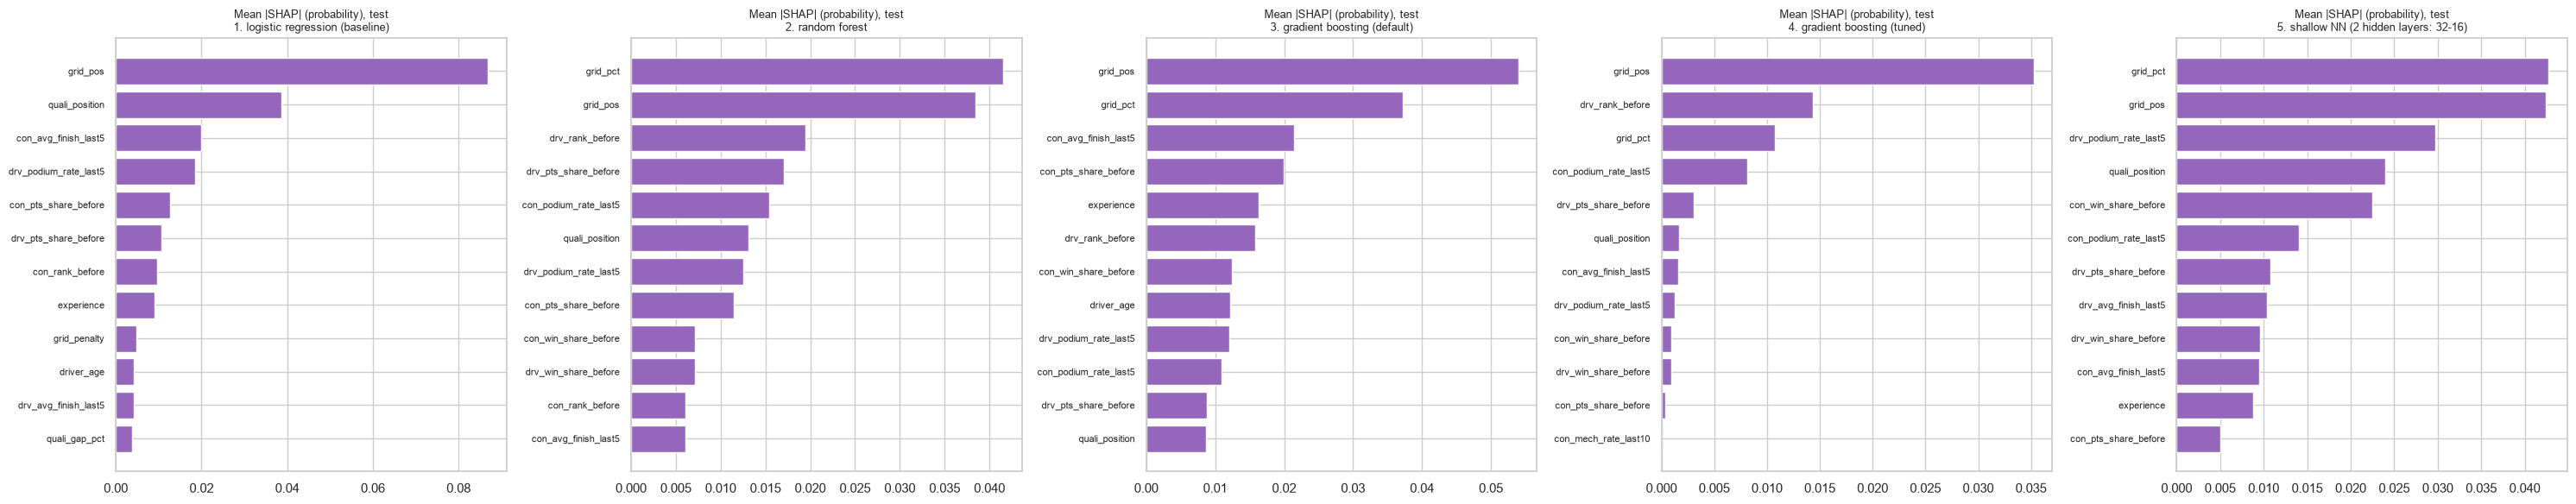

In [ ]:
import shap

# ONE explainer for all five models, as in the lab: SHAP's PermutationExplainer.
# It only needs a function that returns the podium probability (like predict_fn in the lab), so it works for any model.
# Each model's predict_proba already contains its own preprocessing (imputation, and scaling for LR / NN),
# so the explainer works with the ORIGINAL, readable feature values (e.g. grid_pos = 6).

# Background = "a typical driver at prediction time": 100 training rows from 2003–2019, the seasons with complete
# qualifying data, like every row we explain. (With rows from all training seasons, 63% of the background would have no
# qualifying, and every real qualifying value would look like a large contribution.) The base value is the average prediction over them.
background = shap.maskers.Independent(X_train[train["year"] >= 2003], max_samples=100)

# Rows to explain: 300 random test rows, plus the rows we explain one by one in 11.3
# (Verstappen at the 2023 Belgian GP, and each model's most confident wrong prediction).
ver_row = test.index[(test["raceId"] == spa23) & (test["driverId"] == ver)][0]
miss_index = [X_test.index[int(np.argmax(np.where(y_test.values == 0, RESULTS[n]["p"]["test"], -1)))] for n in MODELS]
SHAP_ROWS = sorted(set(X_test.sample(300, random_state=SEED).index) | {ver_row} | set(miss_index))
X_explain = X_test.loc[SHAP_ROWS]

shap_values = {}                                       # model name -> SHAP values of X_explain, in probability
for name, model in MODELS.items():
    def predict_fn(data, model=model):
        """Podium probability of this model for rows of original features (SHAP passes a numpy array)."""
        return model.predict_proba(pd.DataFrame(data, columns=FEATURES))[:, 1]
    explainer = shap.PermutationExplainer(predict_fn, background, seed=SEED)
    shap_values[name] = explainer(X_explain, silent=True)
    # Check: for every row, base value + contributions = the model's probability.
    sv = shap_values[name]
    gap = np.abs(sv.base_values + sv.values.sum(axis=1) - predict_fn(X_explain)).max()
    print(f"{name}: {len(SHAP_ROWS)} rows explained; base value {sv.base_values[0]:.3f}; "
          f"largest gap between base + contributions and the model's probability: {gap:.1e}")

# For the logistic regression the global picture can also be read straight from its weights (standardised inputs):
# the change in log-odds when a column rises by one standard deviation, holding all other columns fixed.
coefs = pd.Series(log_reg.coef_[0], index=PREP_COLUMNS, name="weight (log-odds per 1 std)")
display(coefs.sort_values(key=abs, ascending=False).round(3).to_frame())

def group_of(feature):
    """Name of the feature group a feature belongs to (Section 6)."""
    return next(g for g, cs in FEATURE_GROUPS.items() if feature in cs)

# Beeswarm per model (like shap.summary_plot in the lab)
for k, name in enumerate(MODELS, start=1):
    plt.figure()
    shap.plots.beeswarm(shap_values[name], max_display=12, show=False)
    plt.title(f"SHAP summary (test 2022–2024, {len(SHAP_ROWS)} rows), {name}")
    save_fig(f"22_shap_beeswarm_model{k}")

# Mean |SHAP| per column, and per feature group as a share of each model's total
mean_abs = {name: pd.Series(np.abs(shap_values[name].values).mean(axis=0), index=FEATURES) for name in MODELS}
group_share = pd.DataFrame({name: m.groupby(m.index.map(group_of)).sum() / m.sum() for name, m in mean_abs.items()})
print("Share of each model's total mean |SHAP| per feature group (explained test rows):")
display((100 * group_share).round(1))
top = pd.DataFrame({name: m.sort_values(ascending=False).index[:5] for name, m in mean_abs.items()}, index=[f"#{r}" for r in range(1, 6)])
print("Five features with the largest mean |SHAP| per model:")
display(top)

fig, axes = plt.subplots(1, len(MODELS), figsize=(6 * len(MODELS), 6))
for ax, (name, m) in zip(axes, mean_abs.items()):
    imp = m.sort_values().tail(12)
    ax.barh(imp.index, imp.values, color="tab:purple")
    ax.set_title(f"Mean |SHAP| (probability), test\n{name}", fontsize=9); ax.tick_params(axis="y", labelsize=8)
save_fig("23_shap_bar")

**What the global explanations show** *(read with the plots and tables above)*

* **Starting position dominates every model.** Shuffling the grid group lowers test PR-AUC by 0.217 (network) to 0.363 (tuned gradient boosting), several times more than any other group. In SHAP the grid group has the largest share in every model, from 34.3% (network) to 58.8% (tuned gradient boosting) of each model's total; for the logistic regression it is 37.6%.
* **After grid, the models rely on different groups.** The tree models lean on **standings** (random forest: permutation drop 0.076, SHAP share 33.0%; gradient boosting 25.0–25.2% of SHAP). The logistic regression and the network use **qualifying** much more than the tree models: group drop 0.060 and 0.038, and `quali_position` is clearly important for both (0.053 and 0.033). The tree models hardly use qualifying (drop 0.001–0.009, SHAP share 2.1–8.1%): qualifying is missing in 63% of their training rows, so they split on the grid position, which tells them the same thing in every season. Context contributes almost nothing in any model (group drop at most 0.002).
* **Group vs single feature.** Single features often show a smaller drop than their group, because correlated partners take over when one of them is shuffled (`grid_pos` ↔ `grid_pct`, rank ↔ points share). For example, the logistic regression depends on `grid_pos` (0.279) and hardly on `grid_pct` (0.001, not clearly above 0), the network the other way round (0.056 vs 0.093). This is why the group version is the fairer picture, and it matches the ablation.
* **The background matches the rows we explain (D26).** The 100 background rows come from 2003–2019, so, like every test driver, they have qualifying data. A qualifying contribution therefore compares a real value with real values, not with "missing". For the logistic regression the two largest features by mean |SHAP| are `grid_pos` and `quali_position`, and qualifying has 20.2% of its total (network 11.6%).
* **The logistic-regression weights point in sensible directions for the main features:** a later grid slot (−1.482), a worse qualifying position (−0.333) and a worse constructor average finish (−0.205) lower the prediction; a recent podium habit (+0.161) and a high constructor points share (+0.130) raise it. A few small weights point the "wrong" way, for example `con_mech_rate_last10` (+0.068), `quali_gap_pct` (+0.049) and `drv_avg_finish_last5` (+0.043). These are artefacts of correlated inputs: with grid, qualifying, standings and form already in the model, these columns only describe what is *left over*, and a linear model splits shared information between partners, sometimes with opposite signs. The same holds for the missing-value indicators (+0.880 for a missing Q1 gap, −0.282 each for a missing qualifying position and penalty): they are mostly set together, so only their combination is meaningful. Only the group totals should be read.
* Again: this is how the **models** use the features, not proof that these features **cause** podiums.

### 11.3 Local explanation of one prediction: SHAP waterfall

> 💬 **In plain words.** One prediction, explained step by step: the waterfall starts at the average driver and adds each feature's push up or down until it reaches this driver's prediction. Afterwards we also look at each model's most confident *wrong* prediction, to see what the models cannot know.

We pick a well-known case from the test seasons: **Max Verstappen at the 2023 Belgian GP**. He was fastest in qualifying but took a 5-place gearbox penalty, started 6th, and won. A grid-only view would rate his chances as moderate; let's see how each of the five models reasons, starting with the logistic regression, the recommended model (D24).

In [ ]:
# The driver-race we explain (spa23 and ver were defined in Section 6.4): Verstappen, 2023 Belgian GP.
ver_idx = ver_row                                      # its index in the test set (found in 11.2)
ver_rec = test.loc[[ver_idx]]
display(ver_rec[FEATURES].T.rename(columns={ver_idx: "value"}))
ver_prob = {name: model.predict_proba(ver_rec[FEATURES])[0, 1] for name, model in MODELS.items()}
print(f"Actual podium = {int(ver_rec['podium'].iloc[0])}. Predicted podium probability per model:")
display(pd.Series(ver_prob, name="probability").round(3).to_frame())

def explain_row(name, idx):
    """SHAP values of one explained test row (by its index) for one model, and their sum per feature group."""
    sv = shap_values[name][SHAP_ROWS.index(idx)]
    t = pd.DataFrame({"feature": FEATURES, "value": sv.data, "SHAP": sv.values})
    t["group"] = t["feature"].map(group_of)
    return t.reindex(t["SHAP"].abs().sort_values(ascending=False).index), t.groupby("group")["SHAP"].sum()

# Waterfall per model: starts at the base value and adds each feature's contribution until it reaches the prediction.
for k, name in enumerate(MODELS, start=1):
    plt.figure()
    shap.plots.waterfall(shap_values[name][SHAP_ROWS.index(ver_idx)], max_display=12, show=False)
    plt.title(f"SHAP waterfall: Verstappen, 2023 Belgian GP\n{name} (probability)")
    save_fig(f"24_shap_waterfall_model{k}")

summary = {}
for name in MODELS:
    sv = shap_values[name][SHAP_ROWS.index(ver_idx)]
    summary[name] = {"base value": sv.base_values, "sum of contributions": sv.values.sum(),
                     "base + contributions": sv.base_values + sv.values.sum(), "model probability": ver_prob[name]}
display(pd.DataFrame(summary).T)
print("Contributions summed per feature group:")
display(pd.DataFrame({name: explain_row(name, ver_idx)[1] for name in MODELS}).round(3))
print("Three largest single contributions per model:")
display(pd.DataFrame({name: [f"{r.feature} ({r.SHAP:+.3f})" for r in explain_row(name, ver_idx)[0].head(3).itertuples()]
                      for name in MODELS}, index=["#1", "#2", "#3"]))

# A model what-if (NOT causal): the same record with a different grid slot.
what_if = {}
for g in [1, 6, 10]:
    r = ver_rec[FEATURES].copy()
    r["grid_pos"] = g; r["grid_pct"] = (g - 1) / (ver_rec["field_size"].iloc[0] - 1); r["grid_penalty"] = g - r["quali_position"].iloc[0]
    what_if[f"grid slot {g}"] = {name: model.predict_proba(r)[0, 1] for name, model in MODELS.items()}
print("Model probability when the same record is given another grid slot:")
display(pd.DataFrame(what_if).round(3))

**How to read it** *(numbers from the tables above)*

* **The models agree on the decision but not on the number.** For this race the probabilities are 0.735 (logistic regression), 0.538 (default gradient boosting), 0.513 (network), 0.490 (random forest) and 0.230 (tuned gradient boosting). He won. Each model compares its number with its own threshold, and all five say "podium" (Section 12). The numbers differ because the models are calibrated differently (9.4) and because this row is unusual: pole position, but a start from 6th after a penalty.
* **Each waterfall adds up to its model's probability**: the base value (the average prediction over the 100 background drivers from 2003–2019) plus the contributions. For the logistic regression: 0.155 + 0.580 = 0.735. The base values of the five models are close to each other (0.140–0.157), near the real podium rate.
* **Summed per feature group, almost everything pushes up.** The largest group is qualifying for the logistic regression (+0.176, then standings +0.125 and grid +0.119), standings for the random forest (+0.184), default gradient boosting (+0.199) and tuned gradient boosting (+0.043), and form for the network (+0.162).
* **The logistic regression makes the clearest use of the pole position.** Its two largest contributions are `grid_pos` (+0.118) and `quali_position` (+0.117): it sees both the 6th place on the grid and the pole. `quali_position` is also among the three largest contributions of the random forest (+0.041) and the network (+0.062). For the two gradient-boosting models the qualifying group adds less (+0.046 and +0.004): they learnt their splits mostly on the grid position, so to them P6 looks like P6.
* **What-if (model behaviour, not causal):** given P1 instead of P6 every model goes up (logistic regression 0.840, default gradient boosting 0.836, random forest 0.801, network 0.796, tuned gradient boosting 0.357); given P10 every model goes down (0.623, 0.267, 0.422, 0.410, 0.139). The random forest, default gradient boosting and the network react much more strongly to the grid slot than the logistic regression.

In [ ]:
# Each model's most confident WRONG prediction: the test row with the highest probability that did NOT end on the podium.
info = test.merge(df["drivers"][["driverId", "surname"]], on="driverId", how="left").merge(
    df["races"][["raceId", "name"]], on="raceId", how="left").merge(
    results_clean[["raceId", "driverId", "status", "finish_rank"]], on=["raceId", "driverId"], how="left")
miss_rows, miss_groups = [], {}
for name, idx in zip(MODELS, miss_index):              # miss_index was found in 11.2
    position = X_test.index.get_loc(idx)
    r = info.iloc[position]
    miss_rows.append({"model": name, "driver": r["surname"], "race": f"{int(r['year'])} {r['name']}",
                      "probability": round(float(RESULTS[name]["p"]["test"][position]), 3),
                      "started": int(r["grid_pos"]), "finished": int(r["finish_rank"]), "status": r["status"]})
    miss_groups[name] = explain_row(name, idx)[1]
display(pd.DataFrame(miss_rows).set_index("model"))
print("SHAP contributions of each model's most confident miss, summed per feature group:")
display(pd.DataFrame(miss_groups).round(3))

**What the wrong predictions show** *(numbers from the output above)*

Three of the five models make their most confident mistake on the same race: **Verstappen at the 2024 Australian GP** (logistic regression 0.849, random forest 0.803, network 0.801): pole position, leading both championships, and he retired with a brake failure. Default gradient boosting's most confident miss is Verstappen at the 2022 British GP (0.896; started 2nd, finished 7th), and tuned gradient boosting's is Leclerc at the 2022 Spanish GP (pole position, retired with a turbo failure), which it rated only 0.357 because its outputs stay near the average (9.4). In every case the grid group pushed the probability up the most (logistic regression +0.313, random forest +0.255, network +0.238, default gradient boosting +0.221, tuned gradient boosting +0.130). Nothing in the pre-race data could have announced a component failure, which is exactly the kind of upset our limitations section describes: the models rank the field well but cannot foresee breakdowns or crashes.

### 11.4 Local explanation of the same prediction: LIME

> 💬 **In plain words.** LIME explains the same prediction a different way: it makes thousands of slightly changed copies of the driver's row, asks the model about each one, and fits a simple straight-line model to those answers. That simple model's weights are the explanation. It is an approximation, so we check how well it fits and whether it stays the same across random seeds.

LIME explains one prediction differently. It creates thousands of slightly changed copies of the row, asks the model for their predictions, and fits a small **linear model** around this one point; that local model's weights are the explanation. Two things to know when reading it:
* LIME describes each feature by a **range** (by default the quartiles of the training data, e.g. `grid_pos ≤ 6`), not by its exact value, and changes features **independently**, so some of its synthetic rows are combinations that never happen (e.g. pole position in a back-marker car).
* It is random: we run it with **5 seeds** per model and report how stable the result is, and we print the local model's own prediction next to the real model's prediction.

LIME needs complete numeric rows, so missing values are filled with the training medians before perturbing.

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

# LIME samples new rows around the instance using the training data statistics, which must not contain NaN.
median_filler = SimpleImputer(strategy="median").fit(X_train)
lime_train = median_filler.transform(X_train)
ver_filled = median_filler.transform(ver_rec[FEATURES])[0]

lime_weights, lime_stats, lime_exp = {}, [], {}
for name, model in MODELS.items():                     # the same LIME explainer for all five models, as in the lab
    def predict_fn(data, model=model):
        """Probabilities of both classes (no podium, podium) for rows of original features (LIME passes a numpy array)."""
        return model.predict_proba(pd.DataFrame(data, columns=FEATURES))
    runs = {}
    for s in [SEED, 0, 1, 2, 3]:
        expl = LimeTabularExplainer(lime_train, feature_names=FEATURES, class_names=["no podium", "podium"],
                                    mode="classification", discretize_continuous=True, random_state=s)
        # 5,000 perturbed copies of the row are scored by the model; LIME fits a weighted linear model to those scores.
        e = expl.explain_instance(ver_filled, predict_fn, num_features=10, num_samples=5000)
        runs[s] = dict(e.as_list())
        if s == SEED:
            lime_exp[name] = e                         # kept to show LIME's own picture below
        lime_stats.append({"model": name, "seed": s, "local model R²": e.score, "LIME local prediction": e.local_pred[0]})
    runs = pd.DataFrame(runs)
    lime_weights[name] = runs.assign(**{"mean weight": runs.mean(axis=1), "seeds in top 10": runs.notna().sum(axis=1)})

stats = pd.DataFrame(lime_stats).groupby("model")[["local model R²", "LIME local prediction"]].agg(["mean", "min", "max"])
stats[("model probability", "")] = pd.Series(ver_prob)
print("How well LIME's local linear model fits each model at this row (5 seeds):")
display(stats.loc[list(MODELS)].round(3))
print("Five largest LIME weights per model (mean over 5 seeds; in brackets: in how many seeds the condition was in the top 10):")
display(pd.DataFrame({name: [f"{c} ({w['mean weight']:+.3f}, {int(w['seeds in top 10'])}/5)" for c, w in
                             t.reindex(t["mean weight"].abs().sort_values(ascending=False).index).head(5).iterrows()]
                      for name, t in lime_weights.items()}, index=[f"#{r}" for r in range(1, 6)]))

fig, axes = plt.subplots(1, len(MODELS), figsize=(6 * len(MODELS), 5))
for ax, (name, t) in zip(axes, lime_weights.items()):
    w = t[SEED].dropna().sort_values()
    ax.barh(w.index, w.values, color=np.where(w.values > 0, "tab:green", "tab:red"))
    ax.axvline(0, color="black", lw=0.8); ax.tick_params(axis="y", labelsize=8)
    ax.set_title(f"LIME (seed {SEED}), {name}\nmodel probability {ver_prob[name]:.2f}", fontsize=9)
    ax.set_xlabel("weight in LIME's local linear model")
save_fig("25_lime")

In [ ]:
from IPython.display import display, HTML

# LIME's own picture for each model (as in the lab): the model's predicted probabilities (left),
# the conditions that push towards "no podium" or "podium" with their weights (middle), and the driver's values (right).
# as_html + display(HTML(...)) shows the same picture as show_in_notebook, and also works when the notebook is run as a script.
for name in MODELS:
    print(name)
    display(HTML(lime_exp[name].as_html(show_table=True)))

**SHAP vs LIME for this prediction** *(numbers from the outputs above)*

* **The main reason agrees.** For every model the largest LIME weight is `grid_pos ≤ 6` (+0.076 to +0.131), in the top 10 for all 5 seeds. Next come standings conditions for the tree models (`drv_rank_before ≤ 6`, `con_pts_share_before > 0.45`) and `grid_penalty > 0` for the logistic regression and the network. These are the same features SHAP pointed to, with the same direction, and both methods are in probability.
* **But LIME's local model fits most models badly.** Its mean R² is 0.700 for the logistic regression, 0.523 for the random forest, 0.453 for the network and 0.337 for default gradient boosting. Its own prediction for this row is 0.279 for the logistic regression, 0.309 for the network, 0.284 for default gradient boosting and 0.339 for the random forest, while the real models say 0.735, 0.513, 0.538 and 0.490. The reason is LIME's sampling: it draws synthetic rows from the whole training distribution (mostly midfield and back-marker cars with near-zero podium chances) and fits one straight line through them, which cannot follow a model's steep rise near this row. Tuned gradient boosting is the exception (R² 0.876, local prediction 0.223 vs model 0.230) only because its output barely changes, so a straight line fits it easily.
* **SHAP is the more trustworthy local explanation here.** Its contributions add up exactly to each model's probability (the check in 11.2 shows gaps of at most 1e-8), while LIME's local line is an approximation that, in this case, is visibly poor. Where both agree — starting near the front, the penalty signalling real pace, and season-long strength drive this prediction — we can be confident in the explanation. And once more: these explain the **models'** reasoning, not what *causes* a podium.

## 12. Inference functions

> 💬 **In plain words.** There is one function per model, for example `predict_podium_lr` for the logistic regression. A user calls it before a race with what is known about one driver (at minimum the grid slot and the number of cars) and gets back the podium probability and a yes/no answer. Every function rejects impossible inputs, fills missing values exactly as in training, and lists which features were missing, so the user knows how much to trust the answer.

🔶 **Decision D27 — one inference function per model.** `predict_podium_lr`, `predict_podium_rf`, `predict_podium_gb_default`, `predict_podium_gb_tuned` and `predict_podium_nn` each take one driver's pre-race information as a dictionary and return the podium probability and a yes/no decision.
* Each function uses **its own fitted model** from Section 9 (with that model's preprocessing) and **its own validation-tuned threshold** (D22). How far the probability can be read literally depends on the model's calibration (Section 9.4): tuned gradient boosting keeps its outputs near the average. The logistic regression is the recommended model (D24) and is shown first, with both demos printed in full.
* The input checks are shared by all five functions (`prepare_record`), so every model receives exactly the same row:
  * **Required inputs:** `grid_pos` and `field_size`, because the starting position is the backbone of every prediction. A raw grid value of 0 is read as a pit-lane start (D7): it becomes the last slot. `field_size` and `pit_lane_start` are accepted as inputs although they are not model features: `field_size` is needed to compute `grid_pct`, and a pit-lane start maps to the last slot (D7).
  * **Derived inputs** are filled in when absent, with the same formulas as Section 6: `grid_pct` from grid slot and field size, `grid_penalty` from grid slot and qualifying position.
  * **Other missing values are allowed.** They become NaN and the model's own fitted preprocessing fills them exactly as during training: the training **median**, plus a "was missing" indicator for every column that had missing values in training. The function reports which features were missing, because a prediction made on part of the information should be trusted less.
  * Unknown keys and impossible values (grid slot outside the field or not a whole number, a field of fewer than 2 cars, shares and rates outside 0–1, a `grid_pct` that contradicts the grid slot) raise an error instead of being silently accepted (a typo like `grid_position` would otherwise be treated as "missing").

In [ ]:
# How the inference functions work (the same chain for all five models):
#   predict_podium_xx(record)  ->  podium_answer(model name, record)
#        -> prepare_record(record): checks the inputs and builds one row with the 18 model features (missing = NaN)
#        -> MODELS[name].predict_proba(row): the model's own imputation (+ scaling) and the model itself
#        -> compare the probability with that model's threshold from validation (D22)
SHARE_FEATURES = [f for f in FEATURES if any(k in f for k in ("share", "rate", "finish")) or f == "grid_pct"]   # must lie in 0–1
INPUTS = FEATURES + ["field_size", "pit_lane_start"]     # field_size gives grid_pct; pit_lane_start / raw grid 0 = last slot (D7)

def prepare_record(record):
    """Check one driver's pre-race record and complete the derived features (shared by the five inference functions).
    record: dict {input name: value}. Must contain grid_pos and field_size; any other subset of INPUTS may be given.
    Returns a one-row DataFrame with all FEATURES (missing values as NaN) and the list of missing features."""
    unknown = set(record) - set(INPUTS)
    if unknown:
        raise ValueError(f"Unknown feature names: {sorted(unknown)}. Valid names: {INPUTS}")
    for req in ["grid_pos", "field_size"]:
        if record.get(req) is None:
            raise ValueError(f"'{req}' is required")
    row = pd.DataFrame([{f: record.get(f, np.nan) for f in INPUTS}]).astype(float)   # None -> NaN
    r = row.iloc[0]
    if r["field_size"] < 2 or r["field_size"] != int(r["field_size"]):
        raise ValueError(f"field_size must be a whole number of at least 2, got {r['field_size']}")
    if r["grid_pos"] != int(r["grid_pos"]):
        raise ValueError(f"grid_pos must be a whole number, got {r['grid_pos']}")
    if pd.notna(r["quali_position"]) and not 1 <= r["quali_position"] <= r["field_size"] + 10:
        raise ValueError(f"quali_position {r['quali_position']} is not plausible for a field of {r['field_size']:.0f}")
    if r["grid_pos"] == 0:                                     # raw Ergast grid 0 = pit-lane start (D7)
        row["grid_pos"], row["pit_lane_start"] = r["field_size"], 1.0
    elif pd.isna(r["pit_lane_start"]):
        row["pit_lane_start"] = 0.0
    r = row.iloc[0]
    if not 1 <= r["grid_pos"] <= r["field_size"]:
        raise ValueError(f"grid_pos must be between 1 and field_size ({r['field_size']:.0f}), got {r['grid_pos']}")
    # Derive features that follow directly from other inputs (same formulas as Section 6)
    expected_pct = (r["grid_pos"] - 1) / (r["field_size"] - 1)
    if pd.notna(r["grid_pct"]) and abs(r["grid_pct"] - expected_pct) > 1e-6:
        raise ValueError(f"grid_pct {r['grid_pct']} contradicts grid_pos/field_size (expected {expected_pct:.4f})")
    row["grid_pct"] = expected_pct
    if pd.isna(r["grid_penalty"]) and pd.notna(r["quali_position"]):
        row["grid_penalty"] = r["grid_pos"] - r["quali_position"]
    bad = [f for f in SHARE_FEATURES if pd.notna(row.at[0, f]) and not 0 <= row.at[0, f] <= 1]
    if bad:
        raise ValueError(f"these features must be between 0 and 1: {bad}")
    return row[FEATURES], [f for f in FEATURES if pd.isna(row.at[0, f])]

def podium_answer(model_name, record):
    """Probability from the named model (with its own preprocessing) and the decision at its validation-tuned threshold."""
    row, missing = prepare_record(record)
    prob = float(MODELS[model_name].predict_proba(row)[0, 1])
    threshold = RESULTS[model_name]["thr"]
    return {"podium_probability": round(prob, 3), "predicted_podium": bool(prob >= threshold),
            "threshold": round(threshold, 3), "model": model_name, "missing_features": missing}

# DECISION D27 → see DECISIONS.md  (one inference function per model; shared input checks; the model's own imputation)
def predict_podium_lr(record):
    """Podium prediction with model 1, the logistic regression (baseline)."""
    return podium_answer(BASELINE, record)

def predict_podium_rf(record):
    """Podium prediction with model 2, the random forest."""
    return podium_answer("2. random forest", record)

def predict_podium_gb_default(record):
    """Podium prediction with model 3, gradient boosting with default settings."""
    return podium_answer("3. gradient boosting (default)", record)

def predict_podium_gb_tuned(record):
    """Podium prediction with model 4, gradient boosting with the settings tuned on validation."""
    return podium_answer("4. gradient boosting (tuned)", record)

def predict_podium_nn(record):
    """Podium prediction with model 5, the shallow neural network."""
    return podium_answer(NN_NAME, record)

INFERENCE = {BASELINE: predict_podium_lr, "2. random forest": predict_podium_rf, "3. gradient boosting (default)": predict_podium_gb_default,
             "4. gradient boosting (tuned)": predict_podium_gb_tuned, NN_NAME: predict_podium_nn}

# Demo records: one complete record, and one realistic partially-missing record (a debutant in the test seasons:
# grid, qualifying and team data are known, but he has no past races, so his own form is missing, as for every debutant in training).
def as_record(rows):
    """The model inputs of one driver-race row as a dict, leaving out the values that are missing."""
    return {f: float(v) for f, v in rows[INPUTS].iloc[0].items() if pd.notna(v) and f != "pit_lane_start"}
complete = as_record(ver_rec)                                                    # Verstappen, 2023 Belgian GP (test set)
debut = test[(test["experience"] == 0) & test["quali_position"].notna()].sort_values(["date", "grid_pos"]).head(1)
debut_name = df["drivers"].set_index("driverId").loc[debut["driverId"].iloc[0], ["forename", "surname"]].str.cat(sep=" ")
debut_race = df["races"].set_index("raceId").loc[debut["raceId"].iloc[0], ["year", "name"]].astype(str).str.cat(sep=" ")
partial = as_record(debut)
print(f"Partially-missing record: {debut_name}, {debut_race}, his first race (actual podium = {int(debut['podium'].iloc[0])})")
demos = {"1. complete record (Verstappen, Spa 2023)": complete,
         f"2. debutant, own form missing ({debut_name}, {debut_race})": partial,
         "3. same debutant from the pit lane (raw grid 0)": {**{k: v for k, v in partial.items() if k not in ("grid_pct", "grid_penalty")}, "grid_pos": 0}}

print("Logistic regression (the recommended model, D24), complete record:")
print(json.dumps(predict_podium_lr(complete), indent=2))
print("\nLogistic regression, partially-missing record:")
print(json.dumps(predict_podium_lr(partial), indent=2))

def answer_text(a):
    """'0.745 (podium)': the probability and the decision at that model's own threshold."""
    return f"{a['podium_probability']:.3f} ({'podium' if a['predicted_podium'] else 'no'})"

# Column names carry each model's threshold, so every probability can be compared with its own cut-off.
with_threshold = {name: f"{name}, threshold {RESULTS[name]['thr']:.3f}" for name in INFERENCE}
answers = {with_threshold[name]: {d: answer_text(fn(rec)) for d, rec in demos.items()} for name, fn in INFERENCE.items()}
print("\nProbability (and decision at each model's own threshold) from every inference function:")
display(pd.DataFrame(answers))

# Why does the probability change when parts are missing? Remove one block at a time.
decomp = {}
for label, drop in [("nothing missing", []), ("qualifying missing", FEATURE_GROUPS["qualifying"]), ("form missing", FEATURE_GROUPS["form"]),
                    ("qualifying and form missing", FEATURE_GROUPS["qualifying"] + FEATURE_GROUPS["form"])]:
    rec = {k: v for k, v in complete.items() if k not in drop}
    decomp[label] = {with_threshold[name]: answer_text(fn(rec)) for name, fn in INFERENCE.items()}
print("Verstappen, Spa 2023, with blocks of features removed:")
display(pd.DataFrame(decomp).T)
print("Training medians used for missing form values:",
      {f: round(float(v), 3) for f, v in zip(FEATURES, imputer.statistics_) if f in FEATURE_GROUPS["form"]})

# The input checks: a typo and an impossible value are rejected by every function.
for bad_record in [{"grid_position": 3, "field_size": 20}, {"grid_pos": 25, "field_size": 20}]:
    try:
        predict_podium_lr(bad_record)
    except ValueError as err:
        print("Rejected:", err)

Training medians used for missing form values: {'drv_podium_rate_last5': 0.0, 'drv_avg_finish_last5': 0.51, 'con_podium_rate_last5': 0.0, 'con_avg_finish_last5': 0.511, 'con_mech_rate_last10': 0.25}
Rejected: Unknown feature names: ['grid_position']. Valid names: ['grid_pos', 'grid_pct', 'quali_position', 'quali_gap_pct', 'grid_penalty', 'drv_pts_share_before', 'drv_rank_before', 'drv_win_share_before', 'con_pts_share_before', 'con_rank_before', 'con_win_share_before', 'drv_podium_rate_last5', 'drv_avg_finish_last5', 'con_podium_rate_last5', 'con_avg_finish_last5', 'con_mech_rate_last10', 'driver_age', 'experience', 'field_size', 'pit_lane_start']
Rejected: grid_pos must be between 1 and field_size (20), got 25.0


**What this shows** *(numbers from the output above)*

* **Complete record (Verstappen, Spa 2023):** the logistic regression gives 0.735 → "podium" (he won). Every function says "podium", with probabilities from 0.230 (tuned gradient boosting) to 0.735 (logistic regression). Each function compares its probability with its own threshold (from 0.212 for tuned gradient boosting to 0.398 for default gradient boosting), so the decisions agree even though the numbers do not. All except tuned gradient boosting give numbers that can be read as probabilities (9.4).
* **Partially-missing record, a real debutant (Guanyu Zhou, 2022 Bahrain GP, his first race):** his own form is missing (`drv_podium_rate_last5`, `drv_avg_finish_last5`), exactly as for every debutant in training. The logistic regression gives 0.004 → "no podium", and every function agrees (0.001–0.087). He did not podium. From the pit lane (raw grid 0, the same debutant): 0.000–0.087, again "no". Tuned gradient boosting gives 0.087 in both cases, because its outputs barely move away from the average.
* **Breakdown table (a documented limitation):** Verstappen's record with blocks of features removed. The models react differently to the same missing information:
  * For the **logistic regression** the prediction falls step by step: 0.735 → 0.603 without qualifying (it no longer knows he qualified on pole; the position is filled with the training median and the "was missing" flag is set) → 0.539 without form → 0.391 without both. It still says "podium" in every case. The random forest falls the same way (0.490 → 0.287).
  * Both **gradient-boosting** models fall below their threshold once form is missing (default 0.206, tuned 0.173).
  * The **network** does the opposite: its prediction *rises* (0.513 → 0.676 without qualifying, 0.851 without form, 0.833 without both). Without qualifying, the record looks like a row from the seasons before 1994, where the "was missing" indicators are always set, and a 2023 championship leader with that pattern never occurred in training; the network extrapolates from the old-era rows instead.
  * The lesson: **imputed predictions are only as good as the training data's examples of that missing pattern.** That is why every function lists the missing features.
* **Input checks:** a misspelt feature name and a grid slot outside the field are rejected with a clear error instead of being treated as missing.

## 13. Summary and limitations

### Results

* **Data:** 26,759 raw result rows → 24,715 driver-race rows of cars that were on the grid at the prediction cutoff (Indianapolis 500 and failed qualifiers removed, one row per driver per race). The models train on 1950–2019 (22,576 rows), validate on 2020–2021 and are tested on 2022–2024.
* **Training window:** every season from 1950 is used. No later start year improved validation PR-AUC, and starting in 1994 is significantly worse (8.4); median imputation with missing indicators beats a grid fallback for the missing qualifying values (8.5); and the grid position carries the qualifying information for the seasons before 1994 (6.7).
* **Q1:** front-row starts convert more often after 2014 (68.0% → 75.9%, significant); Monaco/Monza (2003–13) and Suzuka (2014–24) convert best, but individual circuits are not statistically distinguishable, so a change in the circuit ranking cannot be shown; a front-row qualifier moved back by a penalty podiums far less often (28%) than one who starts there (73%).
* **Q2:** the raw home "disadvantage" (−2.1 pp) shrinks to −0.8 pp once grid and era are controlled; logistic odds ratio 0.93 (0.79–1.11). No evidence of a home advantage.
* **Q3:** with teams grouped by lineage, mechanical retirements fell from 8.9% of starts (2014–2021) to 5.5% (2022–2024); Caterham, Toro Rosso → AlphaTauri → RB and Lotus F1 → Renault → Alpine highest in 2014–2021 (teams differ clearly), Lotus F1 → Renault → Alpine and Sauber ↔ Alfa Romeo highest in 2022–2024, where team differences are not significant (p = 0.18).
* **Features:** 21 candidates are built and checked; the 3 with no signal (`pit_lane_start`, `home_race`, `field_size`) are not model inputs, so the models use 18 features (32 columns after imputation). Adding them back never helps significantly (D30).
* **Models:** the learned models reach validation PR-AUC 0.716–0.736 and test 0.693–0.722 against 0.639 / 0.645 for the grid-only rule (the baseline's gain over the grid rule is significant). None beats the logistic-regression baseline by more than noise, so the **logistic regression is the recommended model** (D24): on test it ties the random forest for the best score (PR-AUC 0.722, ROC-AUC 0.937), it is deterministic and well calibrated (Brier 0.068). No model uses class weights. Every model has its own ablation, explanations and inference function.
* **Ablation and XAI:** starting position is the backbone of every model (grid alone loses 0.084–0.100 validation PR-AUC against all features); the other groups add information together but substitute for each other. After grid, the tree models rely on standings, while the logistic regression and the network use qualifying much more than the tree models.

### Why each feature is valid at the pre-race cutoff

| feature group | known before lights out because… |
|---|---|
| grid | the starting grid is fixed after qualifying and penalties |
| qualifying | qualifying happens before the race; the gap uses Q1 laps only; on 2021–22 sprint weekends the penalty is measured against the sprint result, which is also before the race |
| standings | taken from the **previous** race's table (or the previous season's final table), never the current race's (D13) |
| form | rolling windows over **earlier** races only; `shift(1)` keeps the current race out (D14) |
| context | date of birth and the number of earlier races are known beforehand |

Automatic checks in Section 6 confirm this: every standings row comes from an earlier race, a hand-recomputed form value matches the feature, and no post-race column is in the feature list.

### Known limitations

* **Qualifying coverage.** Qualifying data starts in 1994 and is patchy until 2002, so 63% of the training rows have no qualifying position and the models learn the qualifying features from the recent seasons only; the missing-value indicators let them treat the other rows differently, and the grid position carries the start for every season. The oldest seasons are the hardest to predict (grid rule 0.389–0.455 per period before 1994, per-period table in 9.4).
* **Era sensitivity.** The sport changed (rules, reliability, field size). We trained on 1950–2019; the per-period table shows the same model ranks some eras much better than others, and the 2022–2024 test (new ground-effect rules) shows it still transfers. A future rule change may not.
* **Small evaluation sets.** Validation has 39 races and test 68, so PR-AUC intervals are about ±0.06–0.11 wide; differences between our learned models are inside them. Validation scores are also slightly optimistic because validation was used for several choices.
* **Independent predictions.** Each driver is scored alone; nothing forces exactly three podiums per race, so the baseline's yes/no output predicts about 4.0 podiums per race on validation and 4.8 on test.
* **Probabilities of tuned gradient boosting cannot be read literally.** Its outputs stay near the average (validation Brier 0.094, 9.4); they are useful for ranking drivers, and its inference function still gives sensible decisions because it uses its own threshold.
* **Missing race-day factors.** Weather, tyre strategy, safety cars, crashes and breakdowns are not in the data and cause many upsets (e.g. the most confident misses in 11.3).
* **Missing-value patterns at inference.** A record whose missing values form a pattern the training data never had (e.g. a 2023 championship leader without qualifying or form data) gets an unreliable prediction: the network's probability even rises when information is removed (Section 12).
* **Team identity.** Renamed constructors get a new `constructorId`, so their form history restarts (Q3 groups them by lineage; the features do not).
* **Data quirks we documented but could not fully fix:** shared drives in the 1950s (D4); vacant positions after disqualifications (D8); the broken race times of the 2024 Belgian GP (3.2); some cars that failed *before* the start are coded as 0-lap retirements, so they count as race starts (the data cannot tell them apart from first-lap failures); for raw grid 0 the pit-lane/non-starter distinction uses the laps column (D7); a championship exclusion decided at season end is flagged in every table of that season (handled in D13).
* **Explanations are not causal** (Section 11).